In [89]:
import pandas as pd
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , PolynomialFeatures
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.metrics import classification_report


In [90]:
DATA_PATH = 'final_feature_matrix.csv'

In [91]:
def prepare_data(df, val_size=10, random_seed=42):
    """
    Prepares the dataset for training by:
    - Dropping non-predictive metadata (IDs)
    - Encoding categorical variables (Gender)
    - Imputing missing values with column means
    - Splitting features (X) from the target label (y)
    - Creating a stratified train/validation split
    - Normalizing features to prevent data leakage
    """
    print("Preparing data...")
    
    # Isolate target variable and drop it from features alongside the Subject ID
    y = df['Label']
    X = df.drop(columns=['Subject Number', 'Label'], errors='ignore')
        
    # One-Hot Encode categorical variables (e.g., 'Gender_M', 'Gender_F' -> 0/1)
    if 'Gender' in X.columns:
        X = pd.get_dummies(X, columns=['Gender'], drop_first=True).astype(float)
        

    
    # --- Stratified split for the validation set ---
    # Setting test_size=10 and stratify=y guarantees 5 from Class 1 and 5 from Class 0
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, 
        test_size=val_size, 
        stratify=y, 
        random_state=random_seed
    )
    
    # --- NEW: Normalize the data ---
    scaler = StandardScaler()
    
    # Fit on training data and transform it
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train), 
        columns=X_train.columns, 
        index=X_train.index
    )
    
    # Transform validation data using the training data's parameters
    X_val_scaled = pd.DataFrame(
        scaler.transform(X_val), 
        columns=X_val.columns, 
        index=X_val.index
    )
    
    print(f"Split complete:")
    print(f"  Training set: {len(X_train_scaled)} subjects ({sum(y_train==1)} Class 1, {sum(y_train==0)} Class 0)")
    print(f"  Validation set: {len(X_val_scaled)} subjects ({sum(y_val==1)} Class 1, {sum(y_val==0)} Class 0)")
    
    return X_train_scaled, X_val_scaled, y_train, y_val

In [117]:


def evaluate_logreg_with_kfold(K_FOLDS=5, use_l1=True, C_value=1.0, max_iter=10000):
    """
    Evaluates Logistic Regression and displays a logically grouped 2x4 dashboard 
    showing CV metrics, feature distributions, fold accuracies, and validation results.
    Fully updated for scikit-learn 1.8+ (No 'penalty' warning).
    """
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # Unpack all four variables
    X_train, X_val, y_train, y_val = prepare_data(df)

    # --- FIX: Strictly follow Scikit-Learn 1.8+ rules ---
    # We remove the 'penalty' argument entirely from the model below.
    if C_value == 0 or C_value is None:
        c_setting = np.inf         # C=inf is the new way to say penalty=None (lambda=0)
        l1_ratio_setting = None    # Ignored when C is infinite
        penalty_display = "None (λ=0)"
        c_display = "N/A"
    else:
        c_setting = C_value
        l1_ratio_setting = 1.0 if use_l1 else 0.0 # 1.0 = L1, 0.0 = L2
        penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
        c_display = str(C_value)
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('log_reg', LogisticRegression(
            l1_ratio=l1_ratio_setting,  # Controls L1 vs L2       
            C=c_setting,                # Controls Regularization Strength (or disables it)
            solver='saga',          
            max_iter=max_iter, 
            random_state=42
        ))
    ])

    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # Apply CV to the training set
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring='accuracy')
    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy)

    # Fit pipeline for coefficients & validation
    pipeline.fit(X_train, y_train)
    y_val_pred = pipeline.predict(X_val)

    # --- Metrics DataFrames ---
    metrics_df = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1", "CV Mean Acc"],
        "Score": [
            accuracy_score(y_train, y_pred),
            precision_score(y_train, y_pred, average='weighted', zero_division=0),
            recall_score(y_train, y_pred, average='weighted', zero_division=0),
            f1_score(y_train, y_pred, average='weighted', zero_division=0),
            cv_scores.mean()
        ]
    })

    fold_df = pd.DataFrame({
        "Fold": [f"Fold {i+1}" for i in range(K_FOLDS)],
        "Accuracy": cv_scores
    })

    coefs = pd.DataFrame({
        'Feature': X_train.columns,
        'Coefficient': pipeline.named_steps['log_reg'].coef_[0]
    }).sort_values(by='Coefficient', ascending=False)

    # Calculate Validation Metrics for the new subplot
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted', zero_division=0)
    
    val_metrics_df = pd.DataFrame({
        "Metric": ["Val Accuracy", "Val F1 Score"],
        "Score": [val_acc, val_f1]
    })

    # Terminal Output (Kept for logging)
    print("\n" + "="*45)
    print("VALIDATION SET RESULTS (10 Held-out Subjects)")
    print("="*45)
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation F1 Score: {val_f1:.4f}\n")

    sns.set_theme(style="whitegrid", palette="muted") 
    
    # Increased width to 26 to comfortably fit 4 columns
    fig, axes = plt.subplots(2, 4, figsize=(26, 12))
    
    # Dynamic title based on penalty settings
    fig.suptitle(f'Logistic Regression Evaluation Dashboard | Penalty: {penalty_display} | C = {c_display}', 
                 fontsize=22, fontweight='bold', y=0.98)
    
    # --- COLUMN 1: Confusion Matrices ---
    # Top: CV Confusion Matrix
    sns.heatmap(confusion_matrix(y_train, y_pred), annot=True, fmt='d', cmap='Greens', ax=axes[0, 0],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['TD (Pred)', 'ASD (Pred)'], yticklabels=['TD (Act)', 'ASD (Act)'])
    axes[0, 0].set_title('CV Confusion Matrix (Train)', fontsize=15, fontweight='bold')
    axes[0, 0].tick_params(axis='both', labelsize=12)

    # Bottom: Validation Confusion Matrix
    sns.heatmap(confusion_matrix(y_val, y_val_pred), annot=True, fmt='d', cmap='Blues', ax=axes[1, 0],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['TD (Pred)', 'ASD (Pred)'], yticklabels=['TD (Act)', 'ASD (Act)'])
    axes[1, 0].set_title('Validation Confusion Matrix (Holdout)', fontsize=15, fontweight='bold')
    axes[1, 0].tick_params(axis='both', labelsize=12)


    # --- COLUMN 2: Performance Metrics ---
    # Top: CV Metrics
    sns.barplot(x='Score', y='Metric', data=metrics_df, ax=axes[0, 1], hue='Metric', palette='magma', legend=False)
    axes[0, 1].set_title('CV Performance Metrics', fontsize=15, fontweight='bold')
    axes[0, 1].set_xlim(0, 1.1)
    axes[0, 1].set_ylabel('')
    for i in axes[0, 1].containers:
        axes[0, 1].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')

    # Bottom: NEW Validation Metrics Subplot
    sns.barplot(x='Score', y='Metric', data=val_metrics_df, ax=axes[1, 1], hue='Metric', palette='flare', legend=False)
    axes[1, 1].set_title('Validation Metrics (Holdout)', fontsize=15, fontweight='bold')
    axes[1, 1].set_xlim(0, 1.1)
    axes[1, 1].set_ylabel('')
    for i in axes[1, 1].containers:
        axes[1, 1].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')


    # --- COLUMN 3: Feature Interpretability ---
    # Top: Feature Importance
    sns.barplot(x='Coefficient', y='Feature', data=coefs, ax=axes[0, 2], hue='Feature', palette='mako', legend=False)
    axes[0, 2].set_title('Feature Importance (Coefficients)', fontsize=15, fontweight='bold')
    axes[0, 2].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
    axes[0, 2].set_ylabel('')

    # Bottom: Coefficient Distribution
    sns.histplot(coefs['Coefficient'], kde=True, color='#8e44ad', ax=axes[1, 2], bins=15, line_kws={'linewidth': 2})
    axes[1, 2].set_title('Coefficient Distribution', fontsize=15, fontweight='bold')
    axes[1, 2].set_xlabel('Coefficient Value', fontsize=12)
    axes[1, 2].set_ylabel('Frequency', fontsize=12)


    # --- COLUMN 4: Cross-Validation Details ---
    # Top: Per-Fold Accuracy
    bars = sns.barplot(x='Fold', y='Accuracy', data=fold_df, ax=axes[0, 3], hue='Fold', palette='crest', legend=False)
    axes[0, 3].set_title('Cross-Validation Accuracy per Fold', fontsize=15, fontweight='bold')
    axes[0, 3].set_ylim(0, 1.1)
    axes[0, 3].set_xlabel('')
    axes[0, 3].axhline(cv_scores.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {cv_scores.mean():.2f}')
    axes[0, 3].legend(loc='upper right')
    for i in axes[0, 3].containers:
        axes[0, 3].bar_label(i, fmt='%.3f', padding=4, size=12)

    # Bottom: Empty (Turn off the axis so it stays clean)
    axes[1, 3].axis('off')


    # Final layout adjustments
    sns.despine() 
    plt.tight_layout()
    fig.subplots_adjust(top=0.90) 
    plt.show() 


Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000



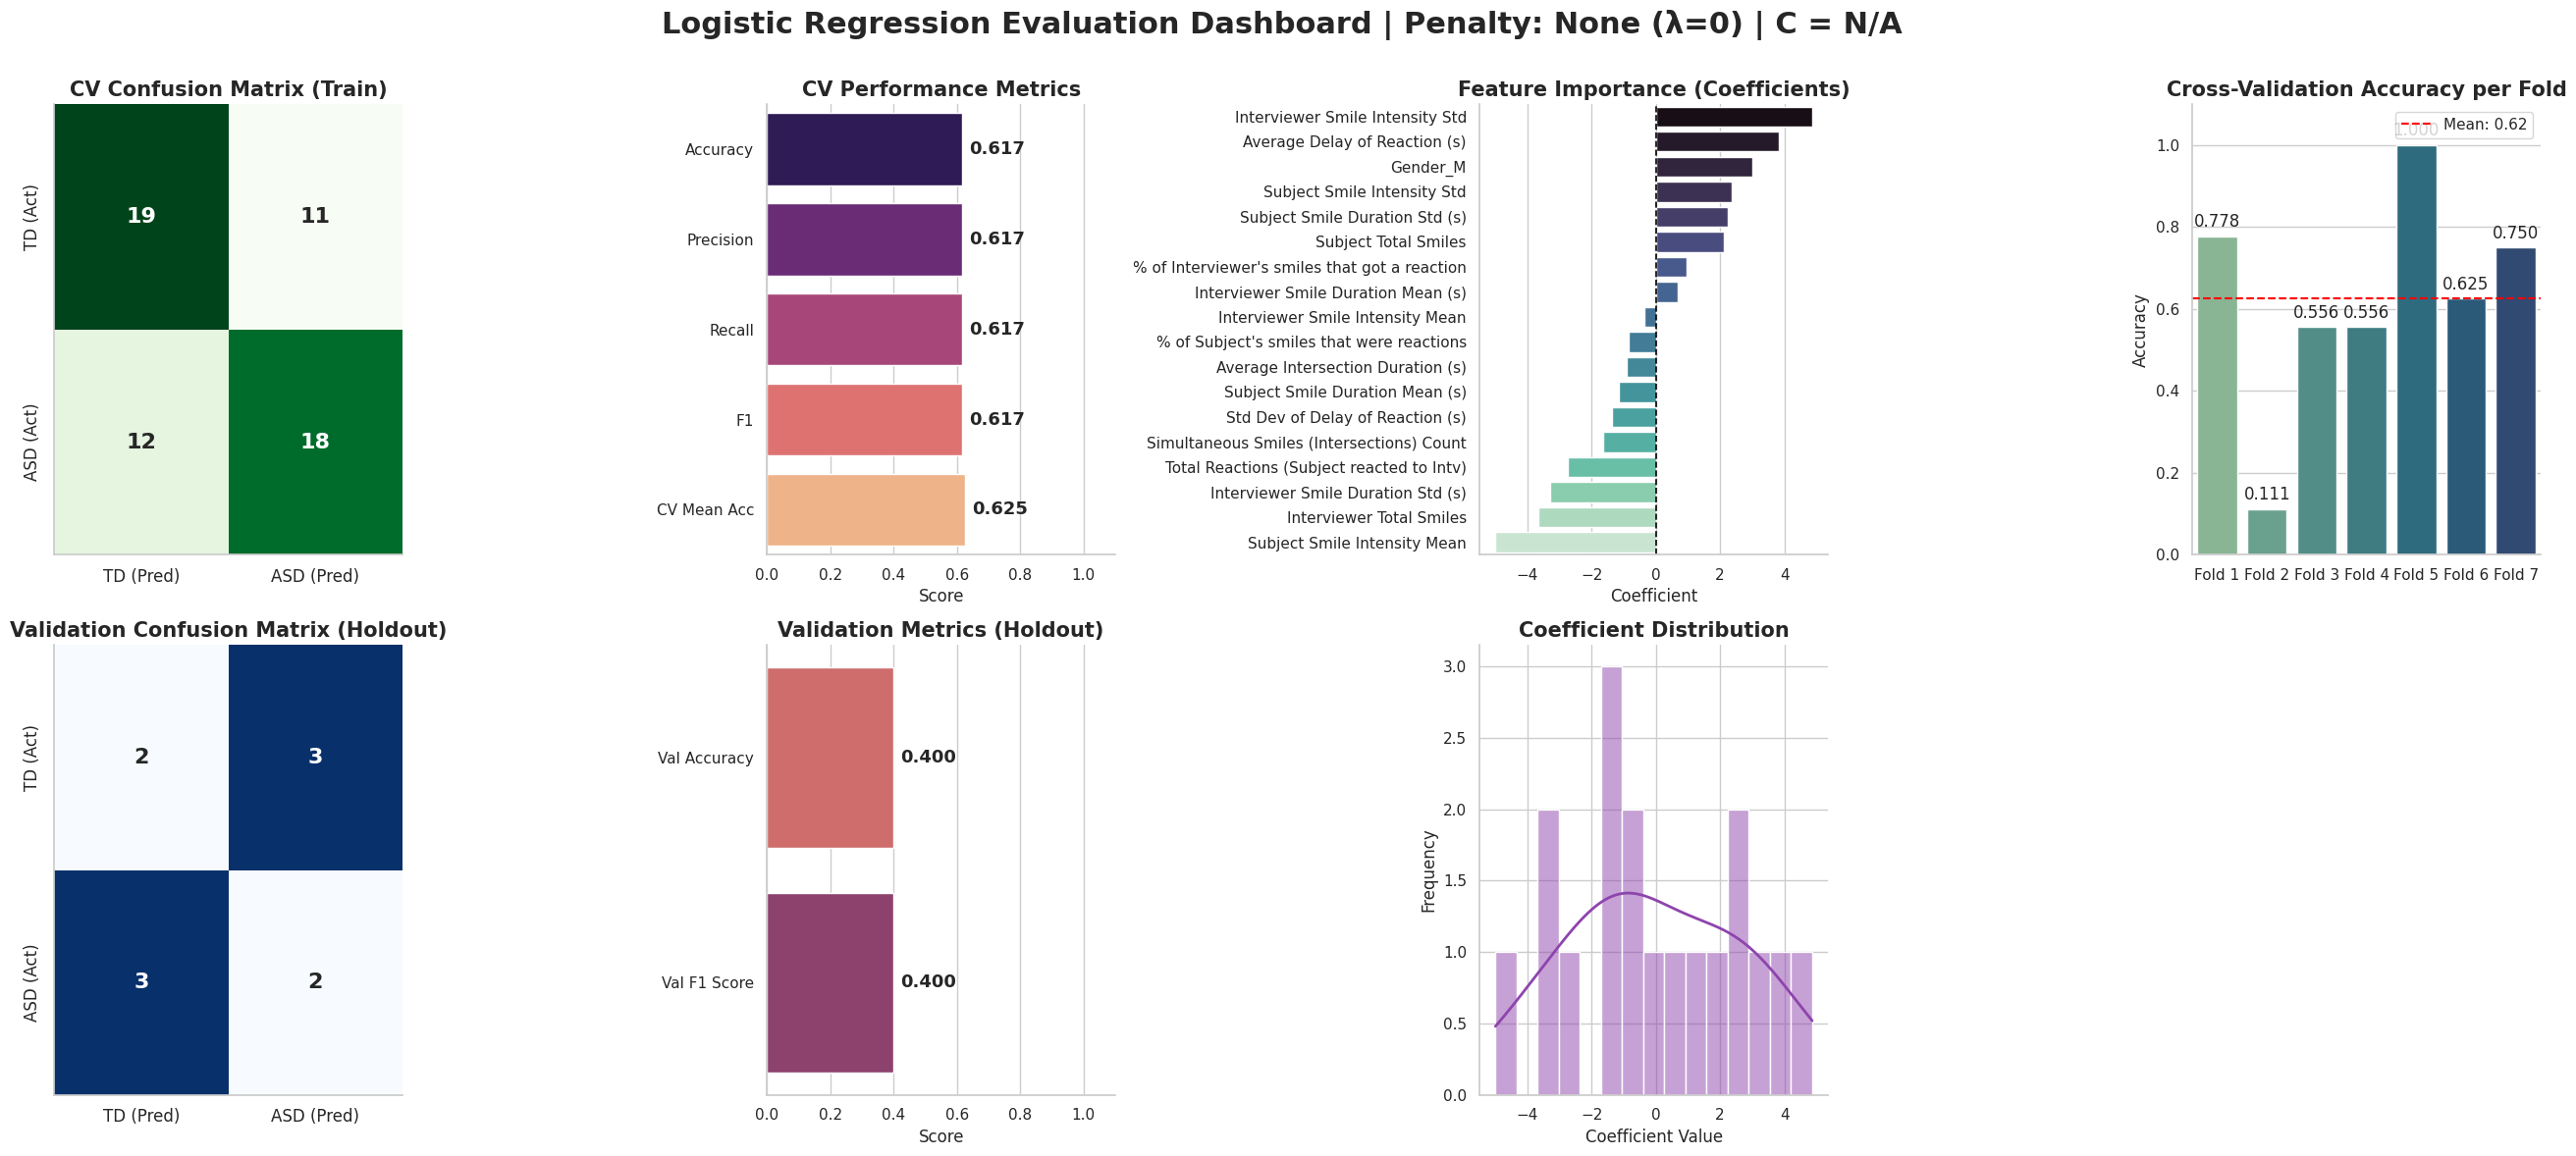

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 


VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000



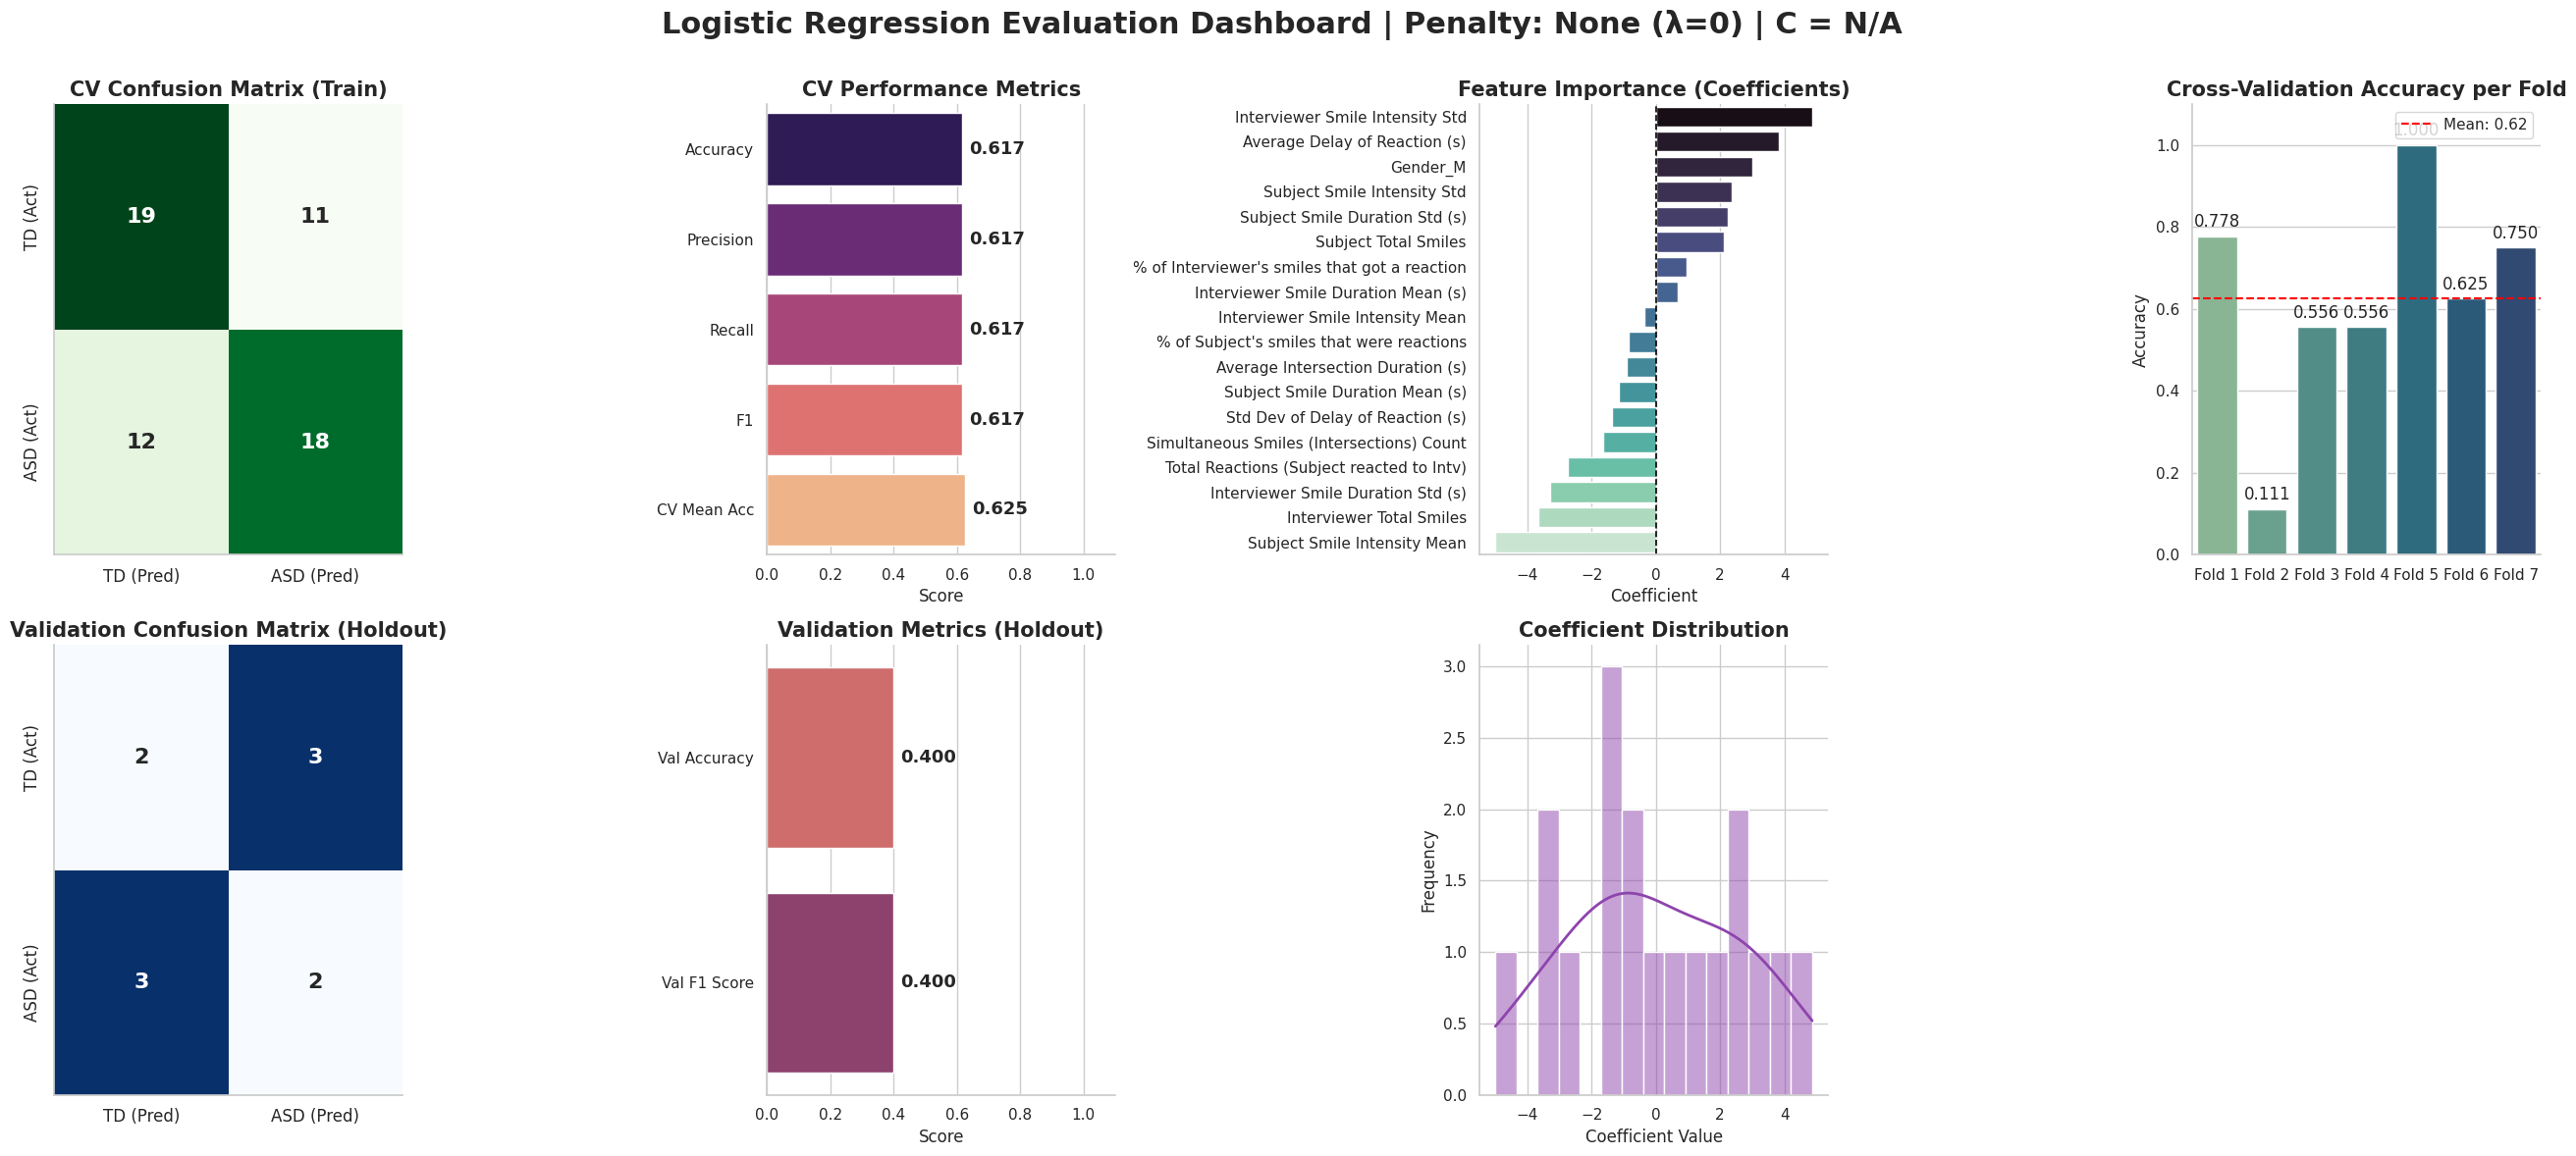

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.7000
Validation F1 Score: 0.6970



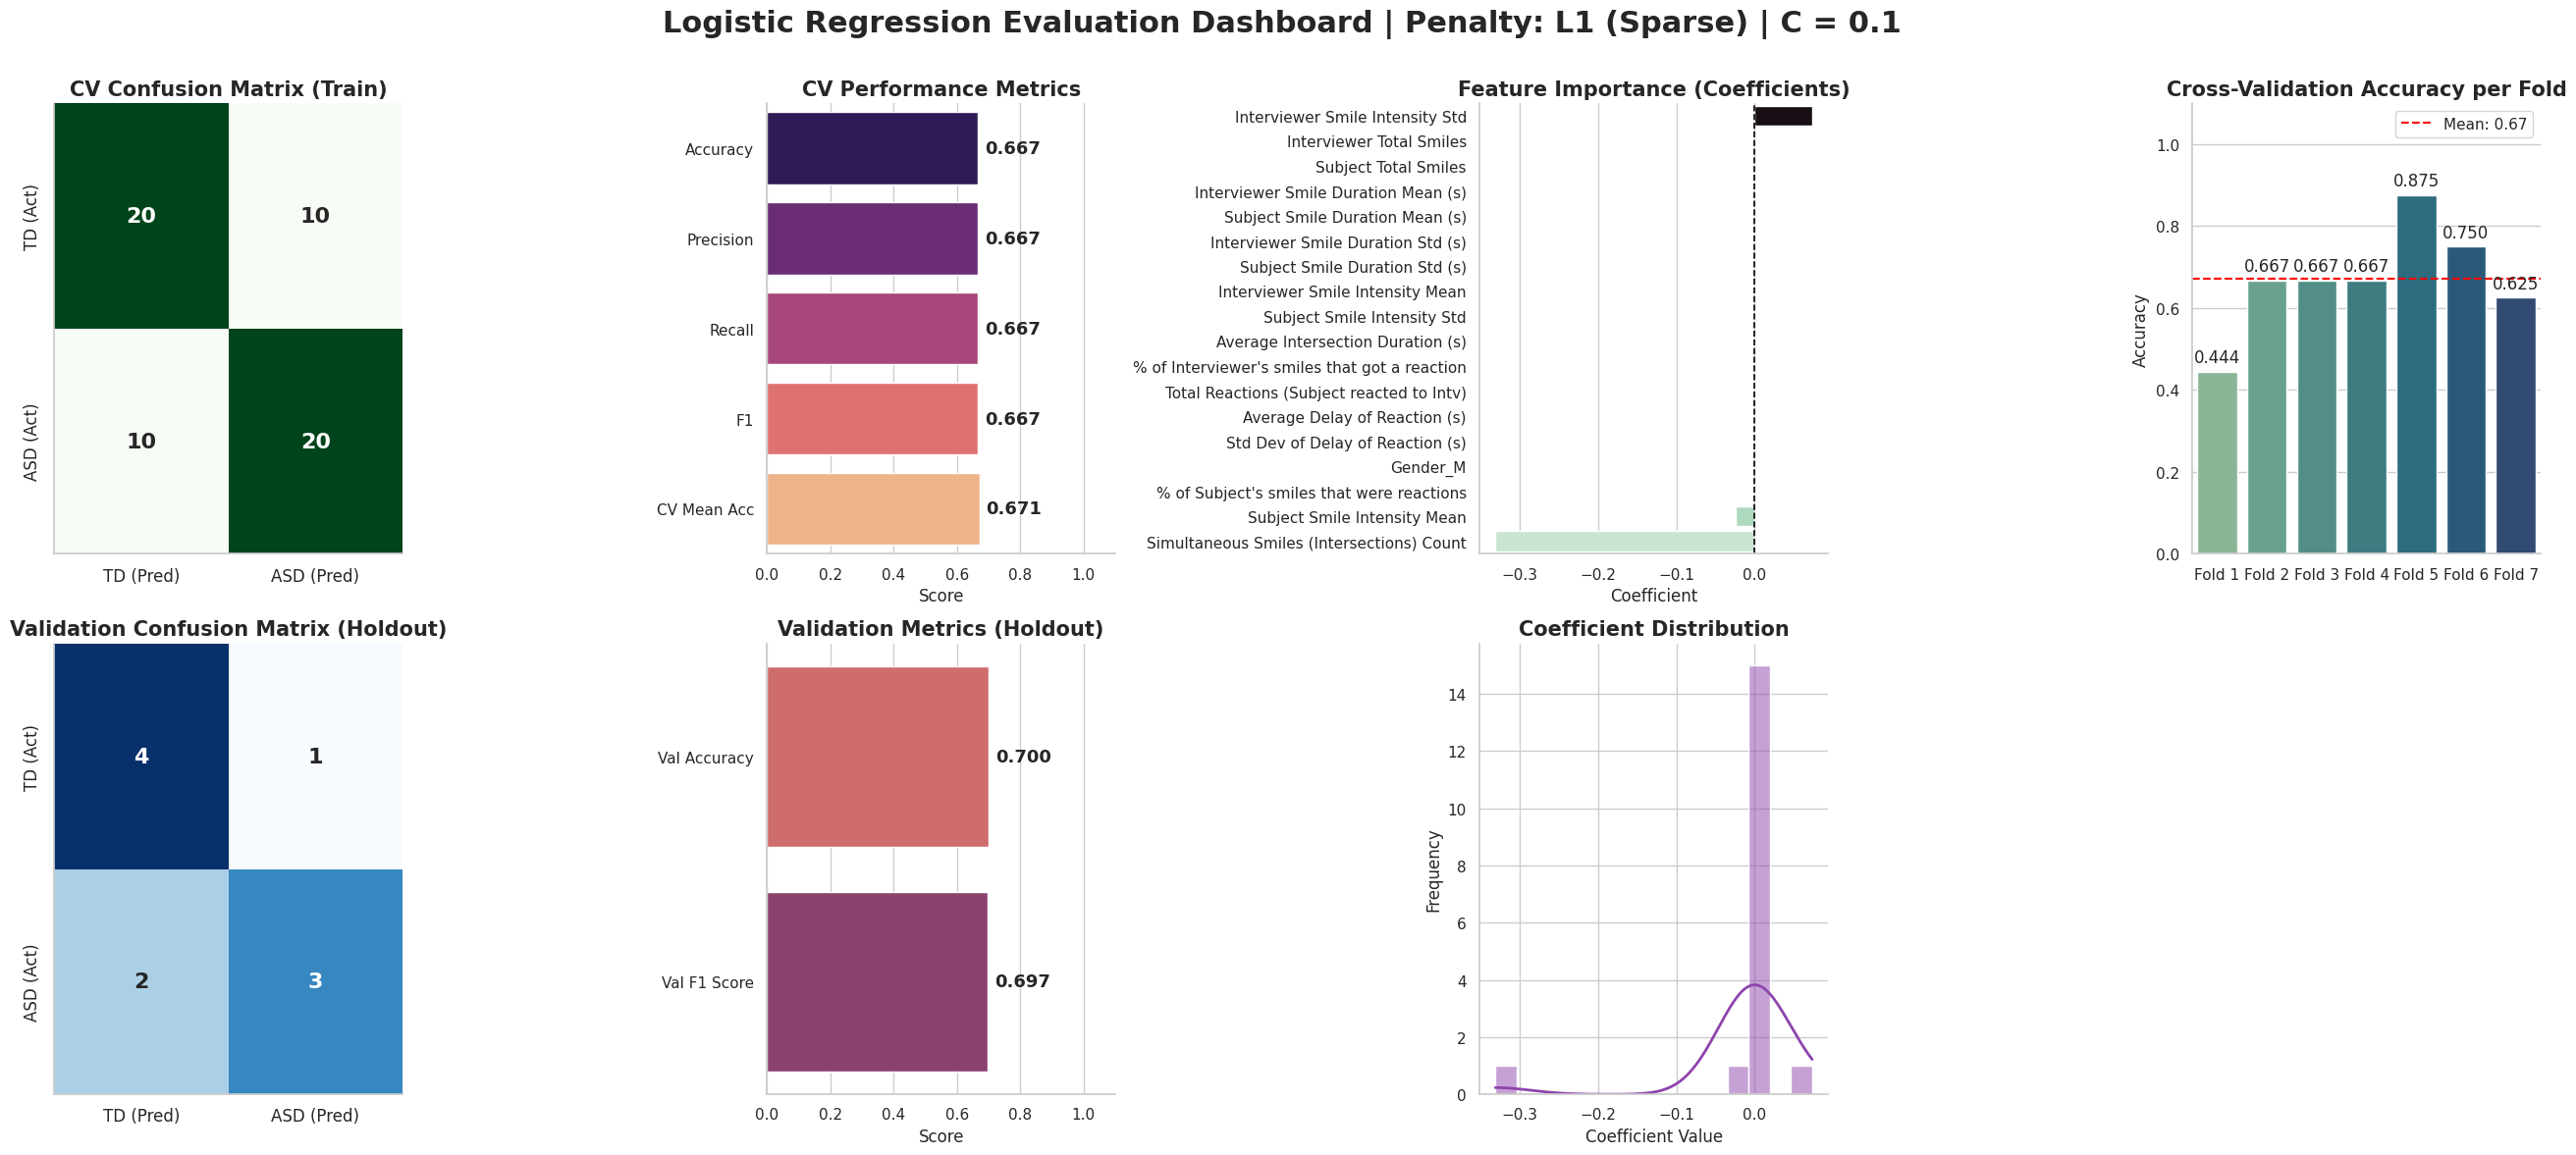

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949



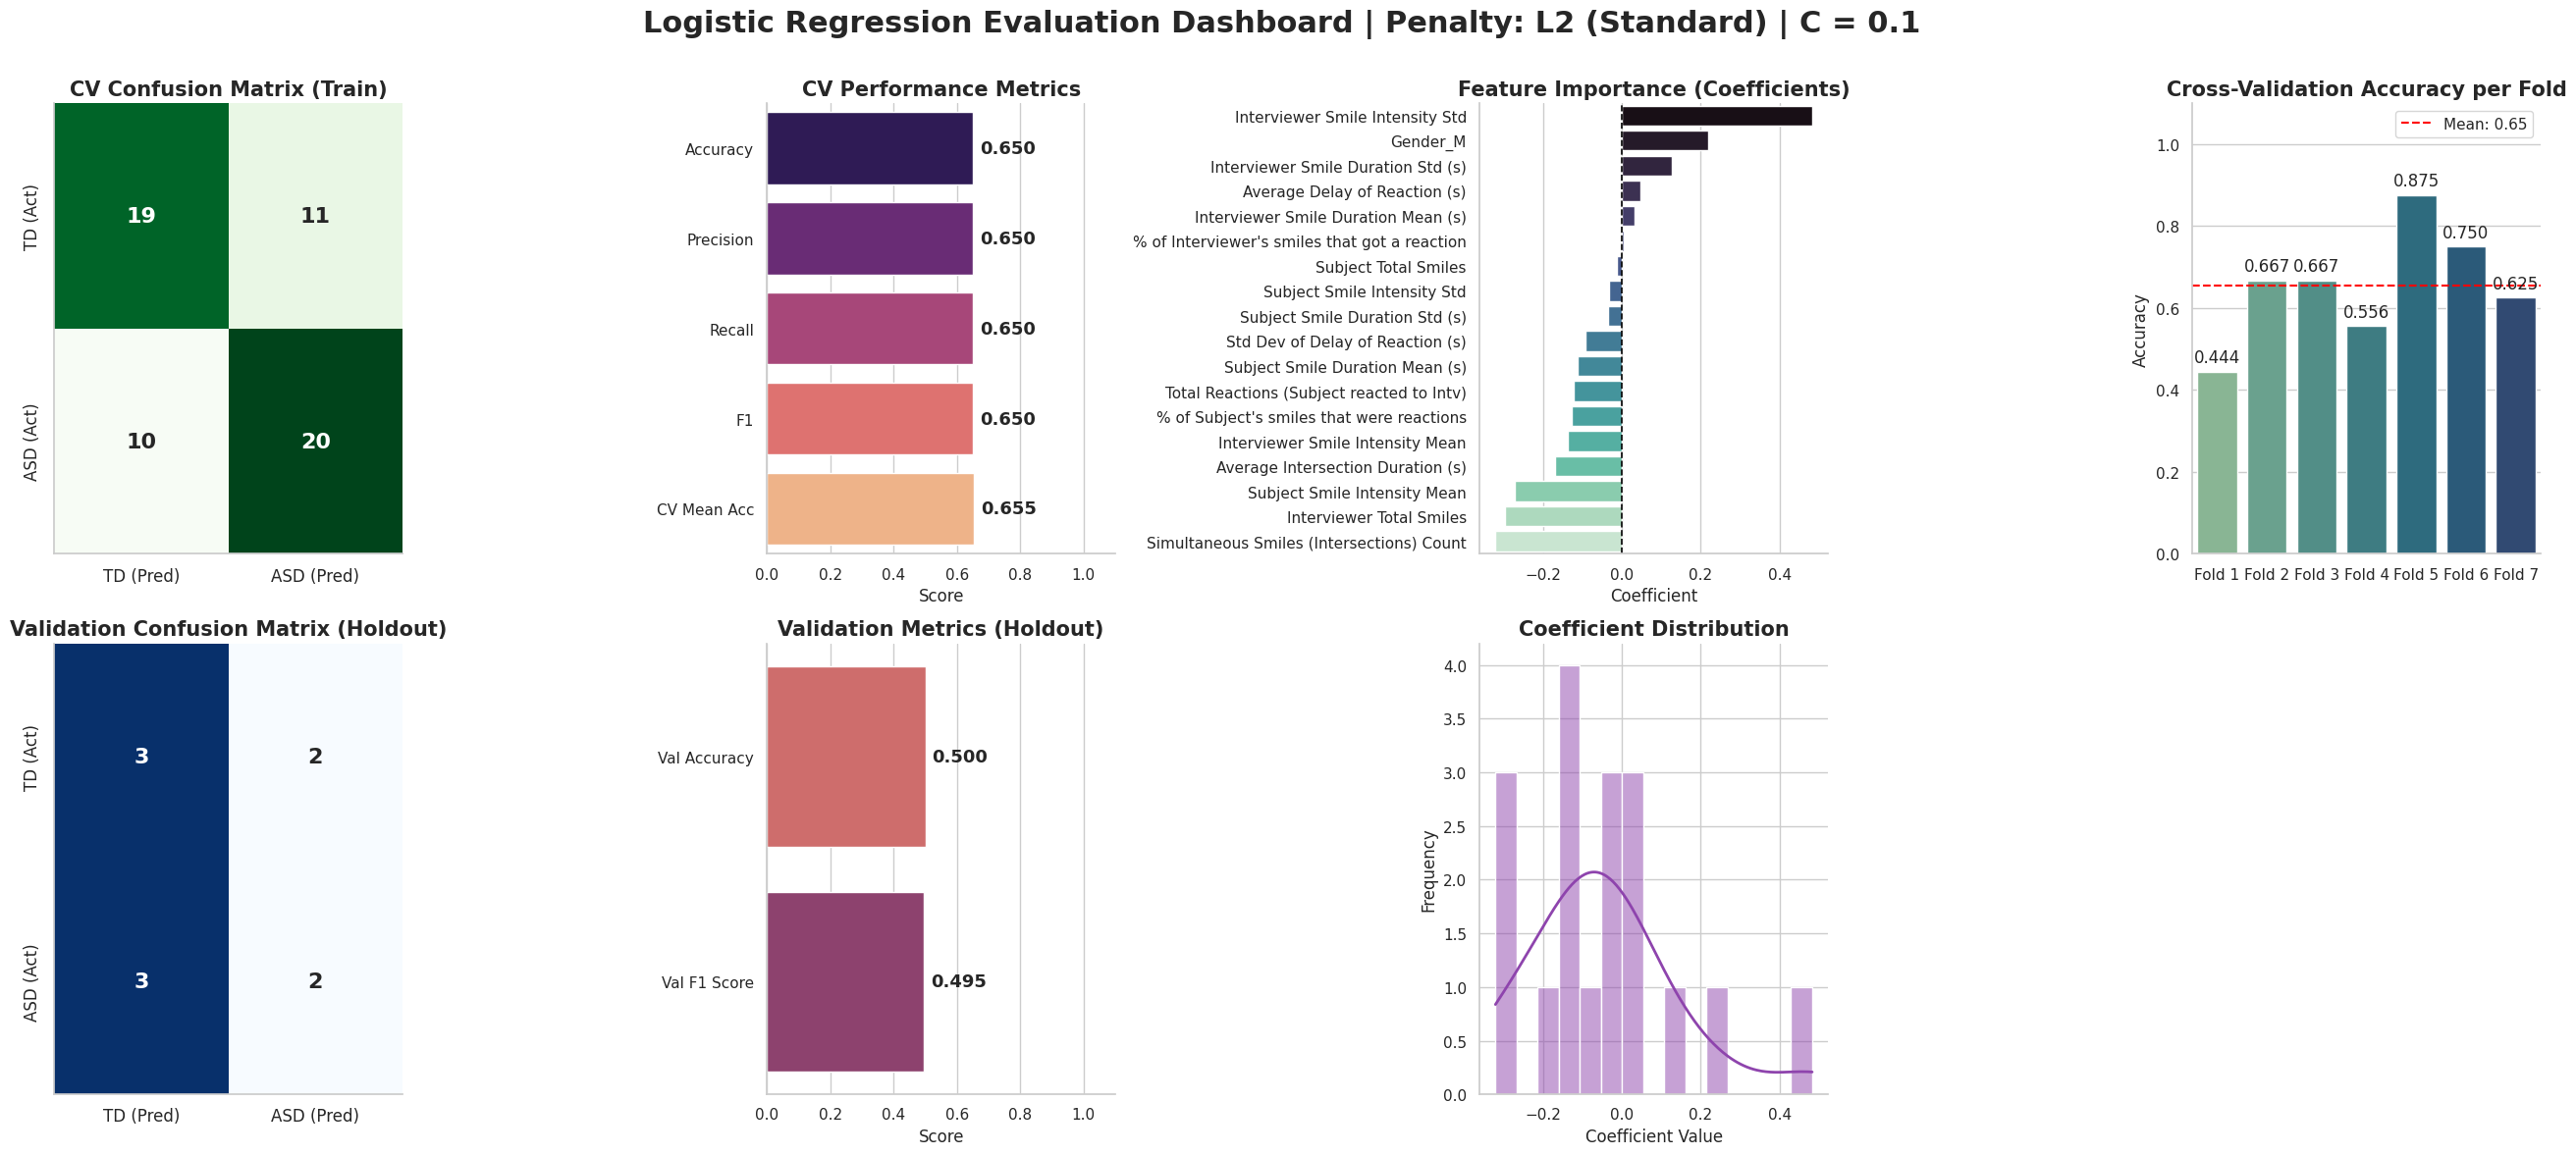

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949



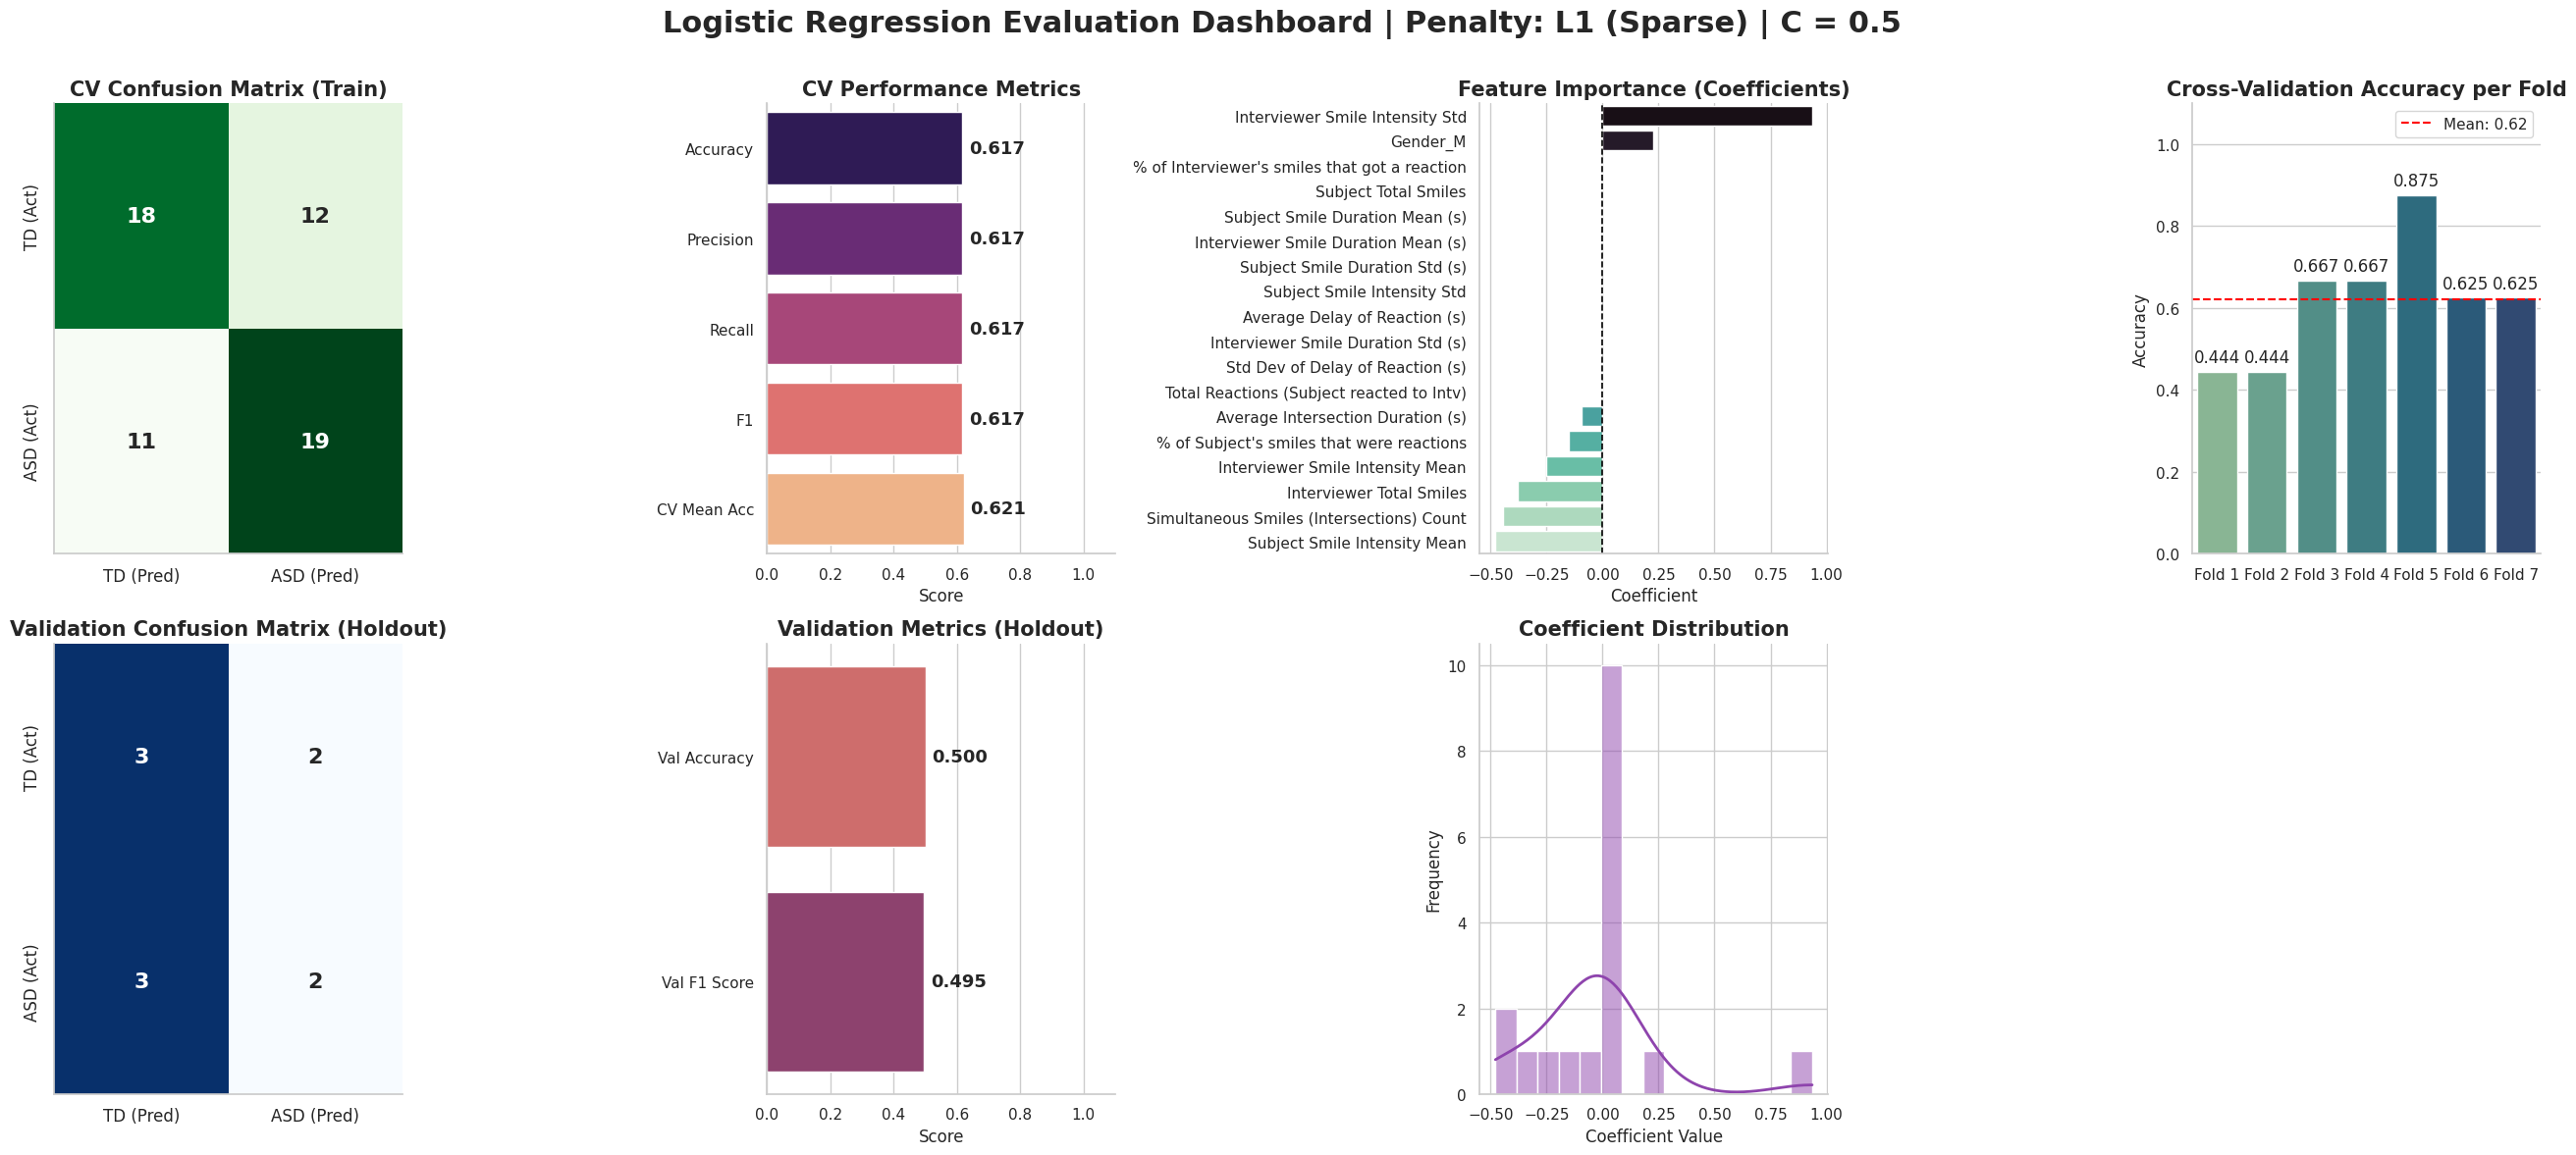

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949



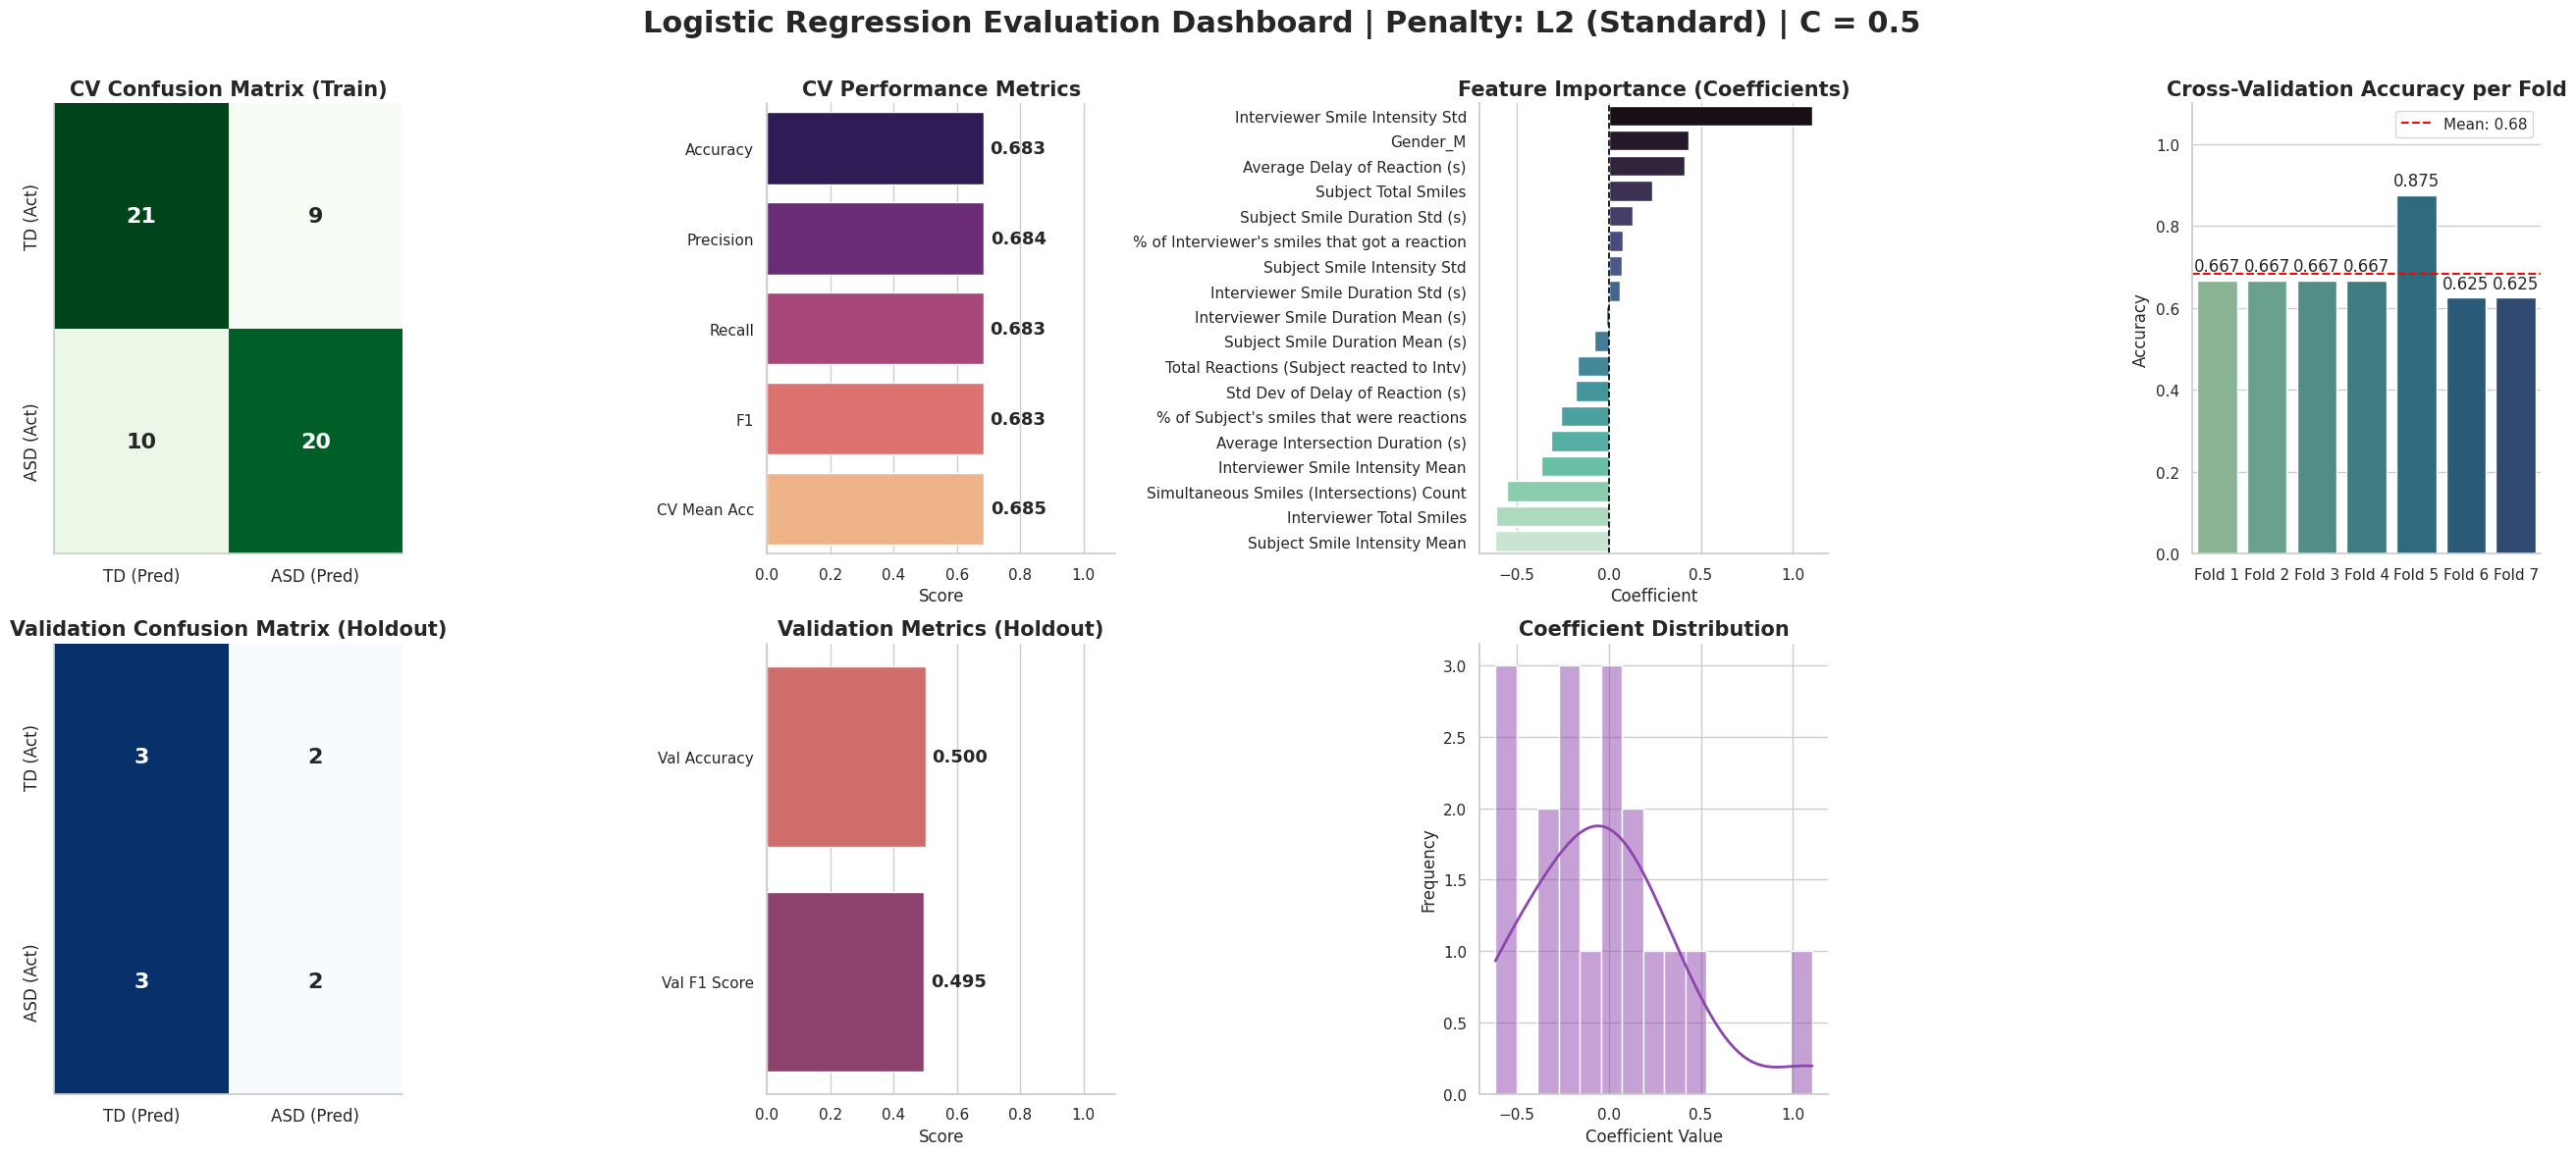

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949



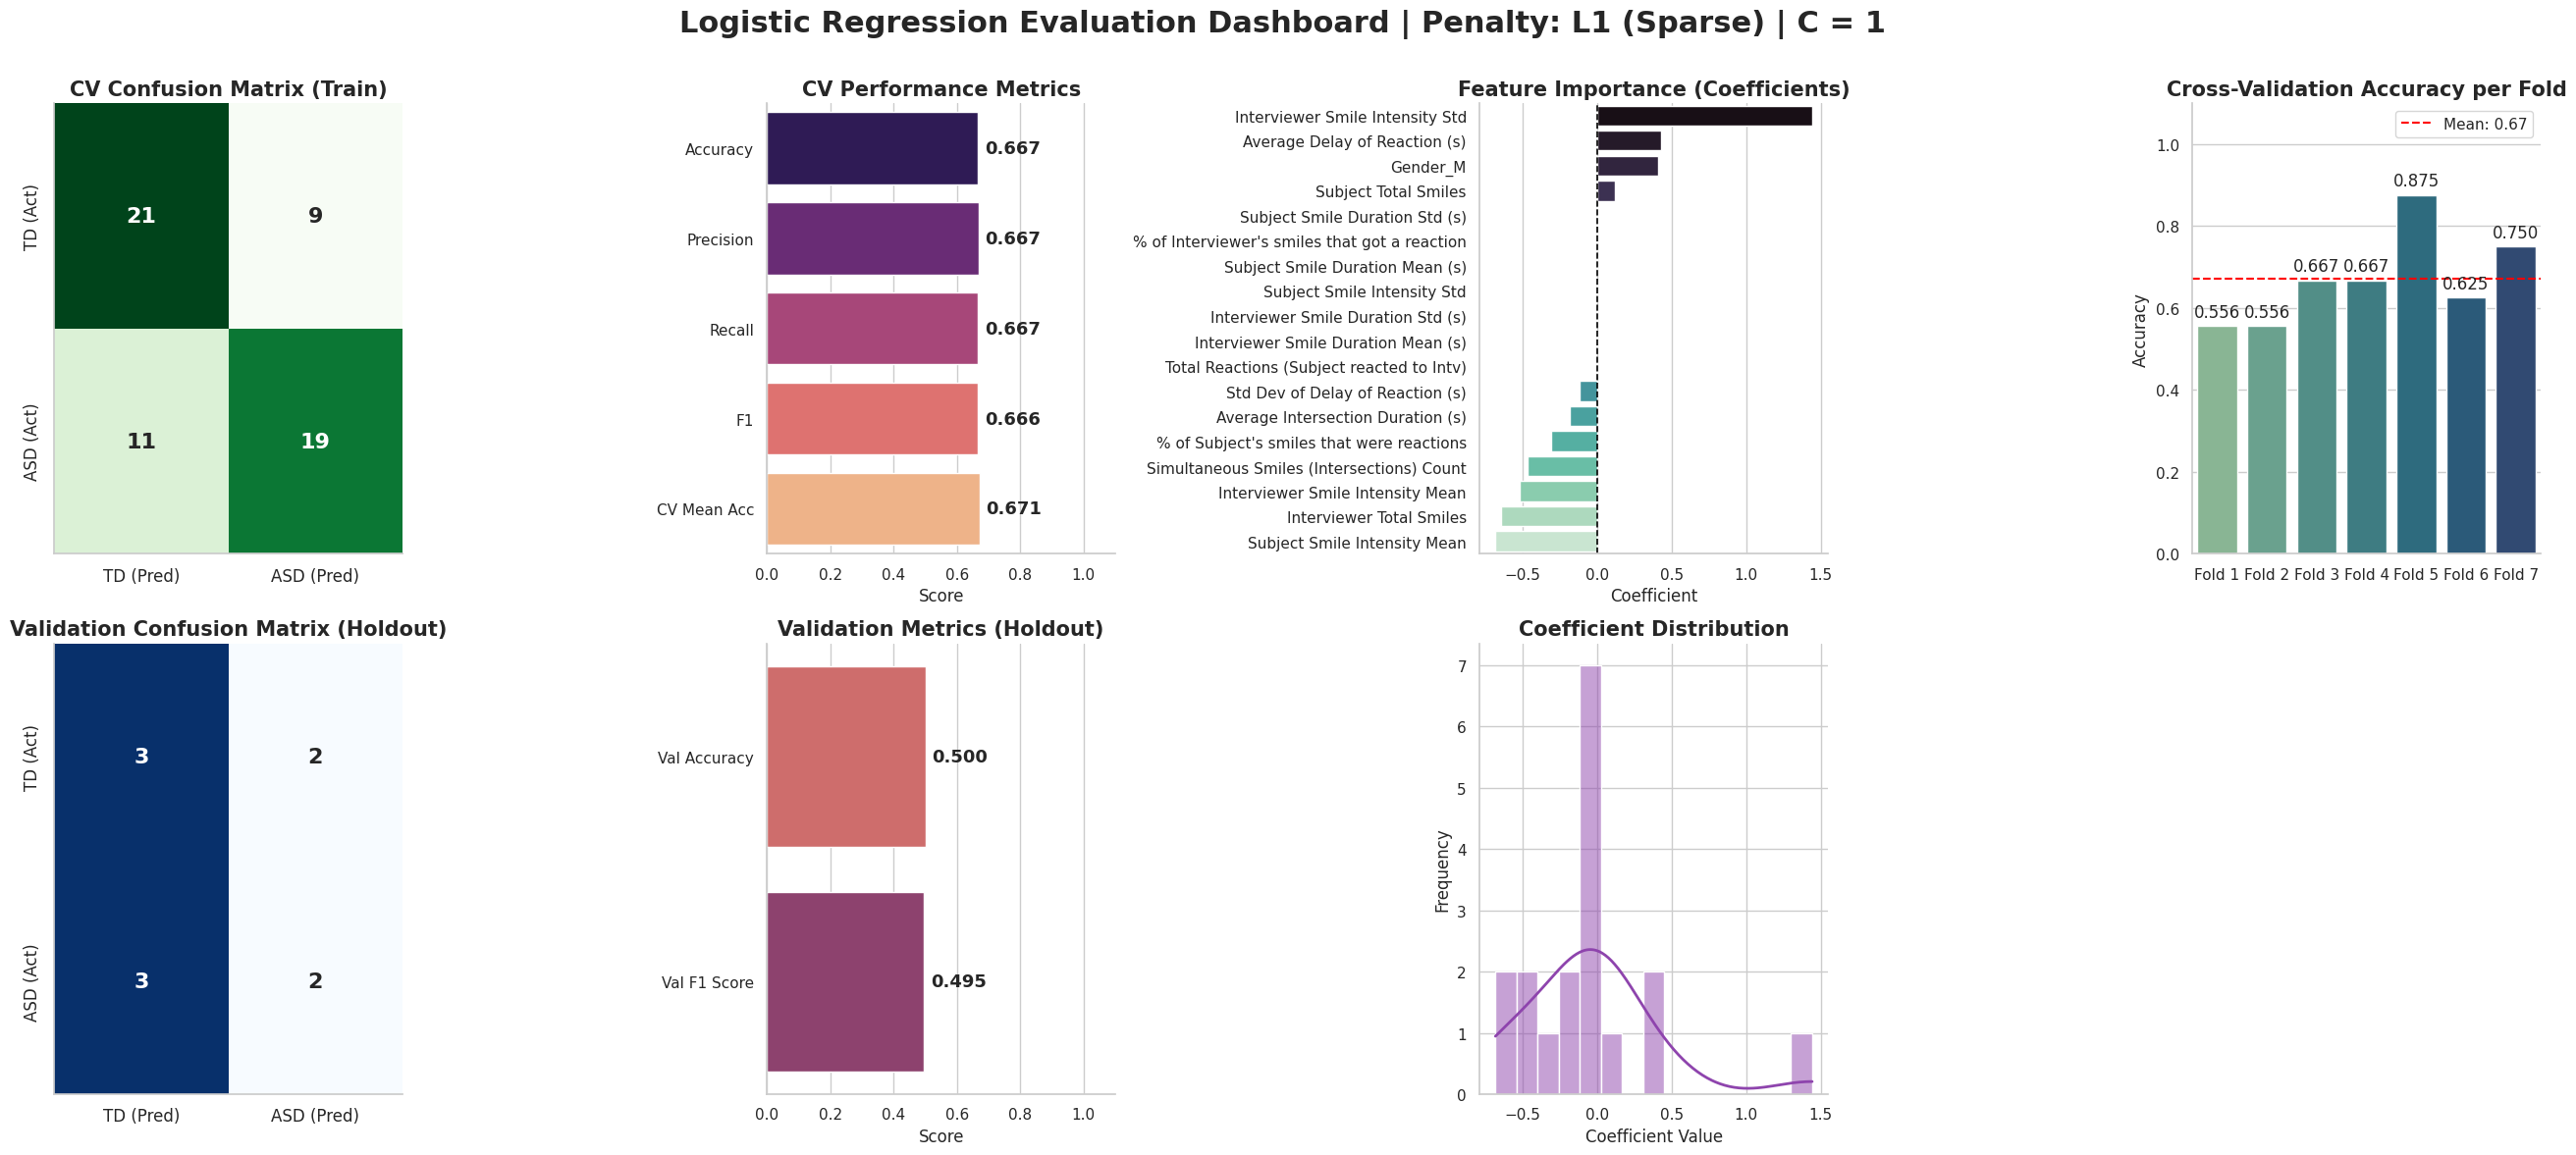

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.5000
Validation F1 Score: 0.4949



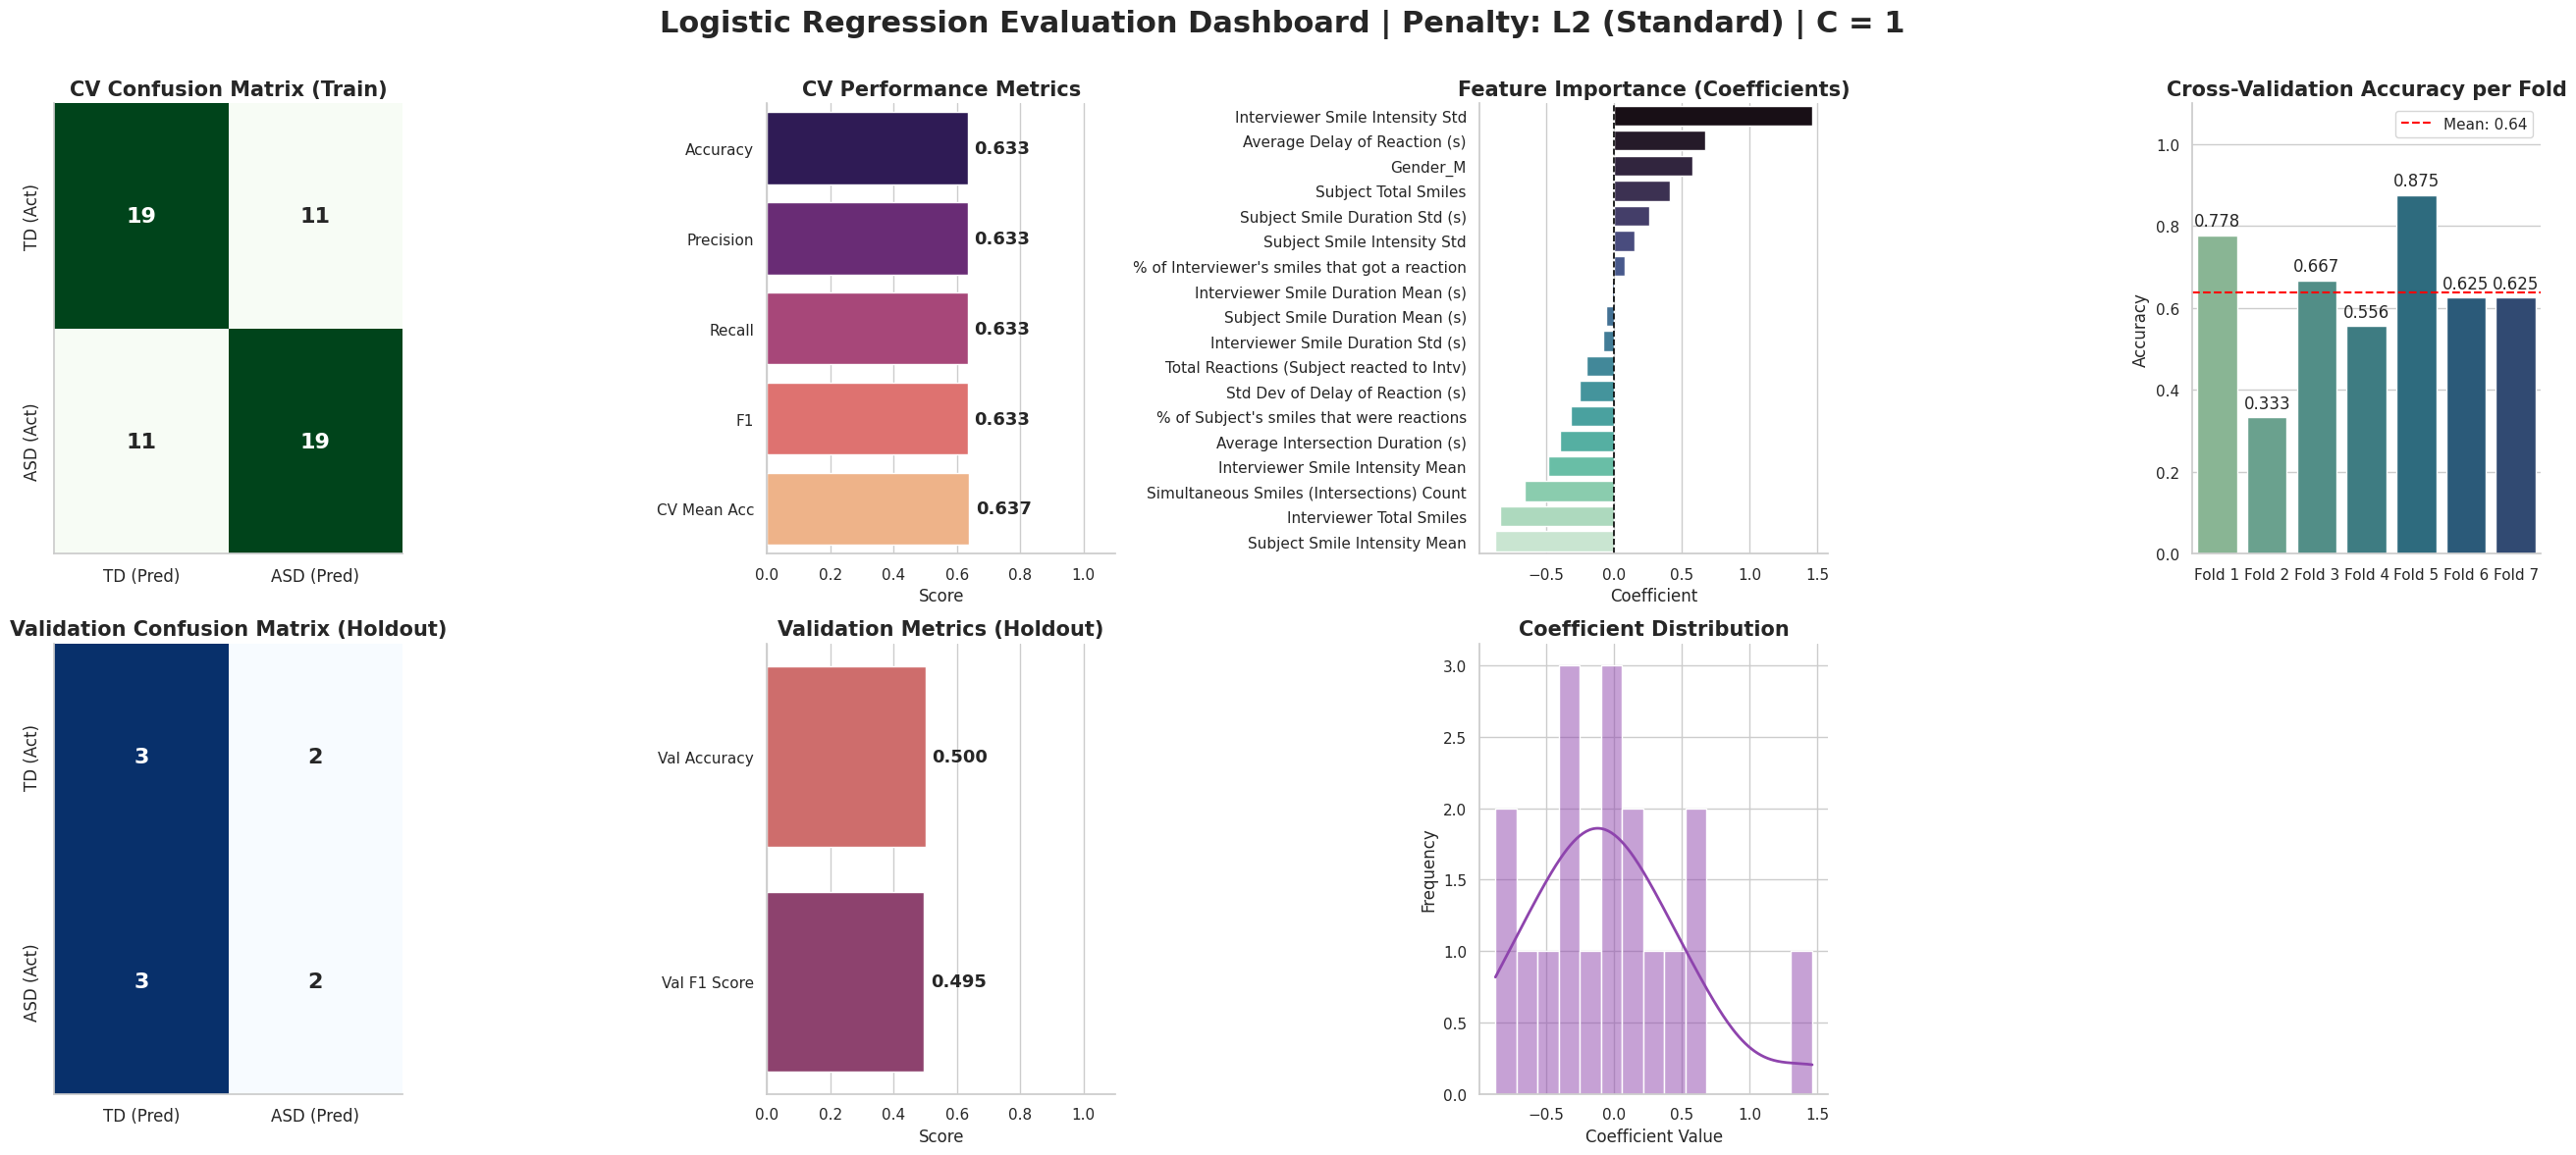

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000



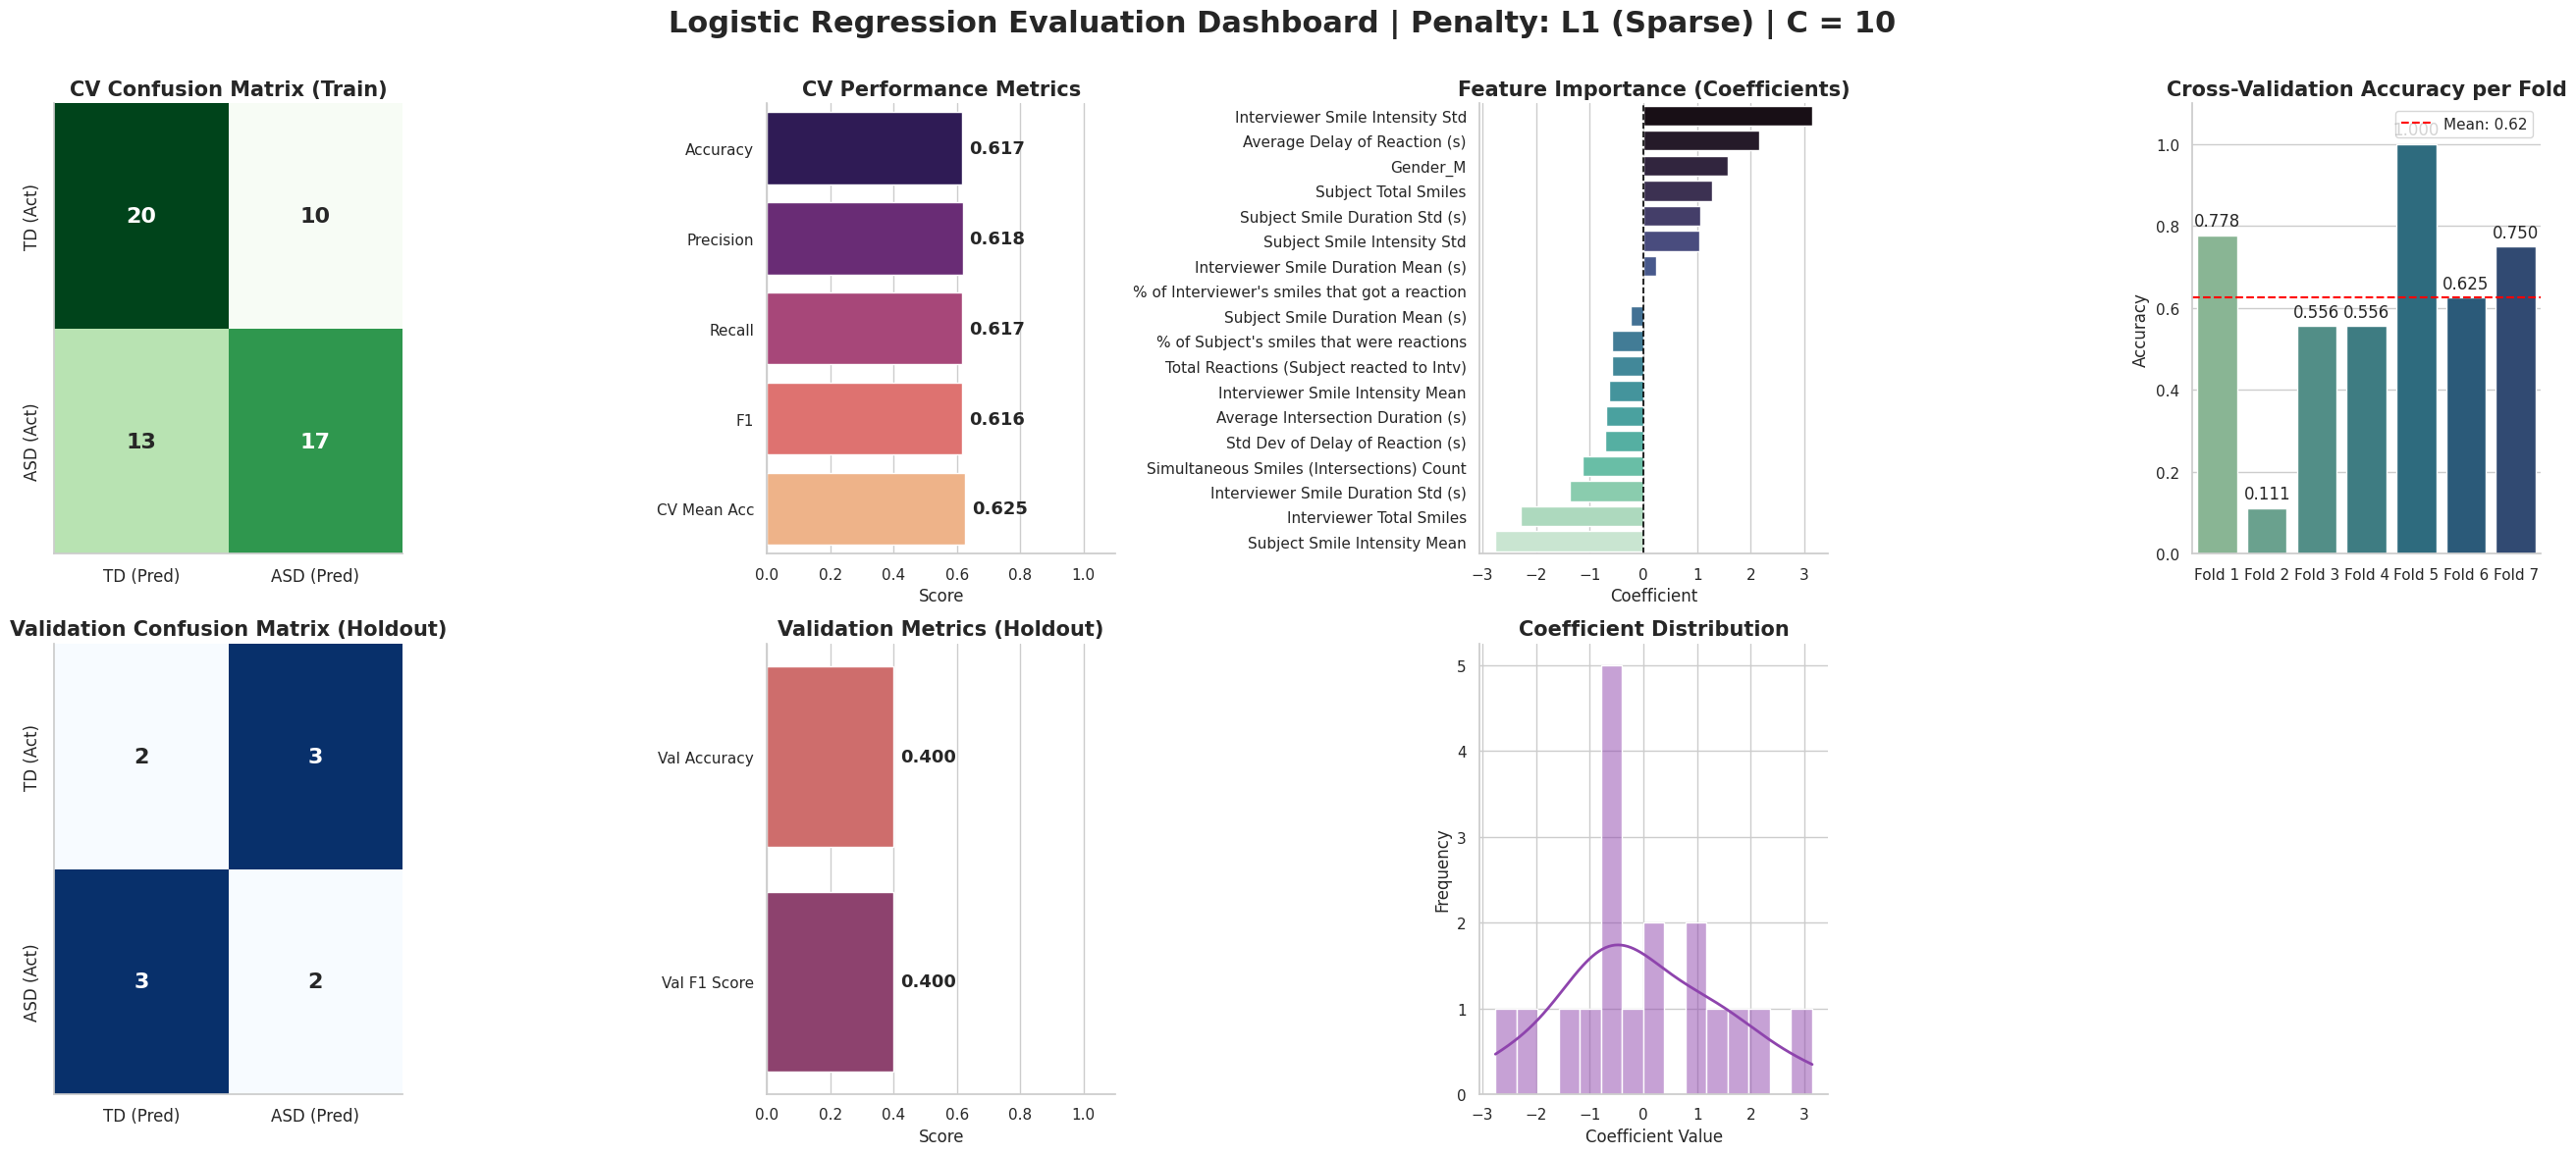

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000



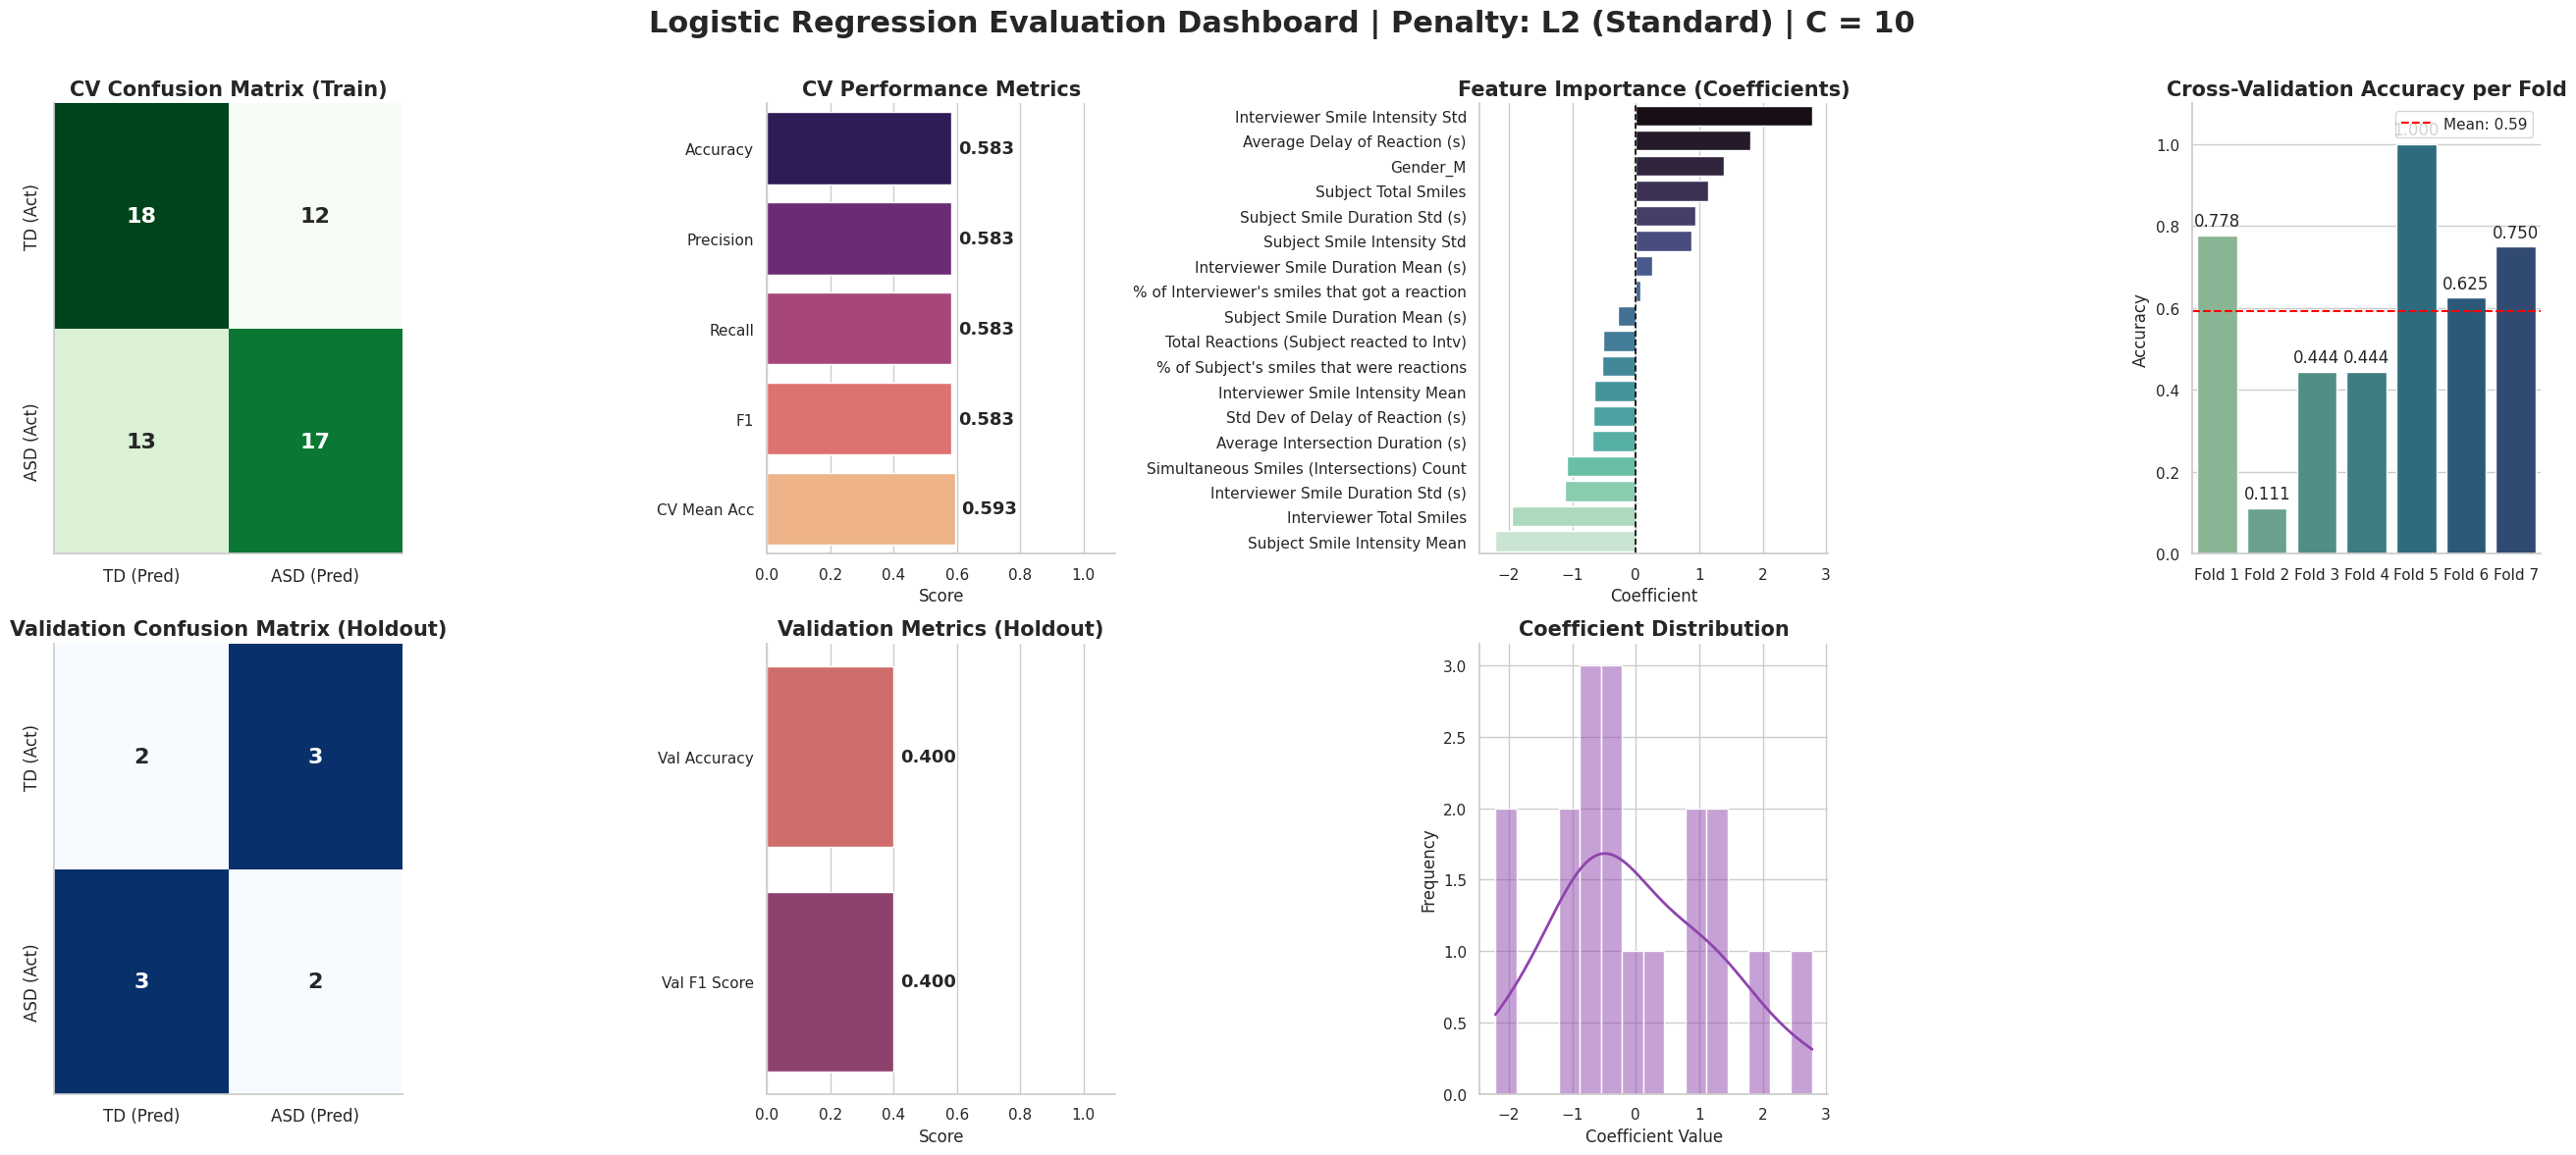

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000



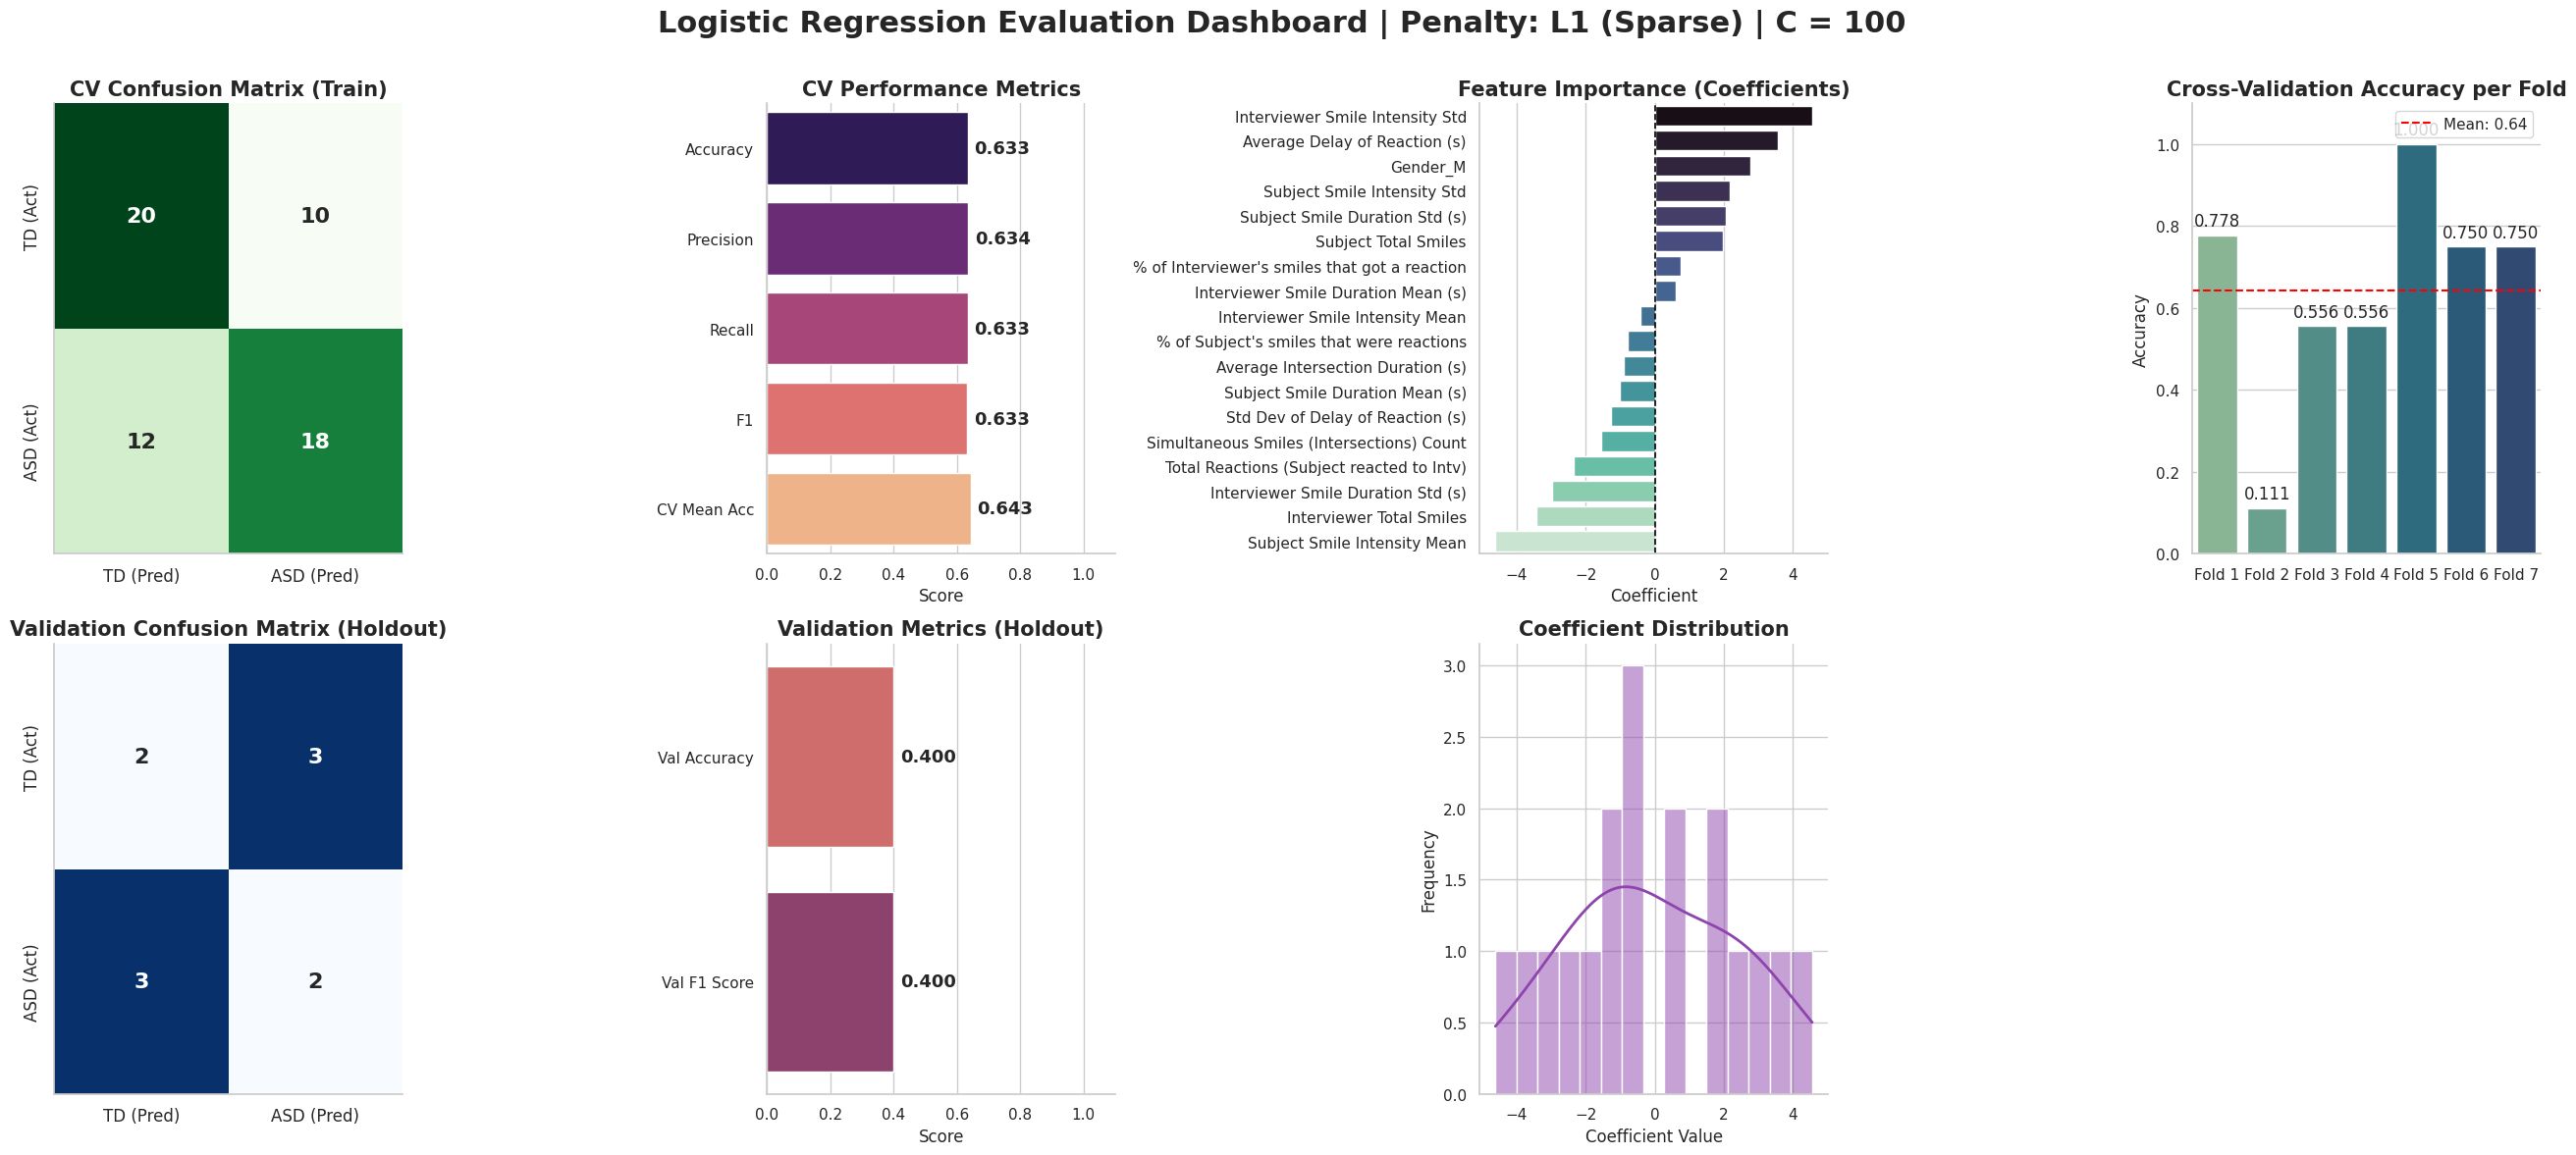

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

VALIDATION SET RESULTS (10 Held-out Subjects)
Validation Accuracy: 0.4000
Validation F1 Score: 0.4000



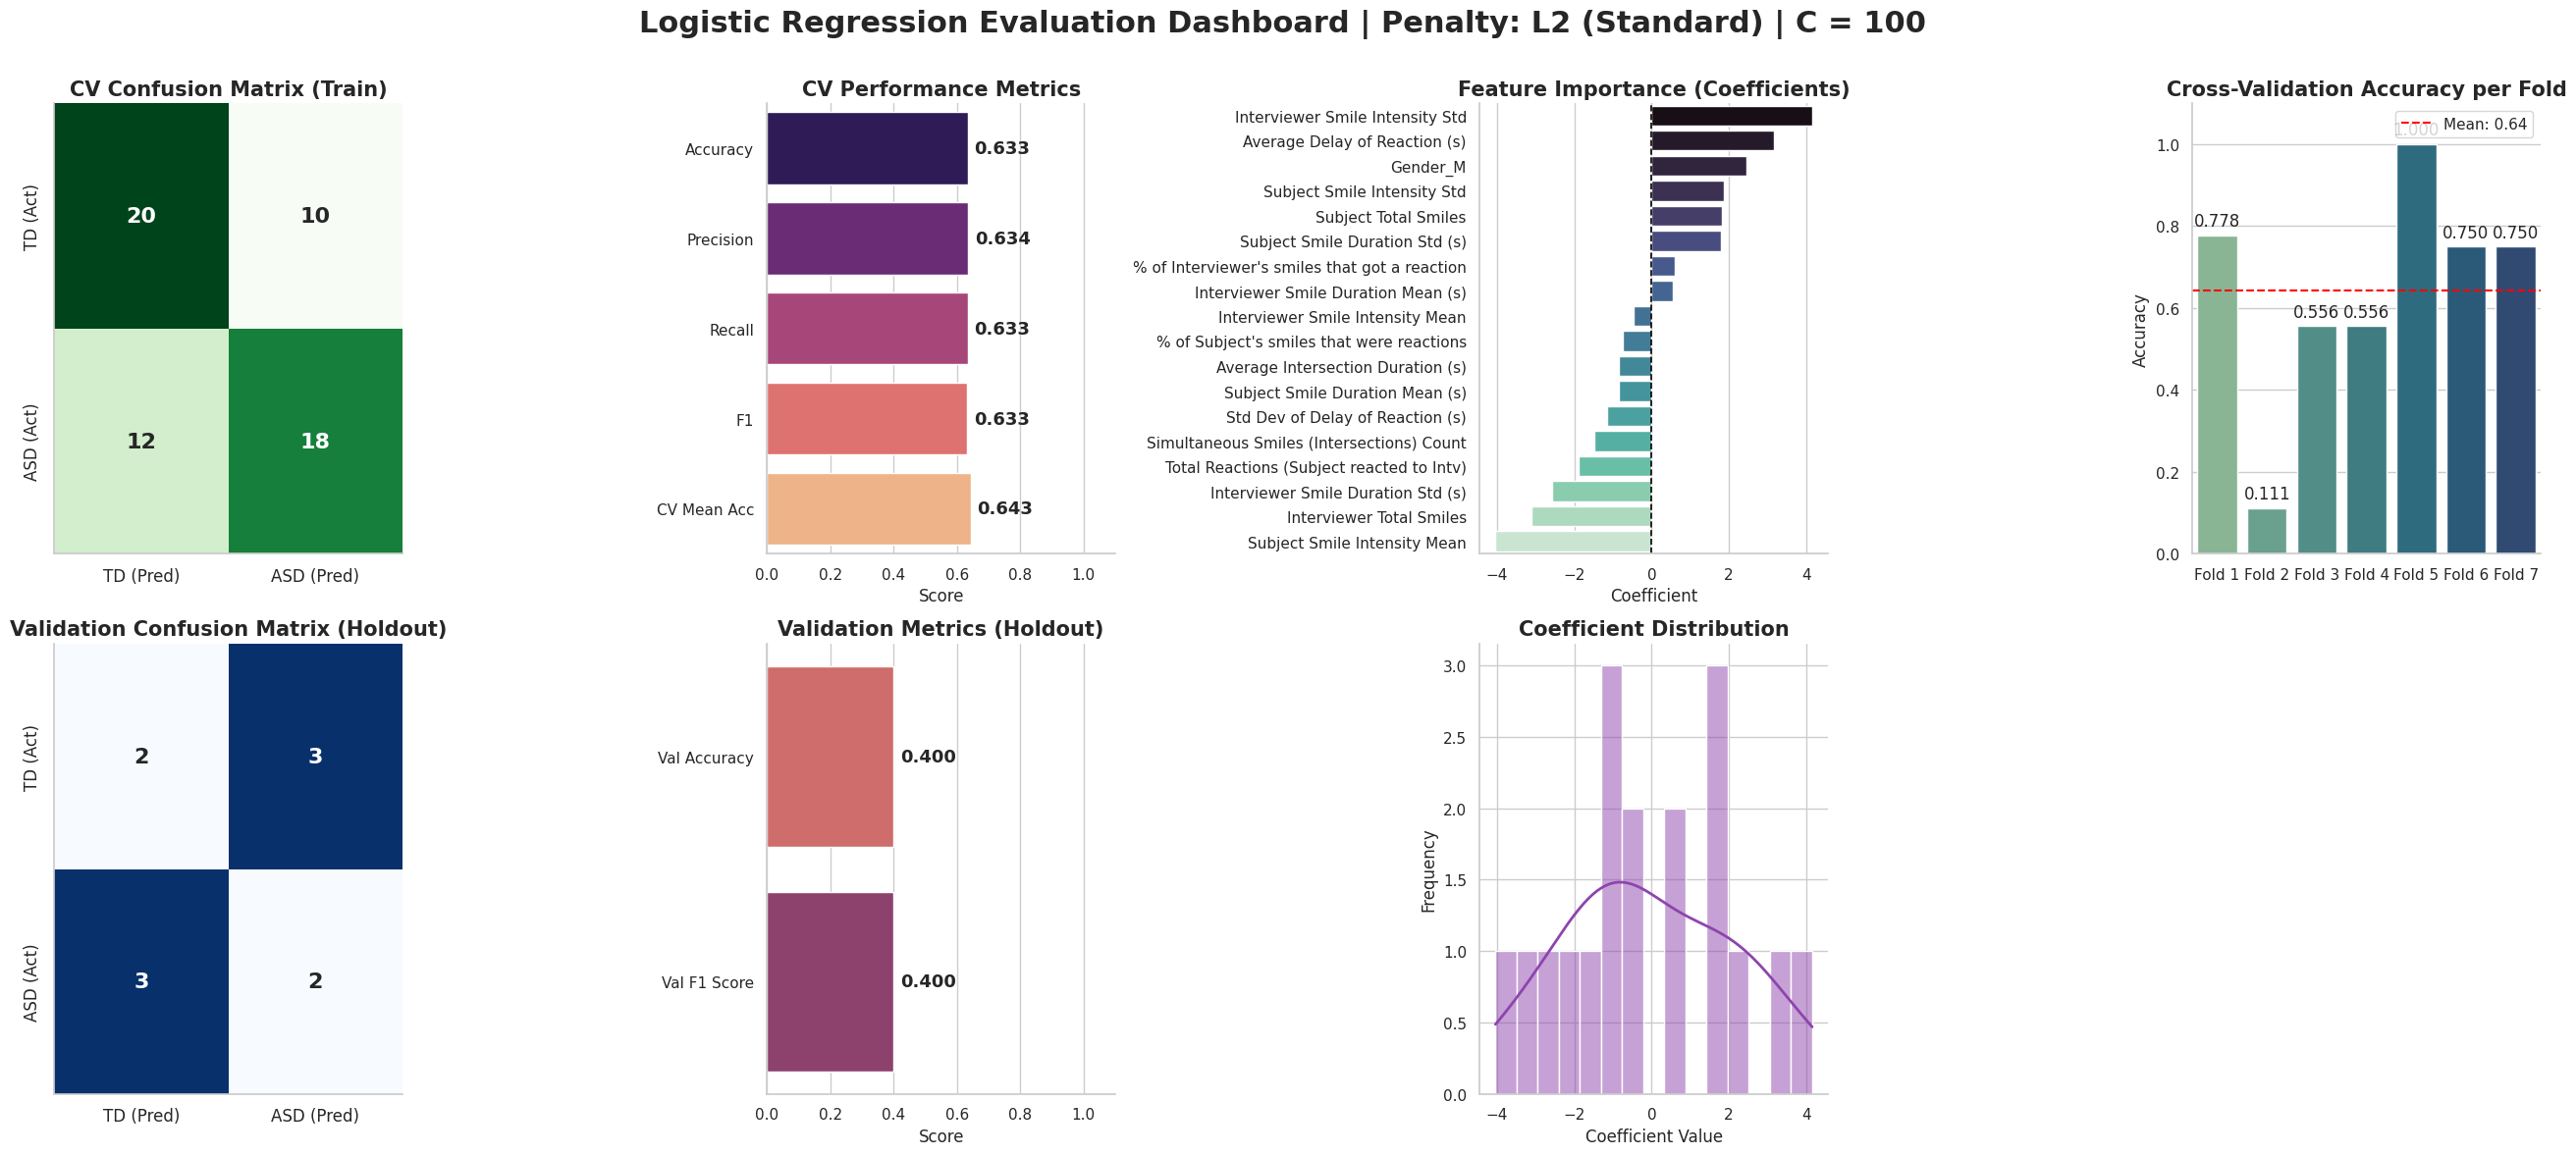

In [118]:
if __name__ == "__main__":
    c_values = [ 0, 0.1,0.5, 1, 10, 100]
    for c in c_values:

        evaluate_logreg_with_kfold(K_FOLDS=7,use_l1=True, C_value=c)
        

        evaluate_logreg_with_kfold(K_FOLDS=7,use_l1=False, C_value=c)

In [62]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [63]:
def evaluate_kmeans_clustering(clusters=2):
    """
    Applies K-Means (k=2) to the dataset, aligns the arbitrary cluster labels 
    with the true labels, and plots a PCA visualization.
    """
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
        return

    df = pd.read_csv(DATA_PATH)
    
    # We will use the entire dataset for exploratory clustering
    # so we concatenate the splits from your prepare_data function
    X_train, X_val, y_train, y_val = prepare_data(df)
    X = pd.concat([X_train, X_val])
    y = pd.concat([y_train, y_val])

    # 1. Scale the data (CRITICAL for distance-based algorithms like K-Means)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 2. Apply K-Means
    print("\nRunning K-Means with 2 clusters...")
    # n_init='auto' suppresses scikit-learn warnings about initialization changes
    kmeans = KMeans(n_clusters=clusters, random_state=42, n_init='auto')
    cluster_labels = kmeans.fit_predict(X_scaled)

    # 3. Align Cluster Labels with True Labels
    # We check both alignments to see which matches the ground truth best.
    acc_direct = accuracy_score(y, cluster_labels)
    acc_flipped = accuracy_score(y, 1 - cluster_labels)

    if acc_flipped > acc_direct:
        aligned_labels = 1 - cluster_labels
        best_acc = acc_flipped
        print("Note: K-Means labels were flipped to align with ground truth.")
    else:
        aligned_labels = cluster_labels
        best_acc = acc_direct

    print(f"Clustering Accuracy (Compared to True Labels): {best_acc:.4f}")

    # 4. Display Confusion Matrix
    cm = confusion_matrix(y, aligned_labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
                xticklabels=['Cluster 0 (Predicted)', 'Cluster 1 (Predicted)'],
                yticklabels=['Class 0 (True)', 'Class 1 (True)'])
    plt.title(f'K-Means vs True Labels (Acc: {best_acc:.2f})')
    plt.tight_layout()
    plt.show()

    # 5. Visualization using PCA (Dimensionality Reduction to 2D)
    # This compresses all your features into 2 axes so we can plot them on a scatter graph
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
    pca_df['True Label'] = y.values
    pca_df['K-Means Cluster'] = aligned_labels

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot True Labels
    sns.scatterplot(x='PC1', y='PC2', hue='True Label', data=pca_df, 
                    palette=['blue', 'red'], ax=axes[0], s=60, alpha=0.8)
    axes[0].set_title('Ground Truth (Actual Classes)', fontsize=14)
    
    # Plot K-Means Clusters
    sns.scatterplot(x='PC1', y='PC2', hue='K-Means Cluster', data=pca_df, 
                    palette=['blue', 'red'], ax=axes[1], s=60, alpha=0.8)
    axes[1].set_title('K-Means Clusters', fontsize=14)

    plt.suptitle('PCA Visualization: True Labels vs K-Means Clustering', fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.show()

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)

Running K-Means with 2 clusters...
Note: K-Means labels were flipped to align with ground truth.
Clustering Accuracy (Compared to True Labels): 0.6857


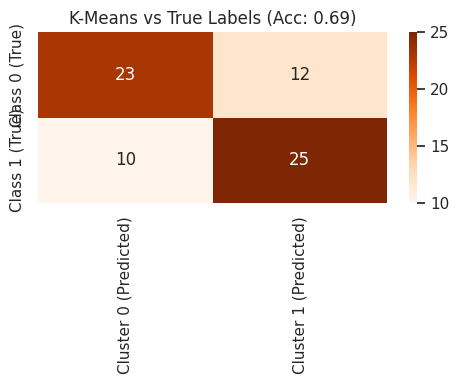

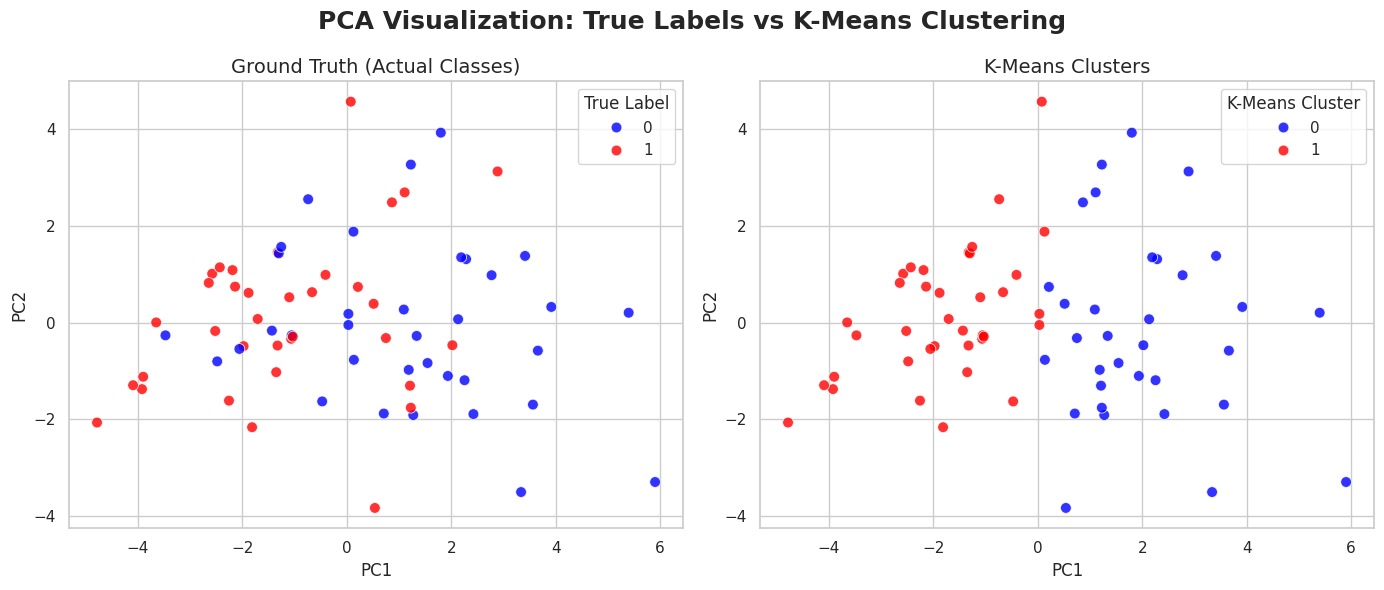

In [64]:
if __name__ == "__main__":
    evaluate_kmeans_clustering(2)

In [86]:
# --- FIX 1: Pass the data as arguments instead of loading it inside the function ---
def evaluate_logreg_with_pca_kfold(X_train, X_val, y_train, y_val, K_FOLDS=5, use_l1=True, C_value=1.0, max_iter=10000, n_components=2):
    """
    Applies PCA to reduce to n components, then evaluates Logistic Regression.
    """
    # Strictly follow Scikit-Learn 1.8+ rules
    if C_value == 0 or C_value is None:
        c_setting = np.inf         # C=inf is the new way to say penalty=None (lambda=0)
        l1_ratio_setting = None    # Ignored when C is infinite
        penalty_display = "None (λ=0)"
        c_display = "N/A"
    else:
        c_setting = C_value
        l1_ratio_setting = 1.0 if use_l1 else 0.0 # 1.0 = L1, 0.0 = L2
        penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
        c_display = str(C_value)
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components)), 
        ('log_reg', LogisticRegression(
            l1_ratio=l1_ratio_setting,       
            C=c_setting,                
            solver='saga',          
            max_iter=max_iter, 
            random_state=42
        ))
    ])

    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring='accuracy')
    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy)

    pipeline.fit(X_train, y_train)
    y_val_pred = pipeline.predict(X_val)

    metrics_df = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1", "CV Mean Acc"],
        "Score": [
            accuracy_score(y_train, y_pred),
            precision_score(y_train, y_pred, average='weighted', zero_division=0),
            recall_score(y_train, y_pred, average='weighted', zero_division=0),
            f1_score(y_train, y_pred, average='weighted', zero_division=0),
            cv_scores.mean()
        ]
    })

    fold_df = pd.DataFrame({
        "Fold": [f"Fold {i+1}" for i in range(K_FOLDS)],
        "Accuracy": cv_scores
    })

    pc_labels = [f'PC{i+1}' for i in range(n_components)]
    
    coefs = pd.DataFrame({
        'Feature': pc_labels, 
        'Coefficient': pipeline.named_steps['log_reg'].coef_[0]
    }).sort_values(by='Coefficient', ascending=False)

    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted', zero_division=0)
    
    val_metrics_df = pd.DataFrame({
        "Metric": ["Val Accuracy", "Val F1 Score"],
        "Score": [val_acc, val_f1]
    })



    sns.set_theme(style="whitegrid", palette="muted") 
    
    fig, axes = plt.subplots(2, 4, figsize=(26, 12))
    
    fig.suptitle(f'PCA ({n_components} Components) + Logistic Reg Dashboard | Penalty: {penalty_display} | C = {c_display}', 
                 fontsize=22, fontweight='bold', y=0.98)
    
    # 1. CV Confusion Matrix
    sns.heatmap(confusion_matrix(y_train, y_pred), annot=True, fmt='d', cmap='Greens', ax=axes[0, 0],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['TD (Pred)', 'ASD (Pred)'], yticklabels=['TD (Act)', 'ASD (Act)'])
    axes[0, 0].set_title('CV Confusion Matrix (Train)', fontsize=15, fontweight='bold')
    axes[0, 0].tick_params(axis='both', labelsize=12)

    # 2. Validation Confusion Matrix
    sns.heatmap(confusion_matrix(y_val, y_val_pred), annot=True, fmt='d', cmap='Blues', ax=axes[1, 0],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['TD (Pred)', 'ASD (Pred)'], yticklabels=['TD (Act)', 'ASD (Act)'])
    axes[1, 0].set_title('Validation Confusion Matrix (Holdout)', fontsize=15, fontweight='bold')
    axes[1, 0].tick_params(axis='both', labelsize=12)

    # 3. CV Metrics
    sns.barplot(x='Score', y='Metric', data=metrics_df, ax=axes[0, 1], hue='Metric', palette='magma', legend=False)
    axes[0, 1].set_title('CV Performance Metrics', fontsize=15, fontweight='bold')
    axes[0, 1].set_xlim(0, 1.1)
    axes[0, 1].set_ylabel('')
    for i in axes[0, 1].containers:
        axes[0, 1].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')

    # 4. Validation Metrics Subplot
    sns.barplot(x='Score', y='Metric', data=val_metrics_df, ax=axes[1, 1], hue='Metric', palette='flare', legend=False)
    axes[1, 1].set_title('Validation Metrics (Holdout)', fontsize=15, fontweight='bold')
    axes[1, 1].set_xlim(0, 1.1)
    axes[1, 1].set_ylabel('')
    for i in axes[1, 1].containers:
        axes[1, 1].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')

    # 5. PC Importance
    sns.barplot(x='Coefficient', y='Feature', data=coefs, ax=axes[0, 2], hue='Feature', palette='mako', legend=False)
    axes[0, 2].set_title('Principal Component Importance', fontsize=15, fontweight='bold')
    axes[0, 2].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
    axes[0, 2].set_ylabel('')

    # 6. Coefficient Distribution
    sns.histplot(coefs['Coefficient'], kde=True, color='#8e44ad', ax=axes[1, 2], line_kws={'linewidth': 2})
    axes[1, 2].set_title('PC Coefficient Distribution', fontsize=15, fontweight='bold')
    axes[1, 2].set_xlabel('Coefficient Value', fontsize=12)
    axes[1, 2].set_ylabel('Frequency', fontsize=12)

    # 7. Per-Fold Accuracy
    bars = sns.barplot(x='Fold', y='Accuracy', data=fold_df, ax=axes[0, 3], hue='Fold', palette='crest', legend=False)
    axes[0, 3].set_title('Cross-Validation Accuracy per Fold', fontsize=15, fontweight='bold')
    axes[0, 3].set_ylim(0, 1.1)
    axes[0, 3].set_xlabel('')
    axes[0, 3].axhline(cv_scores.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {cv_scores.mean():.2f}')
    axes[0, 3].legend(loc='upper right')
    for i in axes[0, 3].containers:
        axes[0, 3].bar_label(i, fmt='%.3f', padding=4, size=12)

    # 8. Empty
    axes[1, 3].axis('off')

    sns.despine() 
    plt.tight_layout()
    fig.subplots_adjust(top=0.90) 
    plt.show() 
    
    # --- FIX 2: Explicitly close the figure to free up RAM in the loop ---
    plt.close(fig)

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

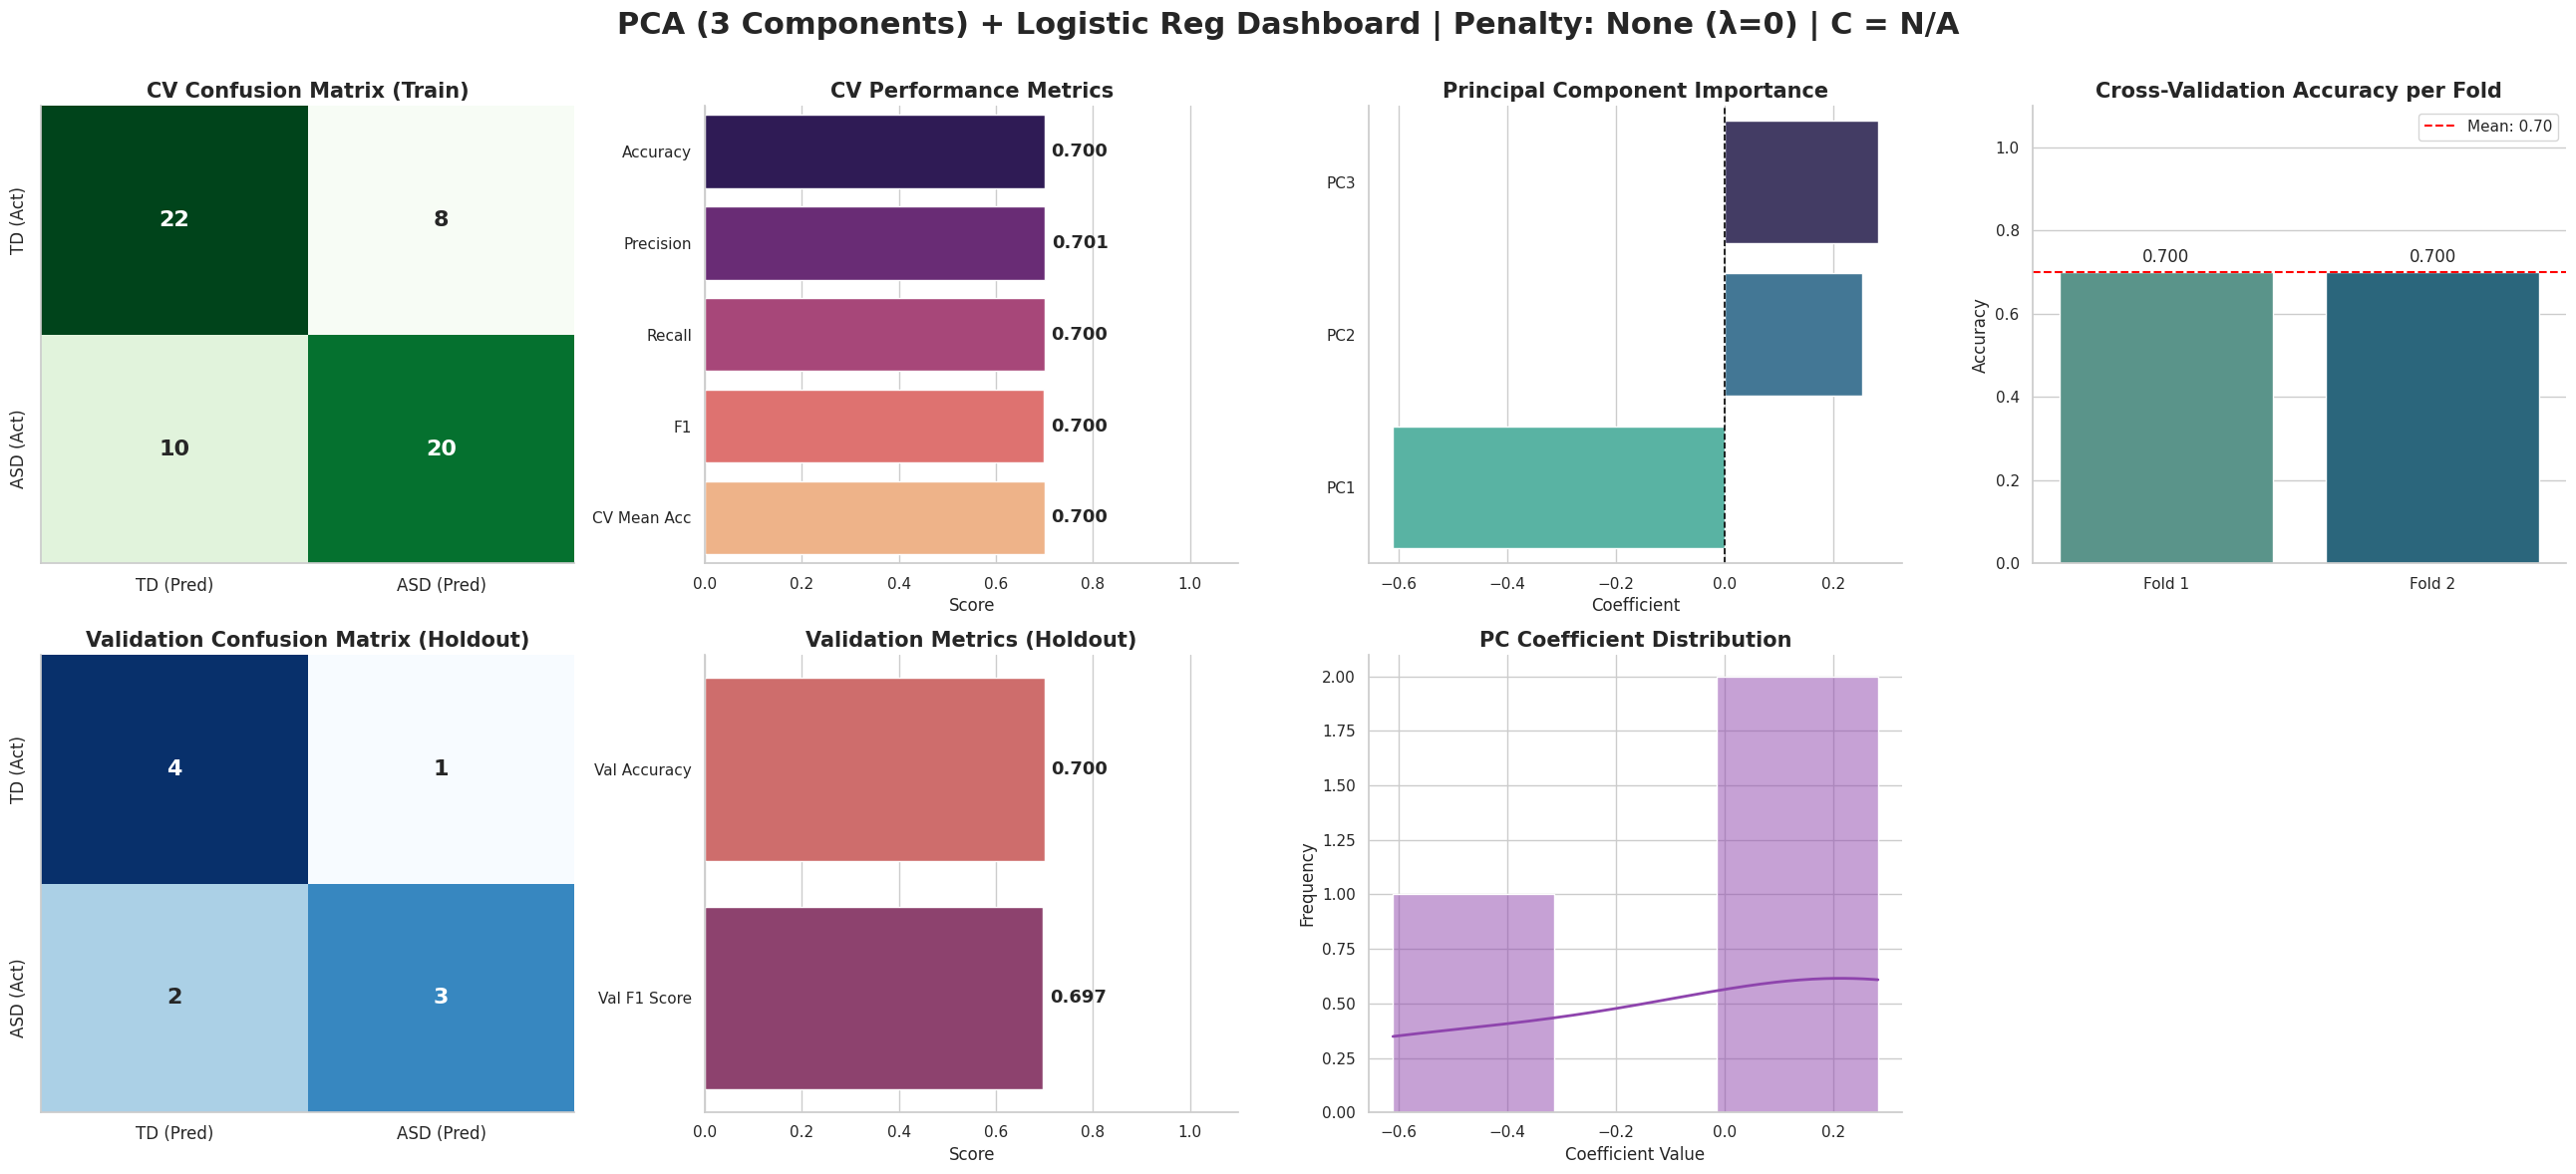


Skipping Experiment 2 for C=0 (No Regularization) as it is equivalent to L1.


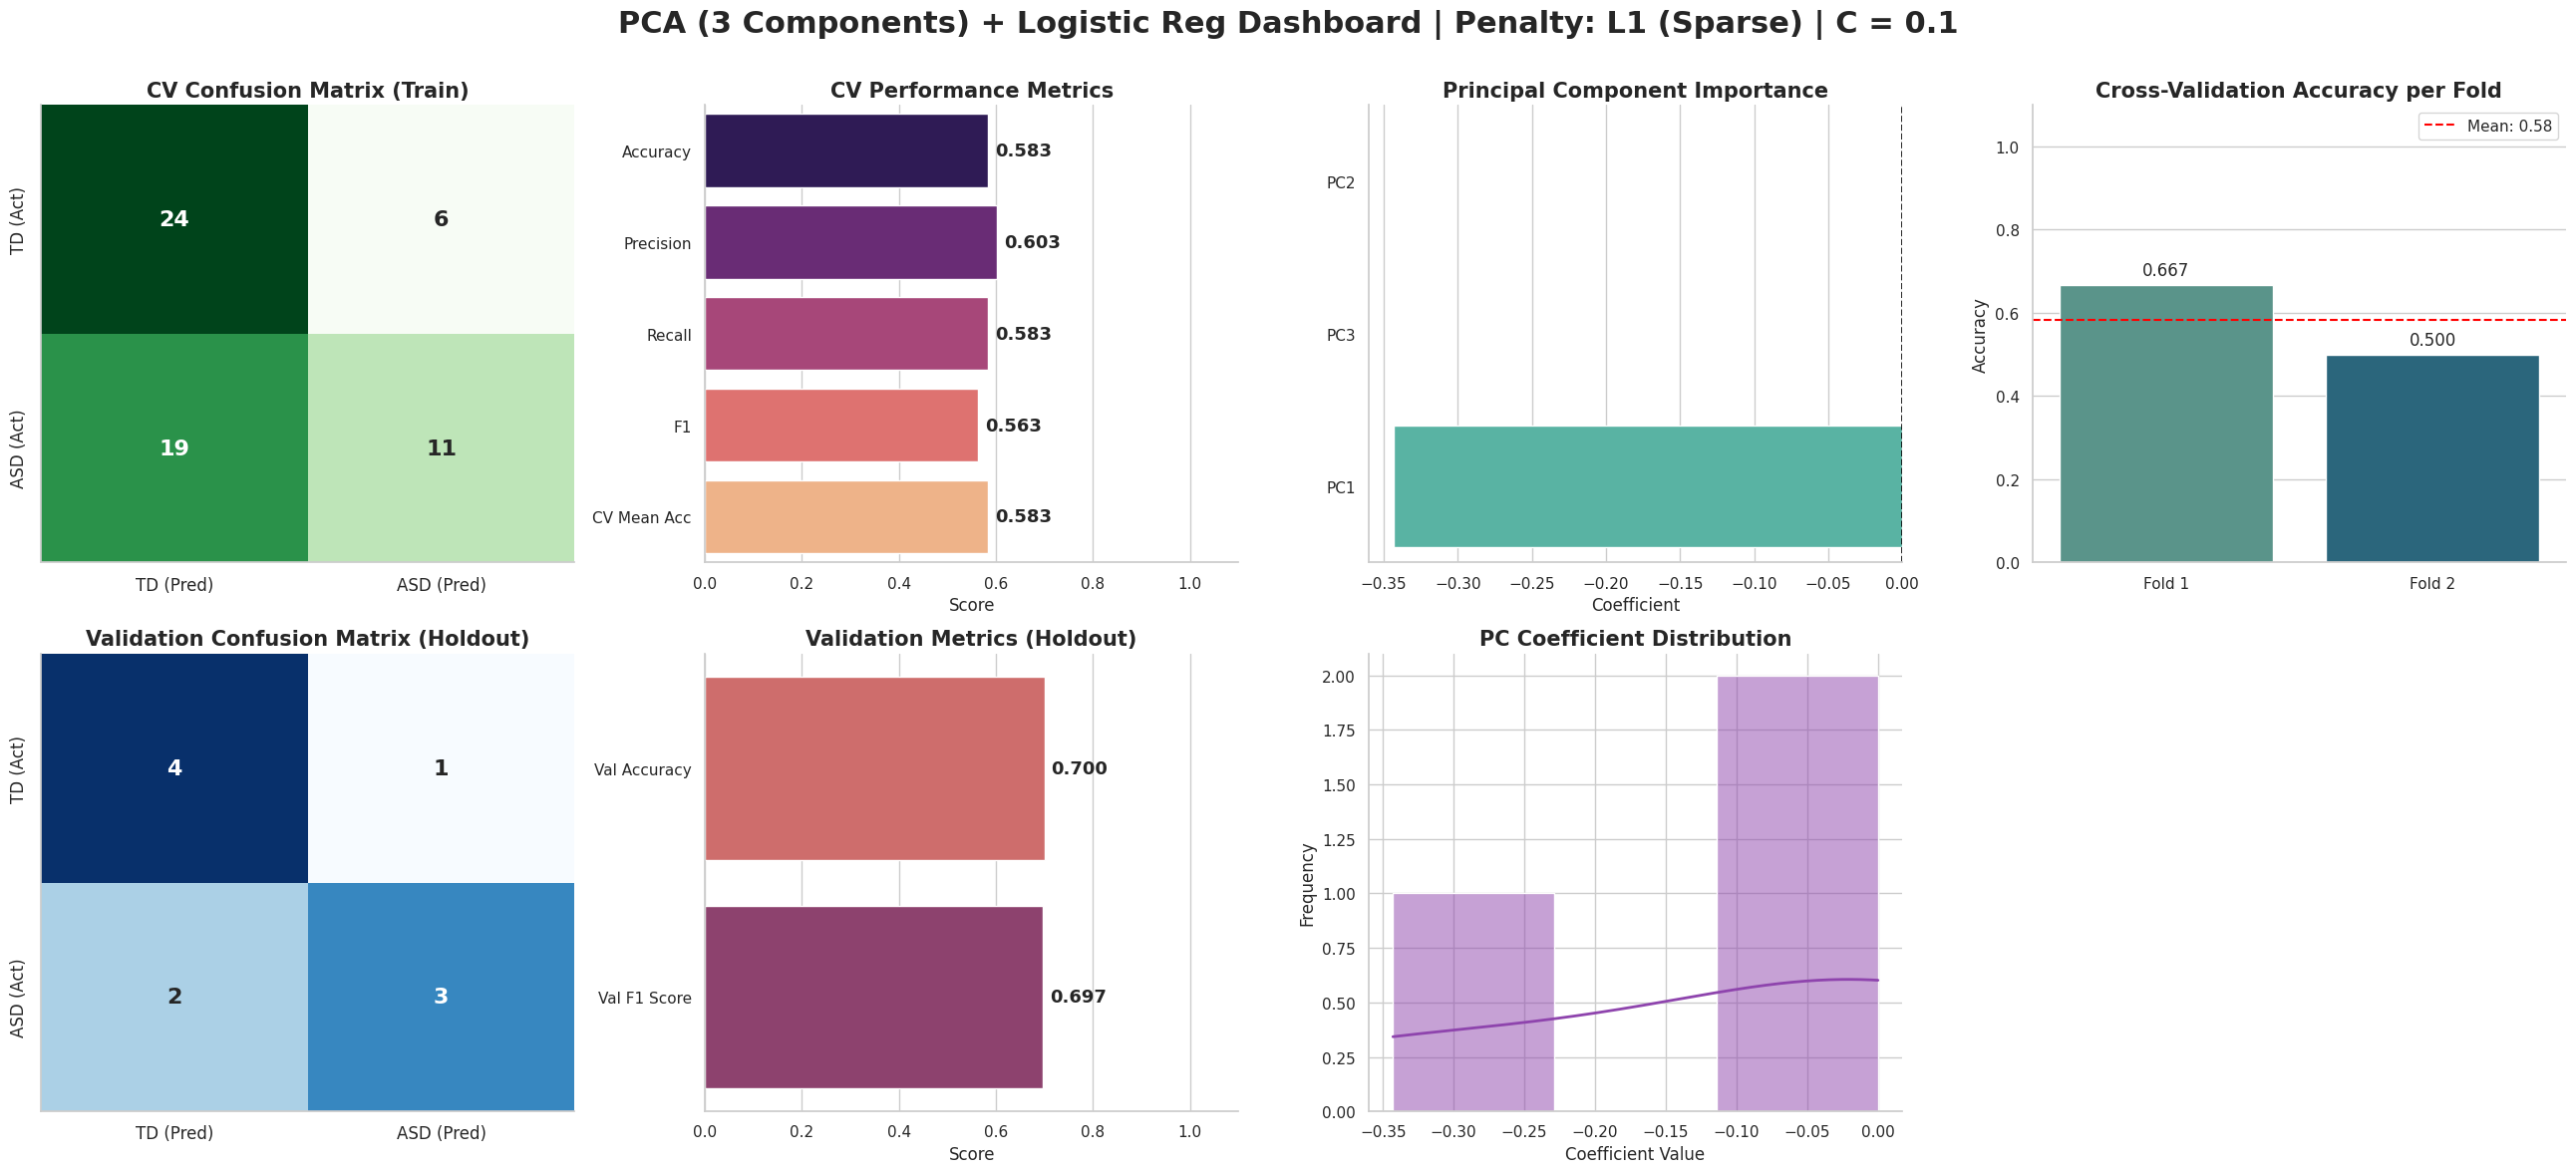

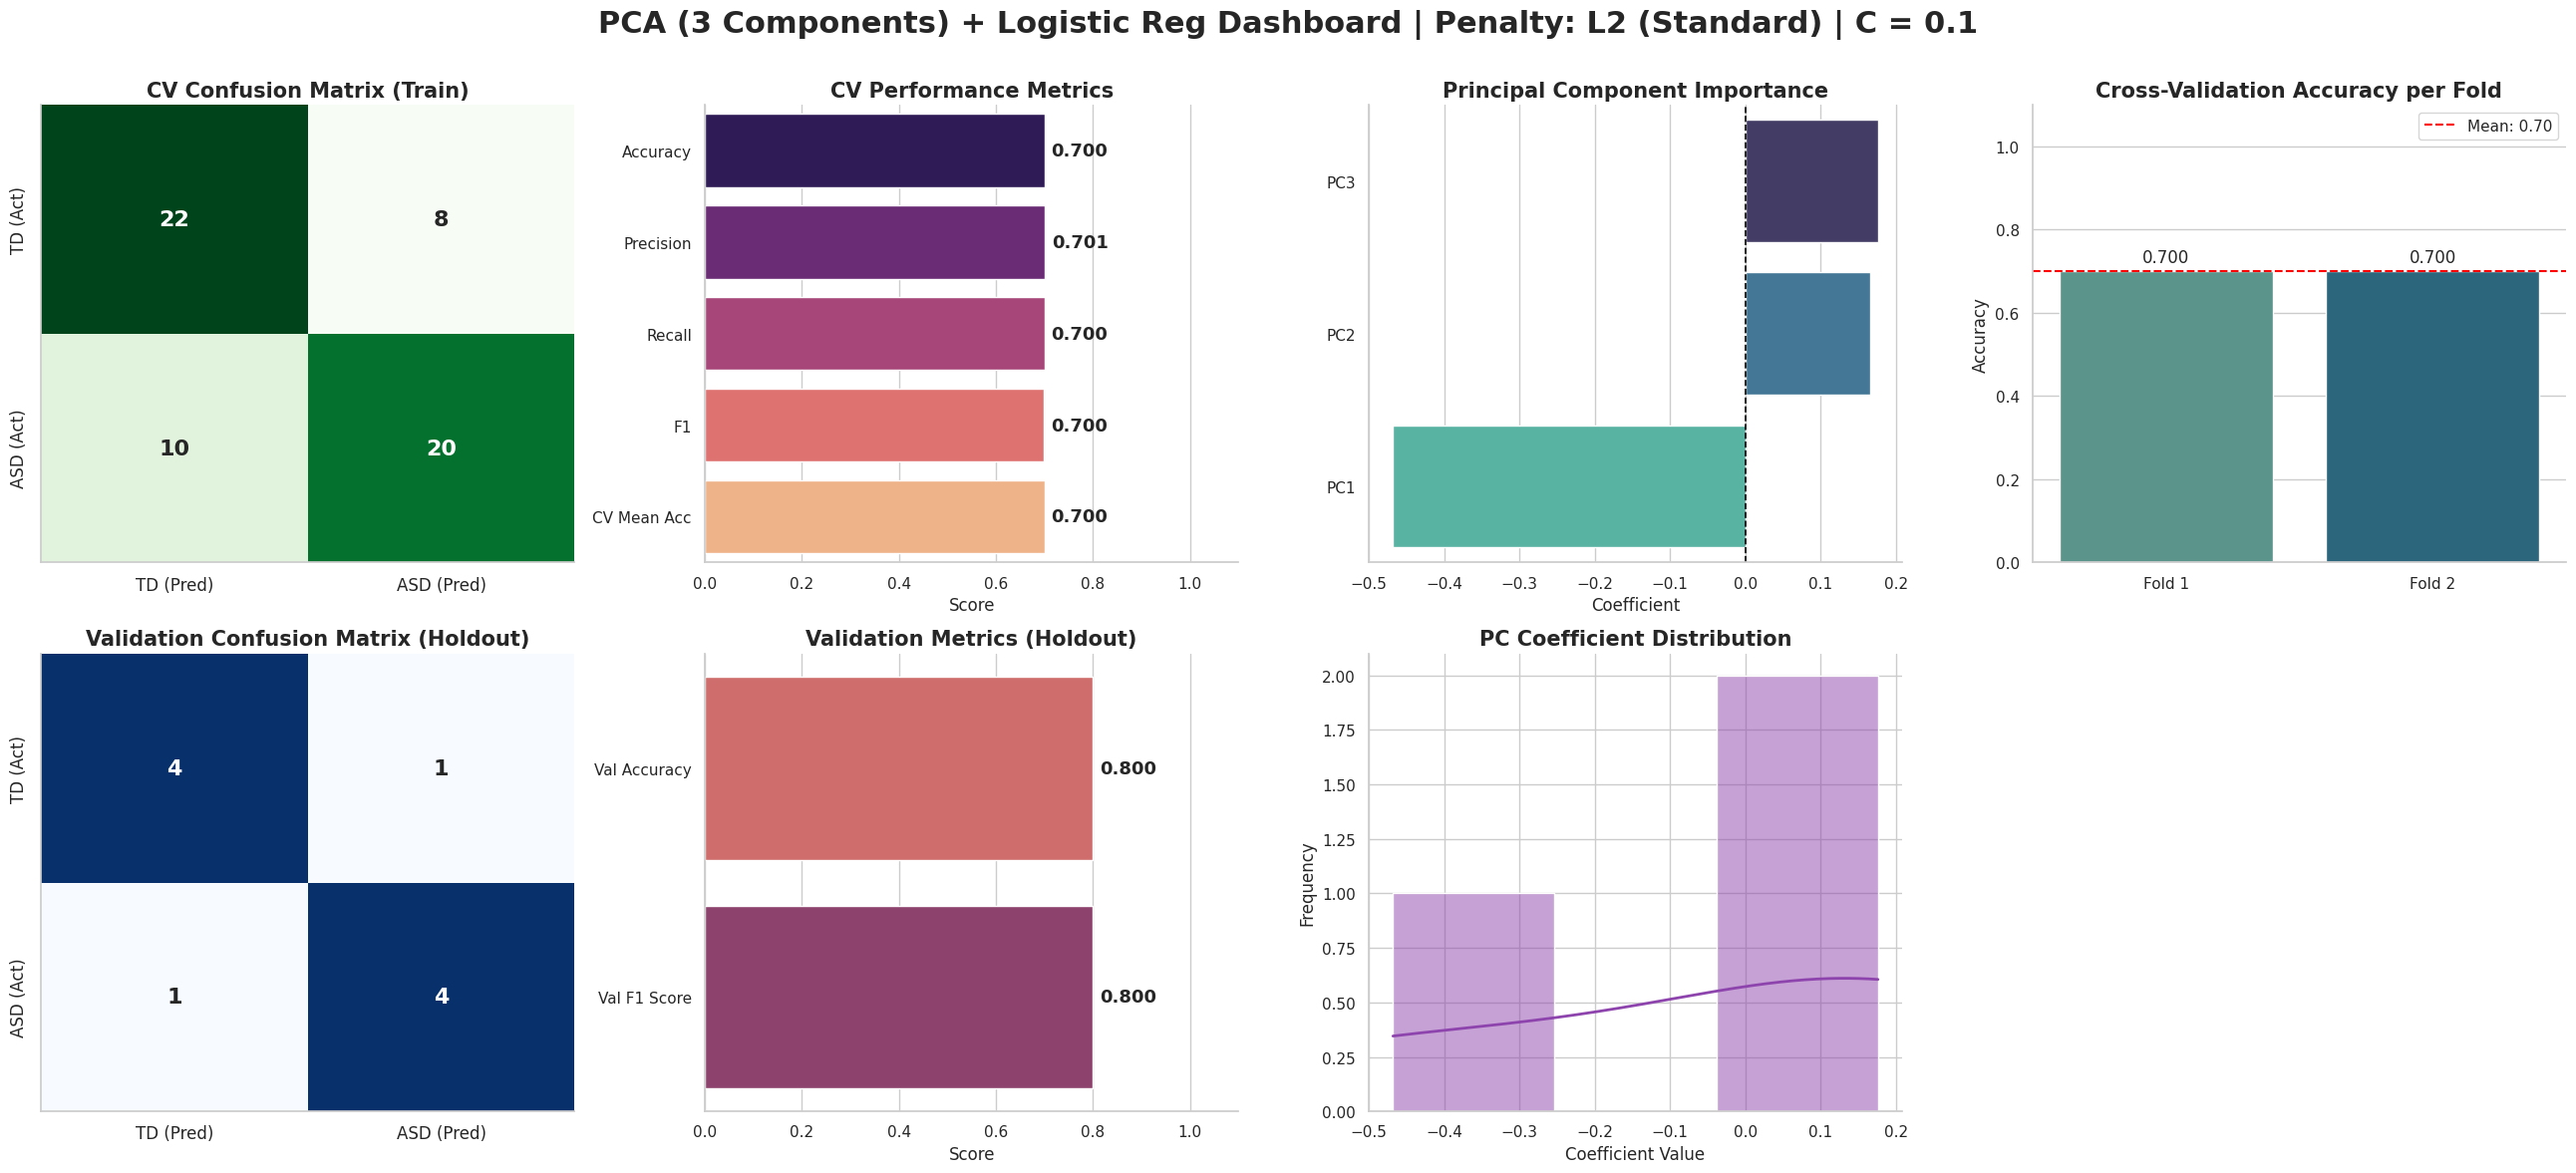

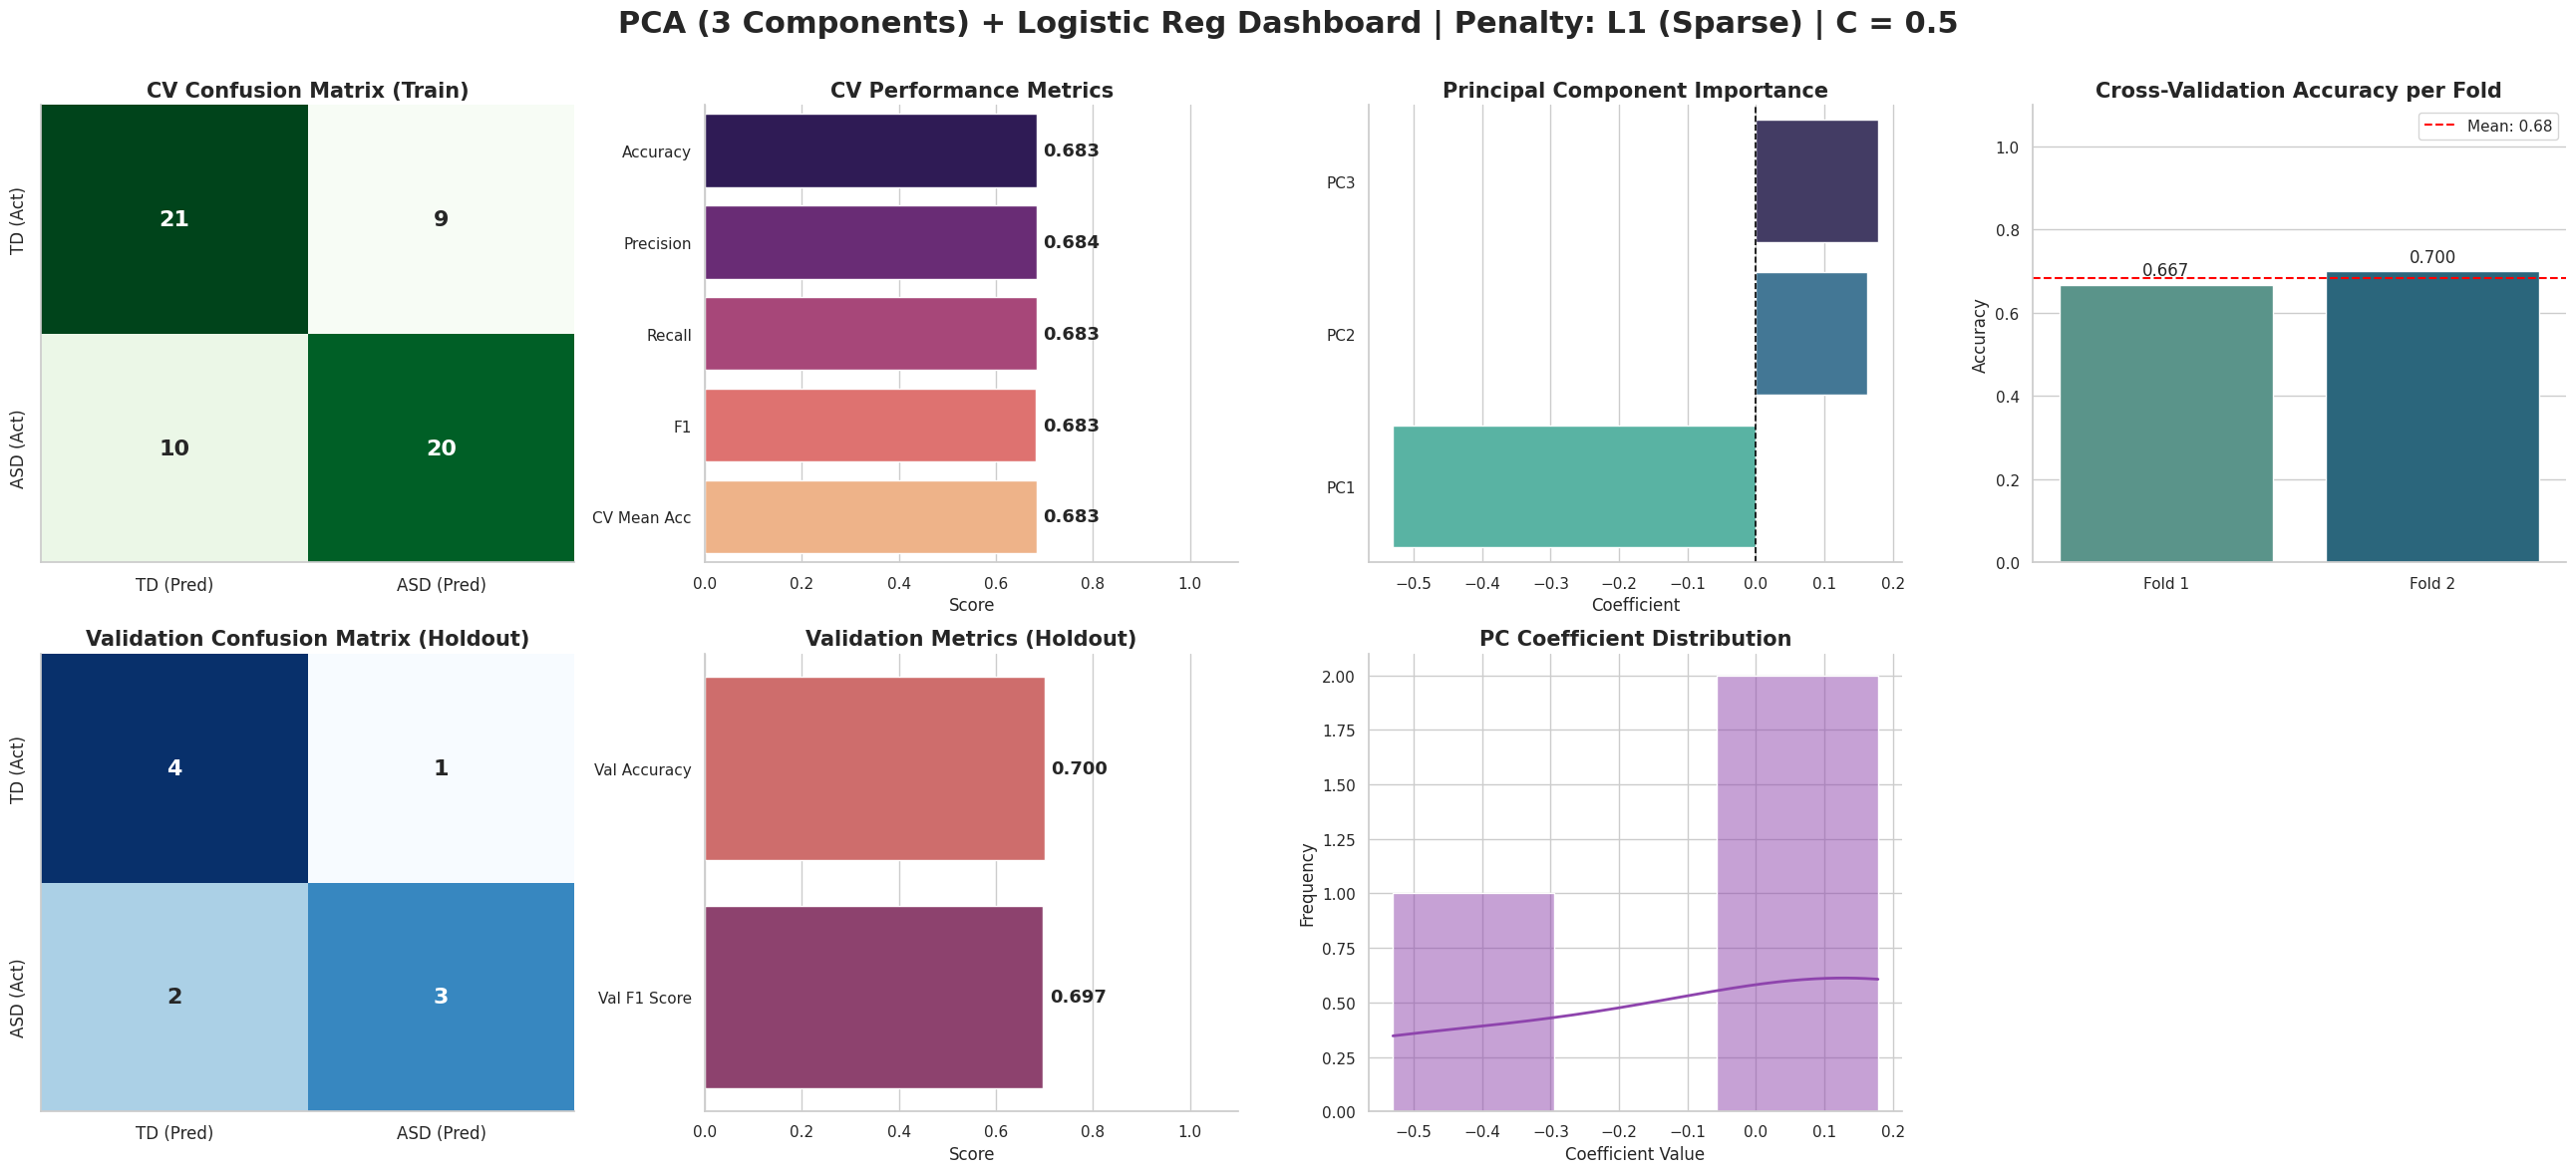

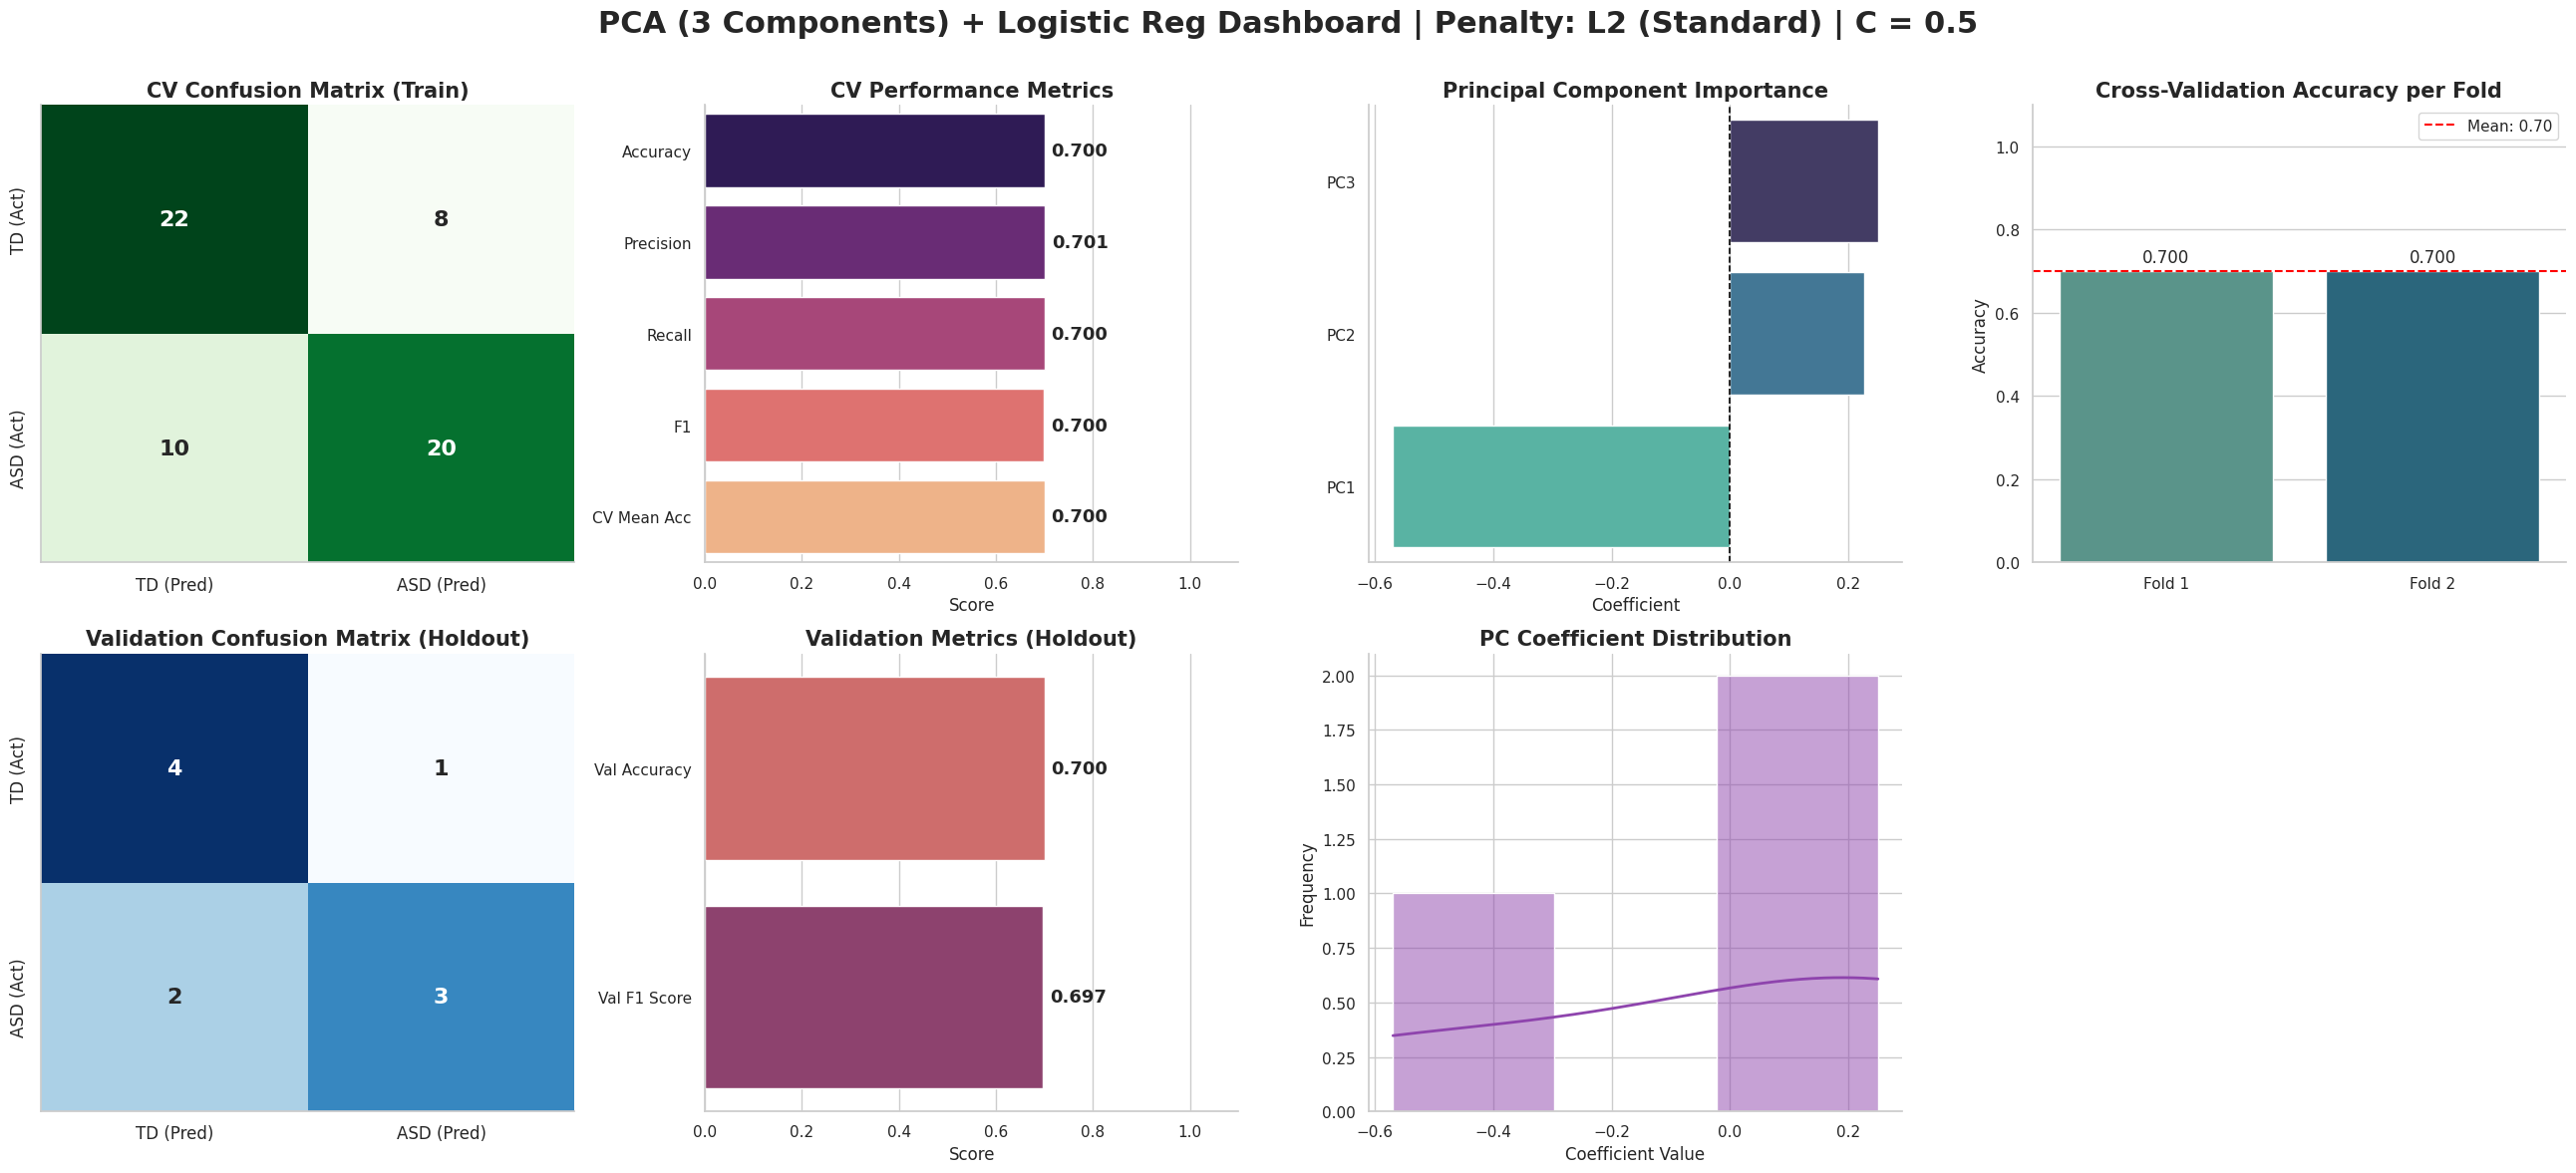

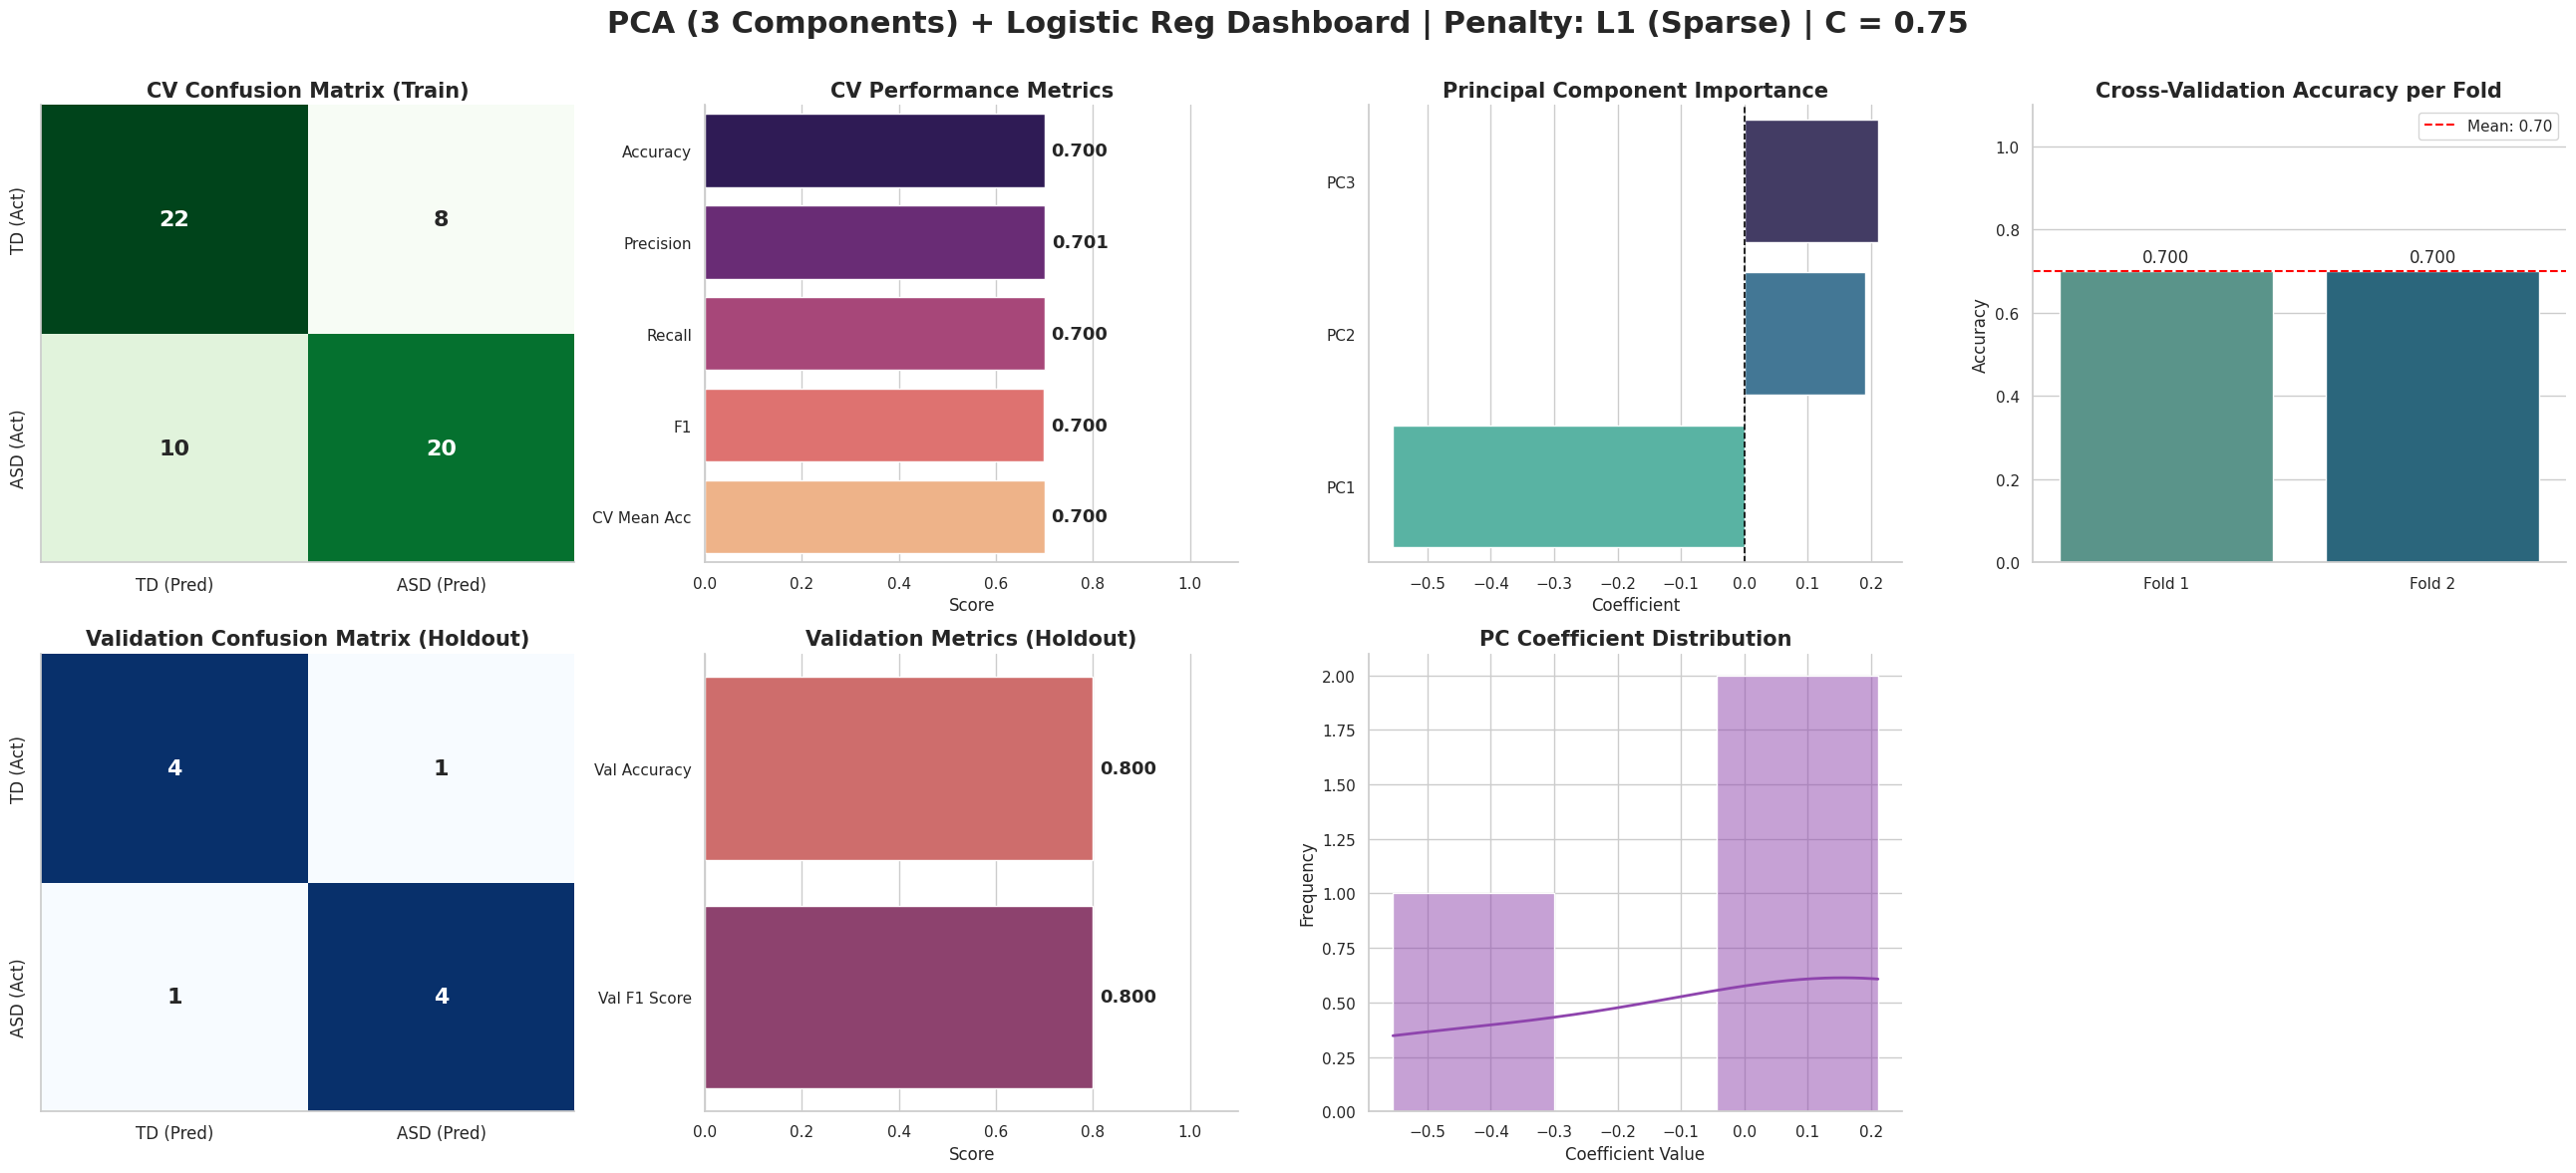

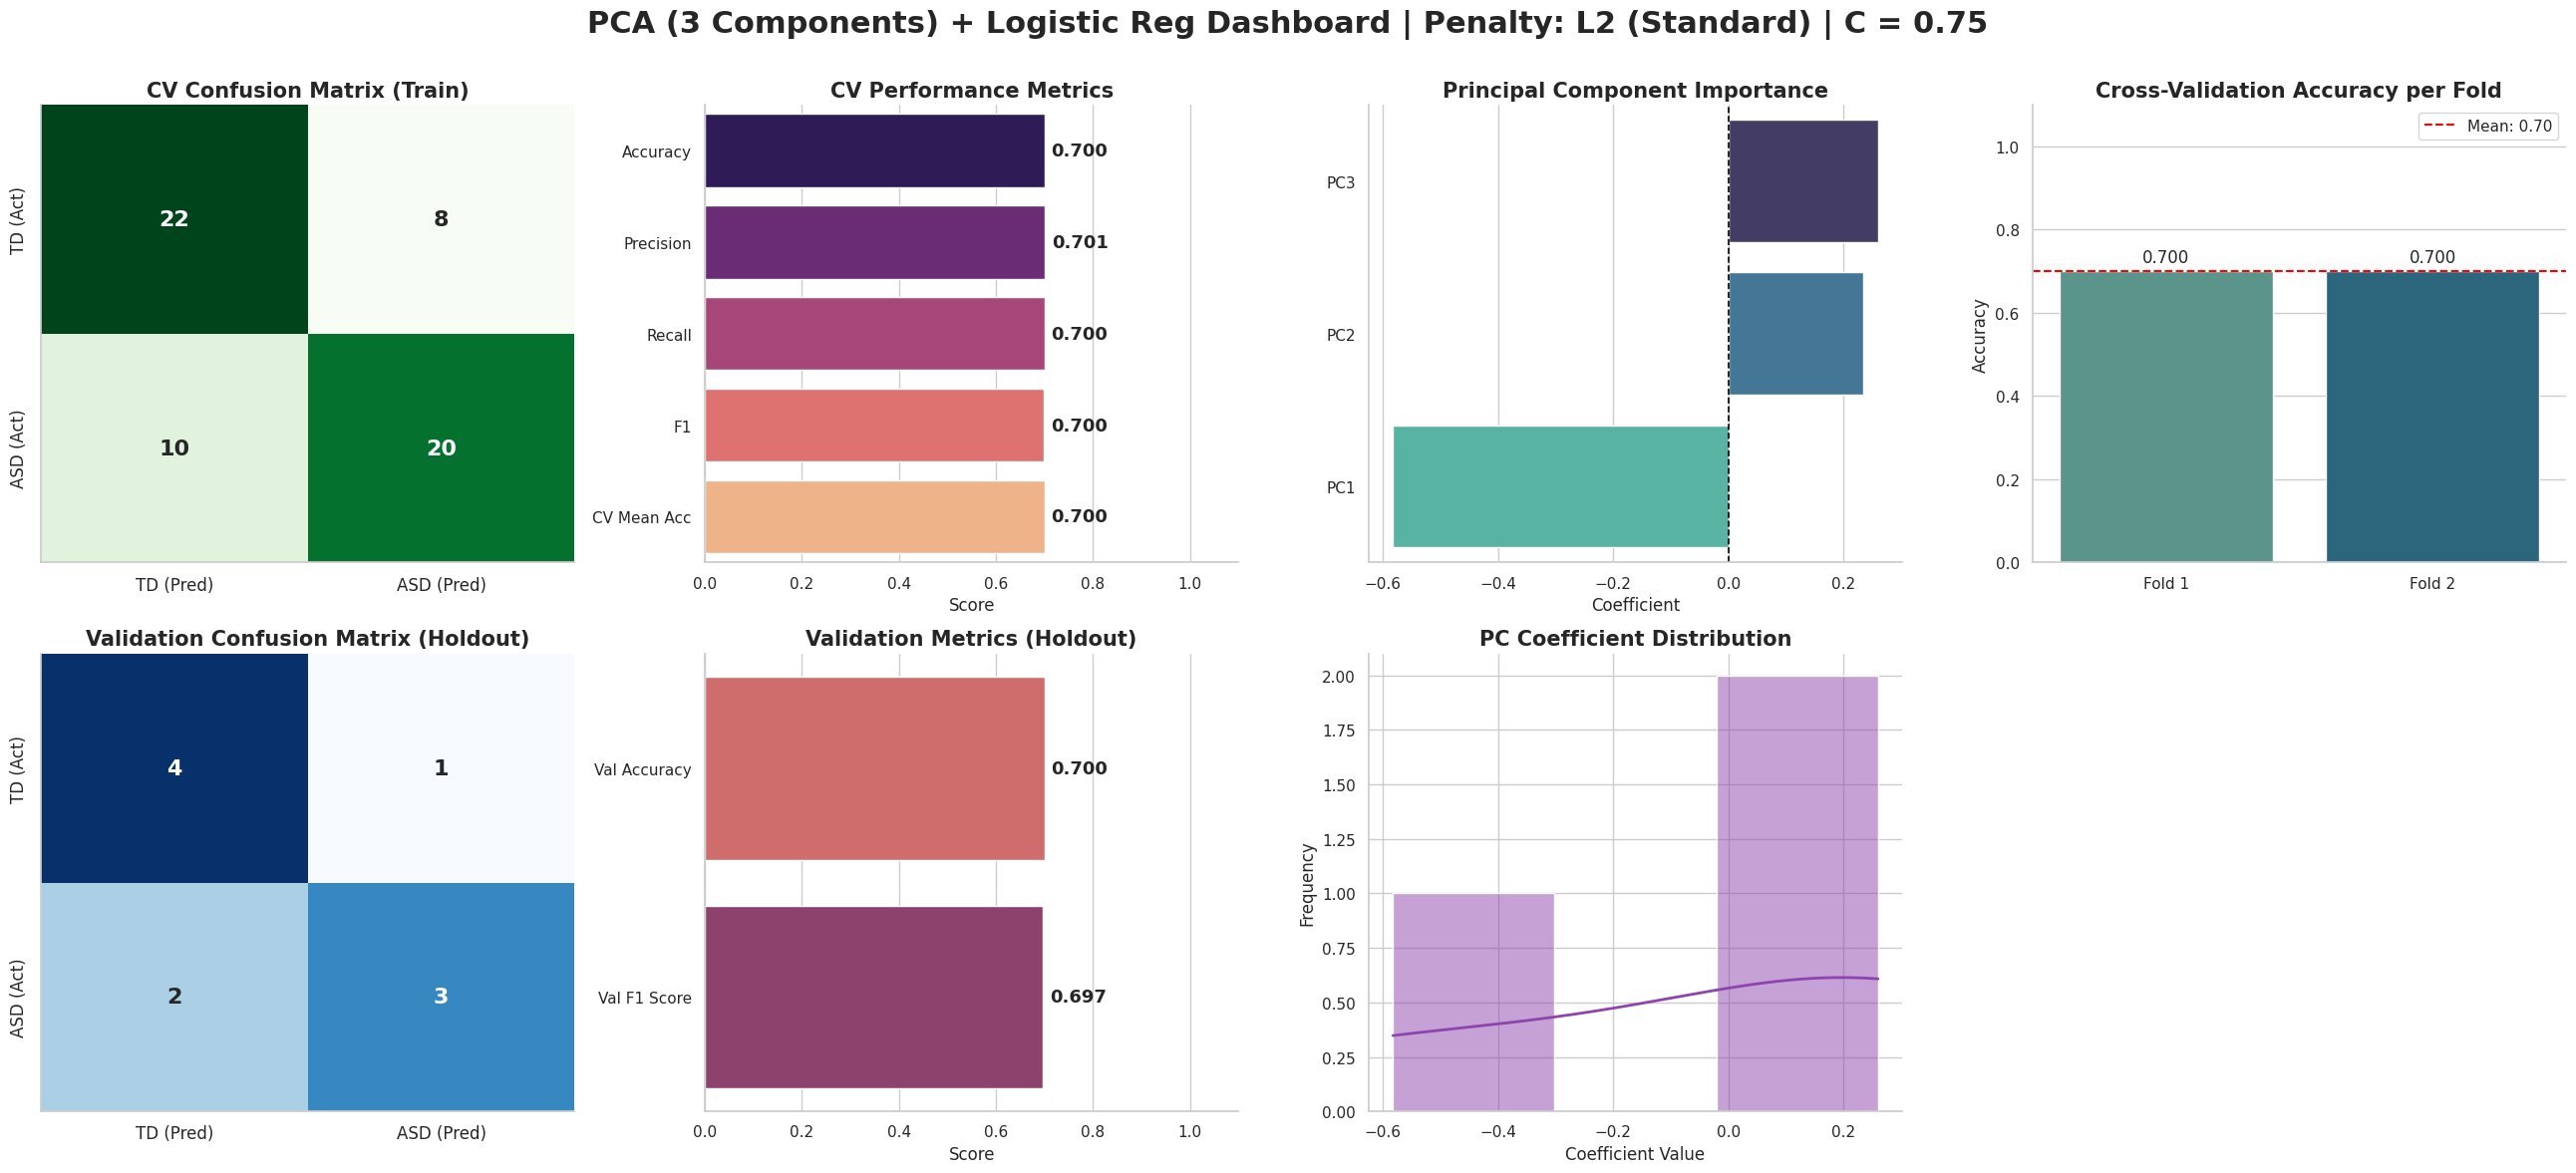

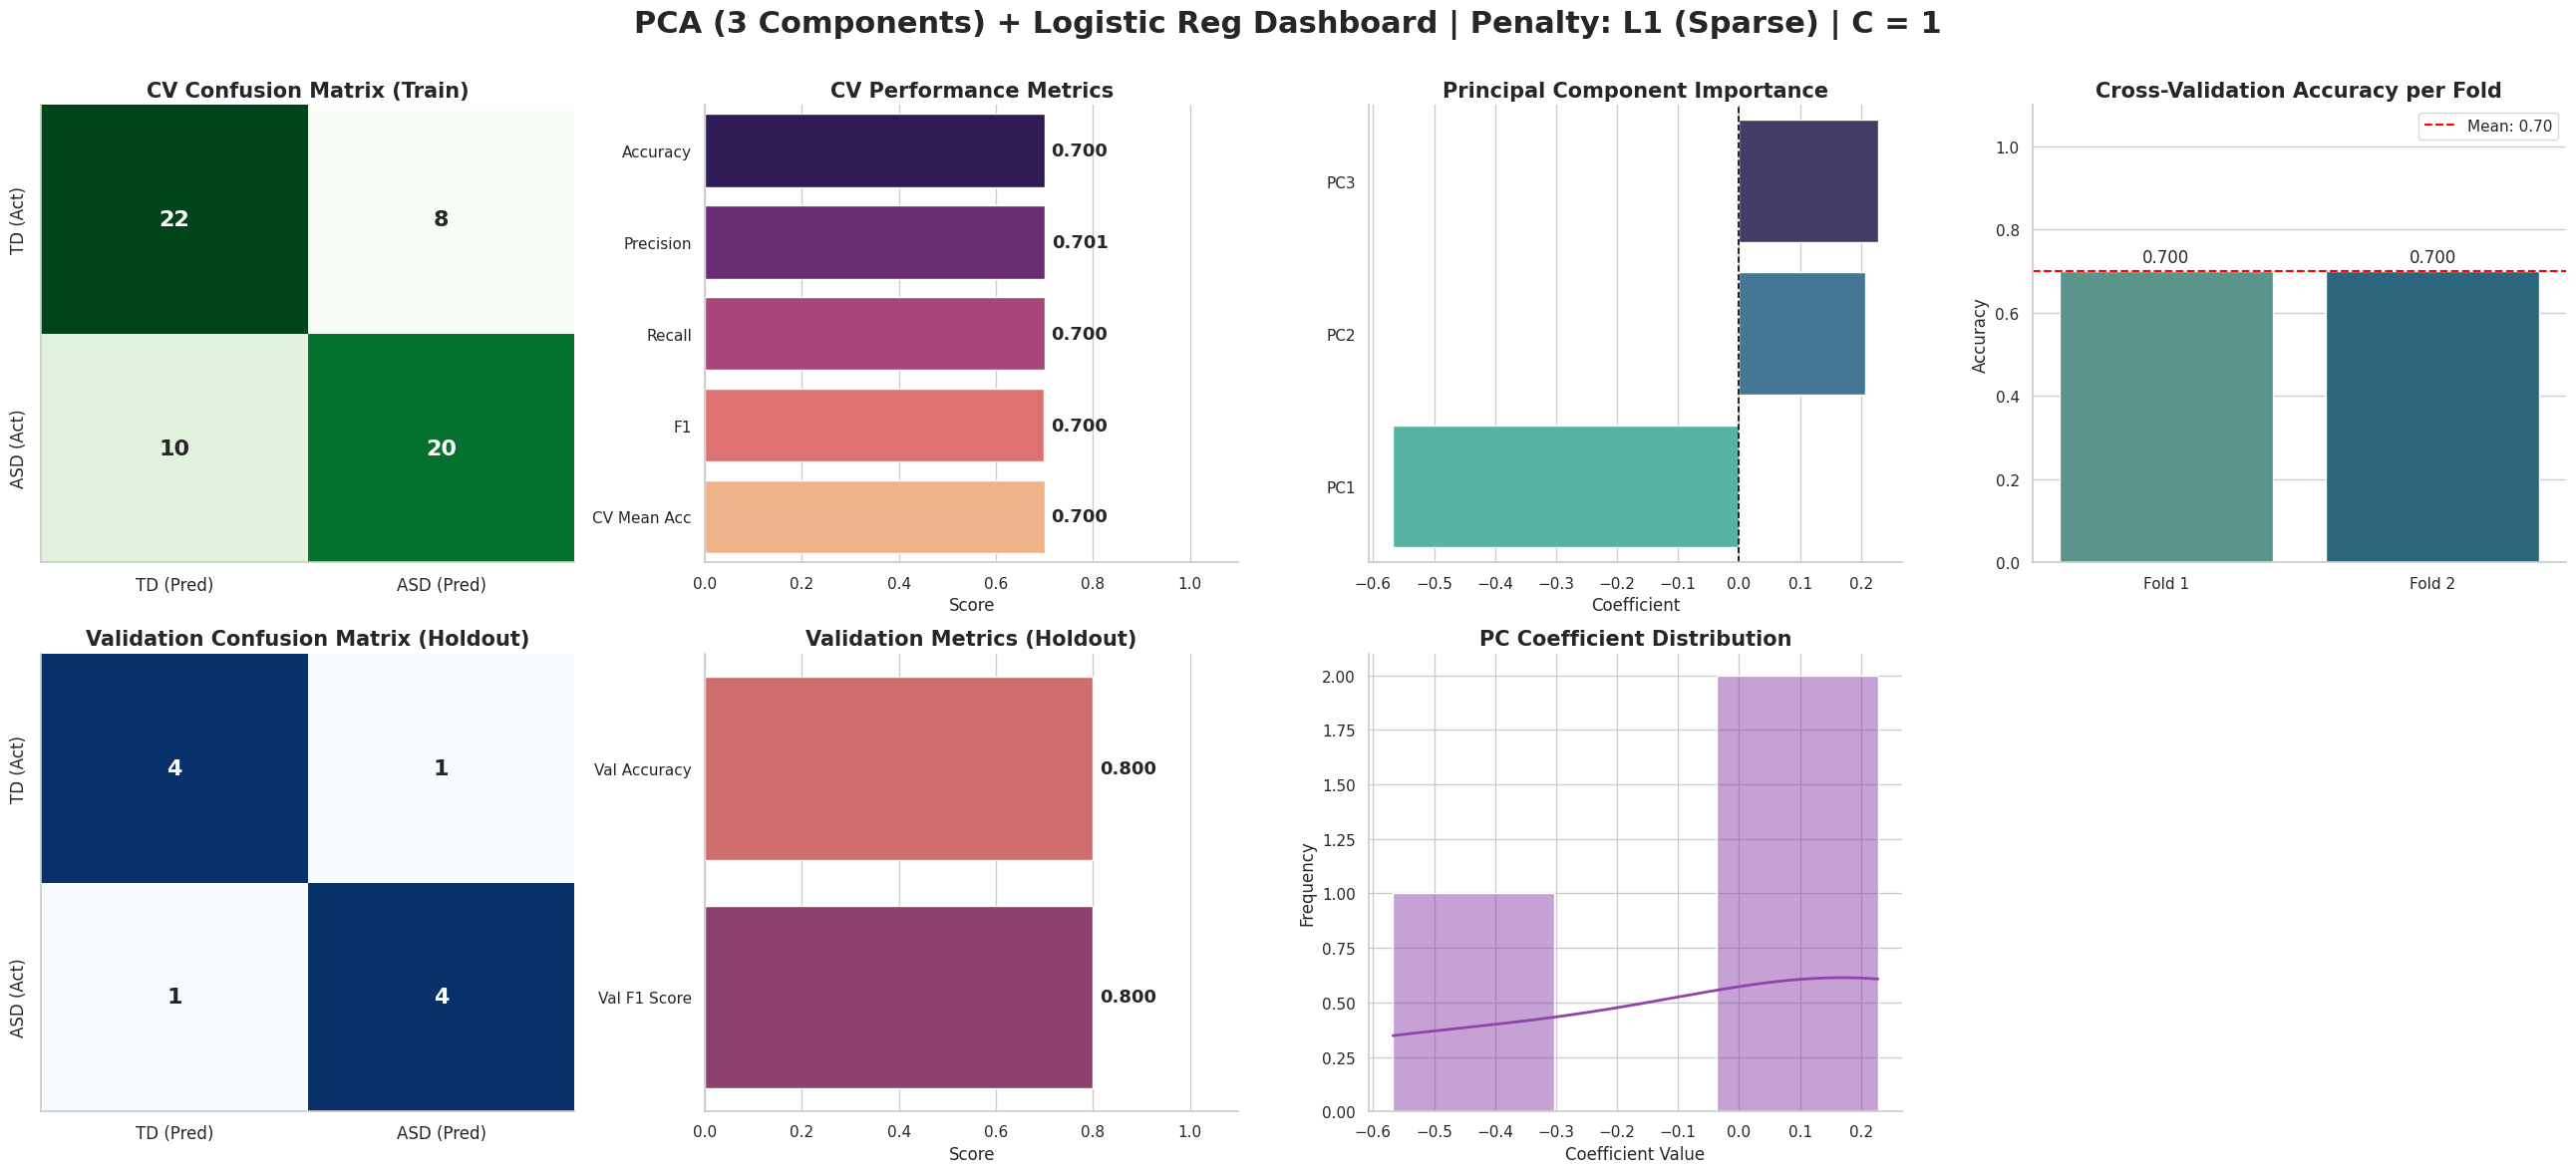

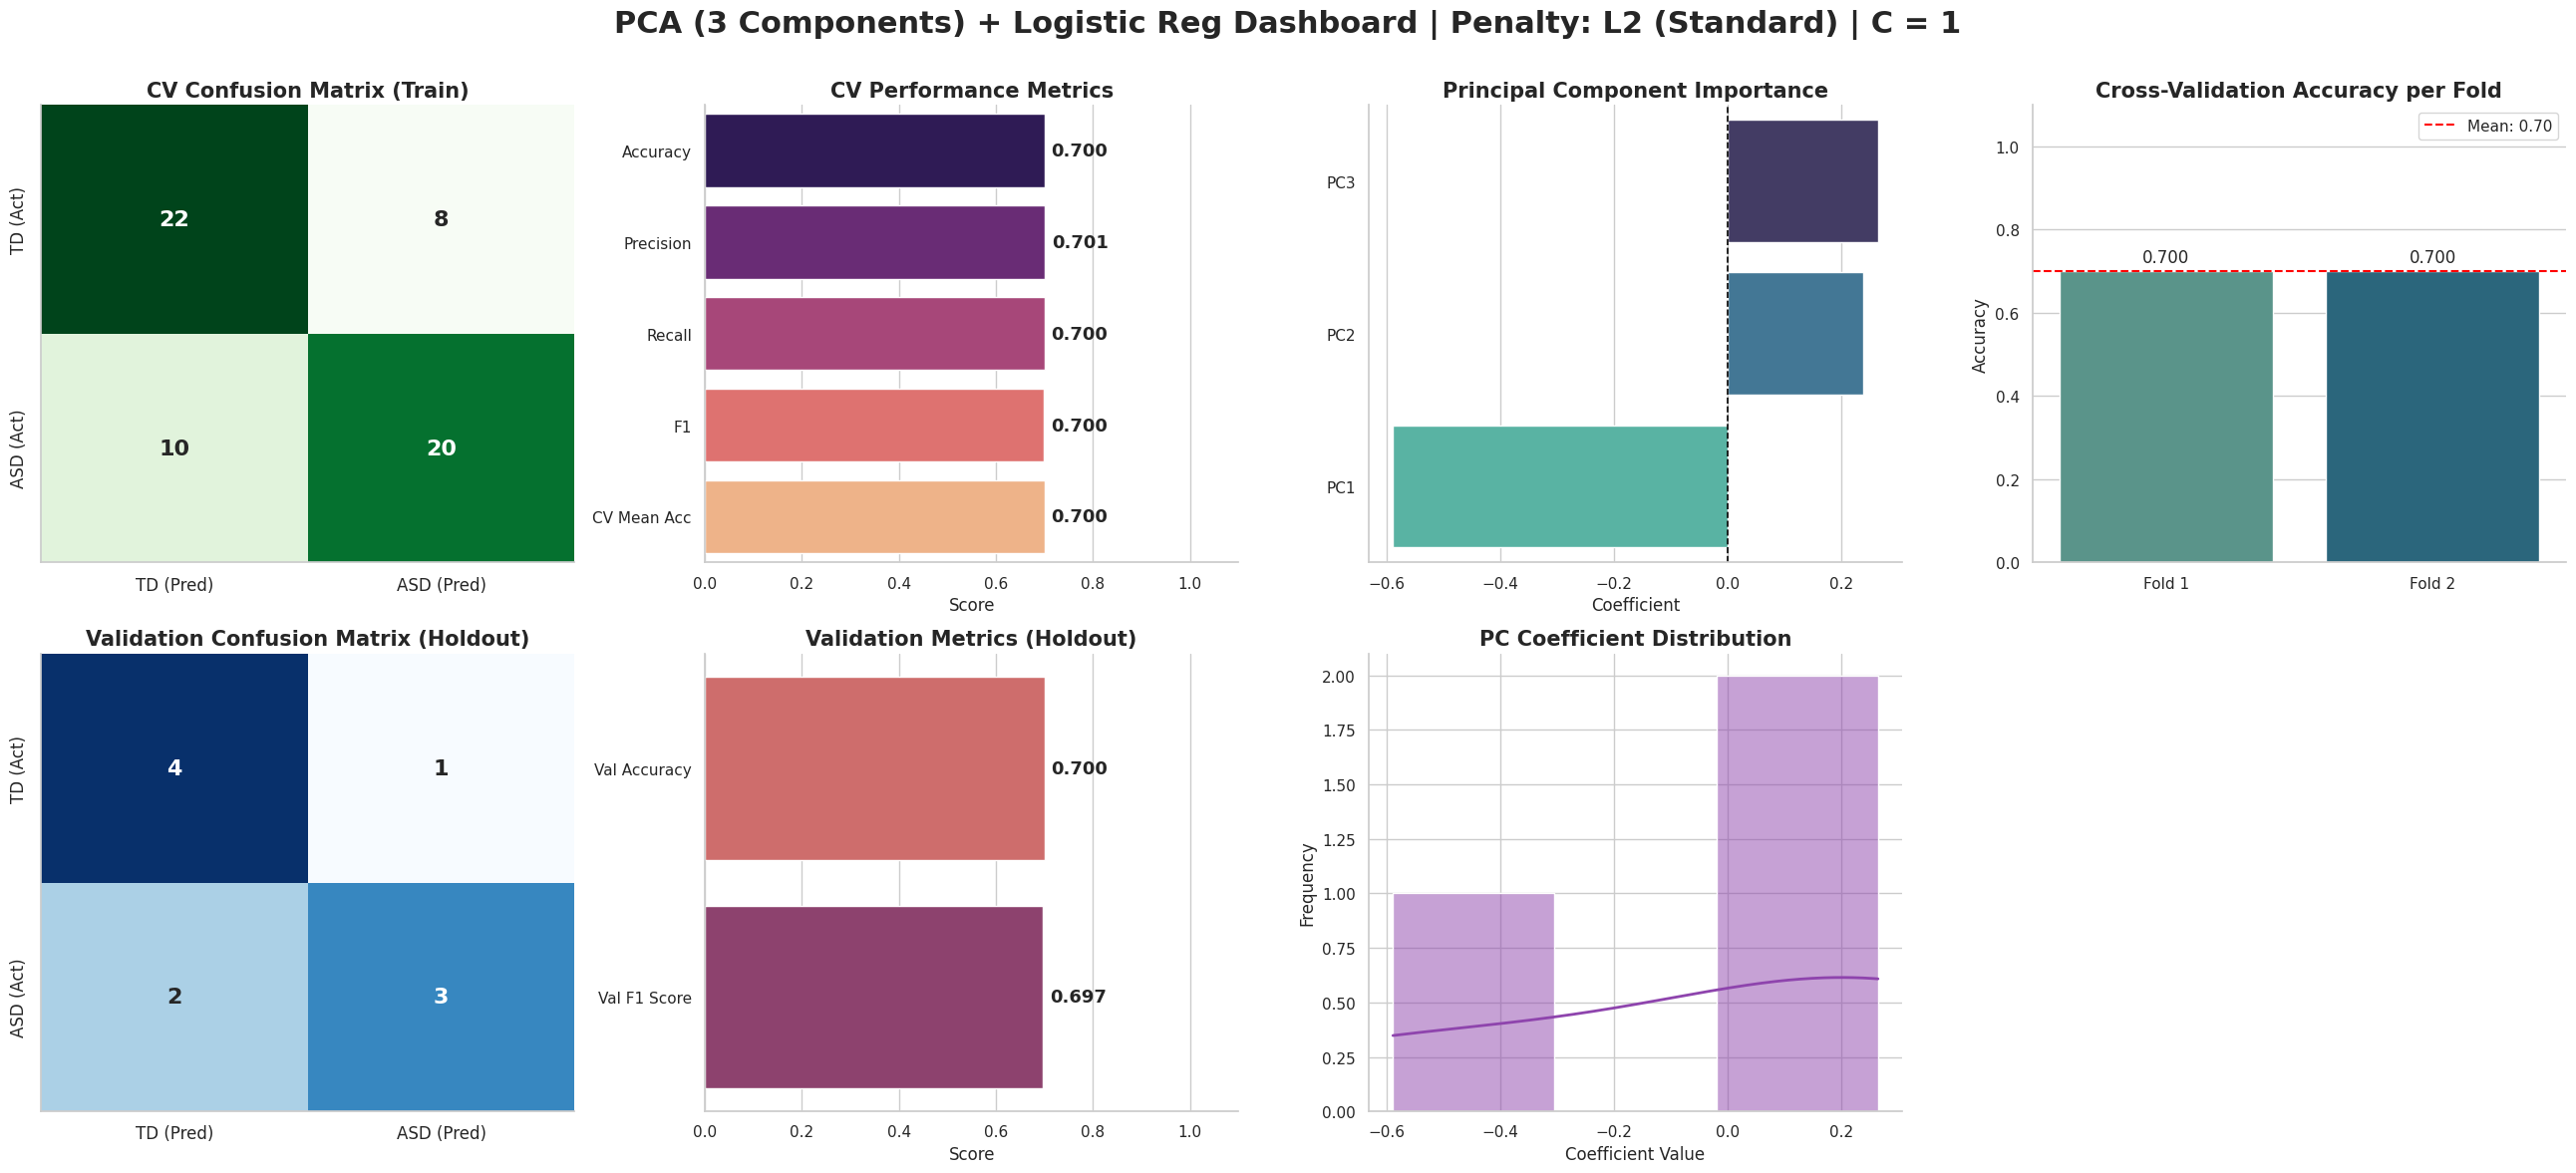

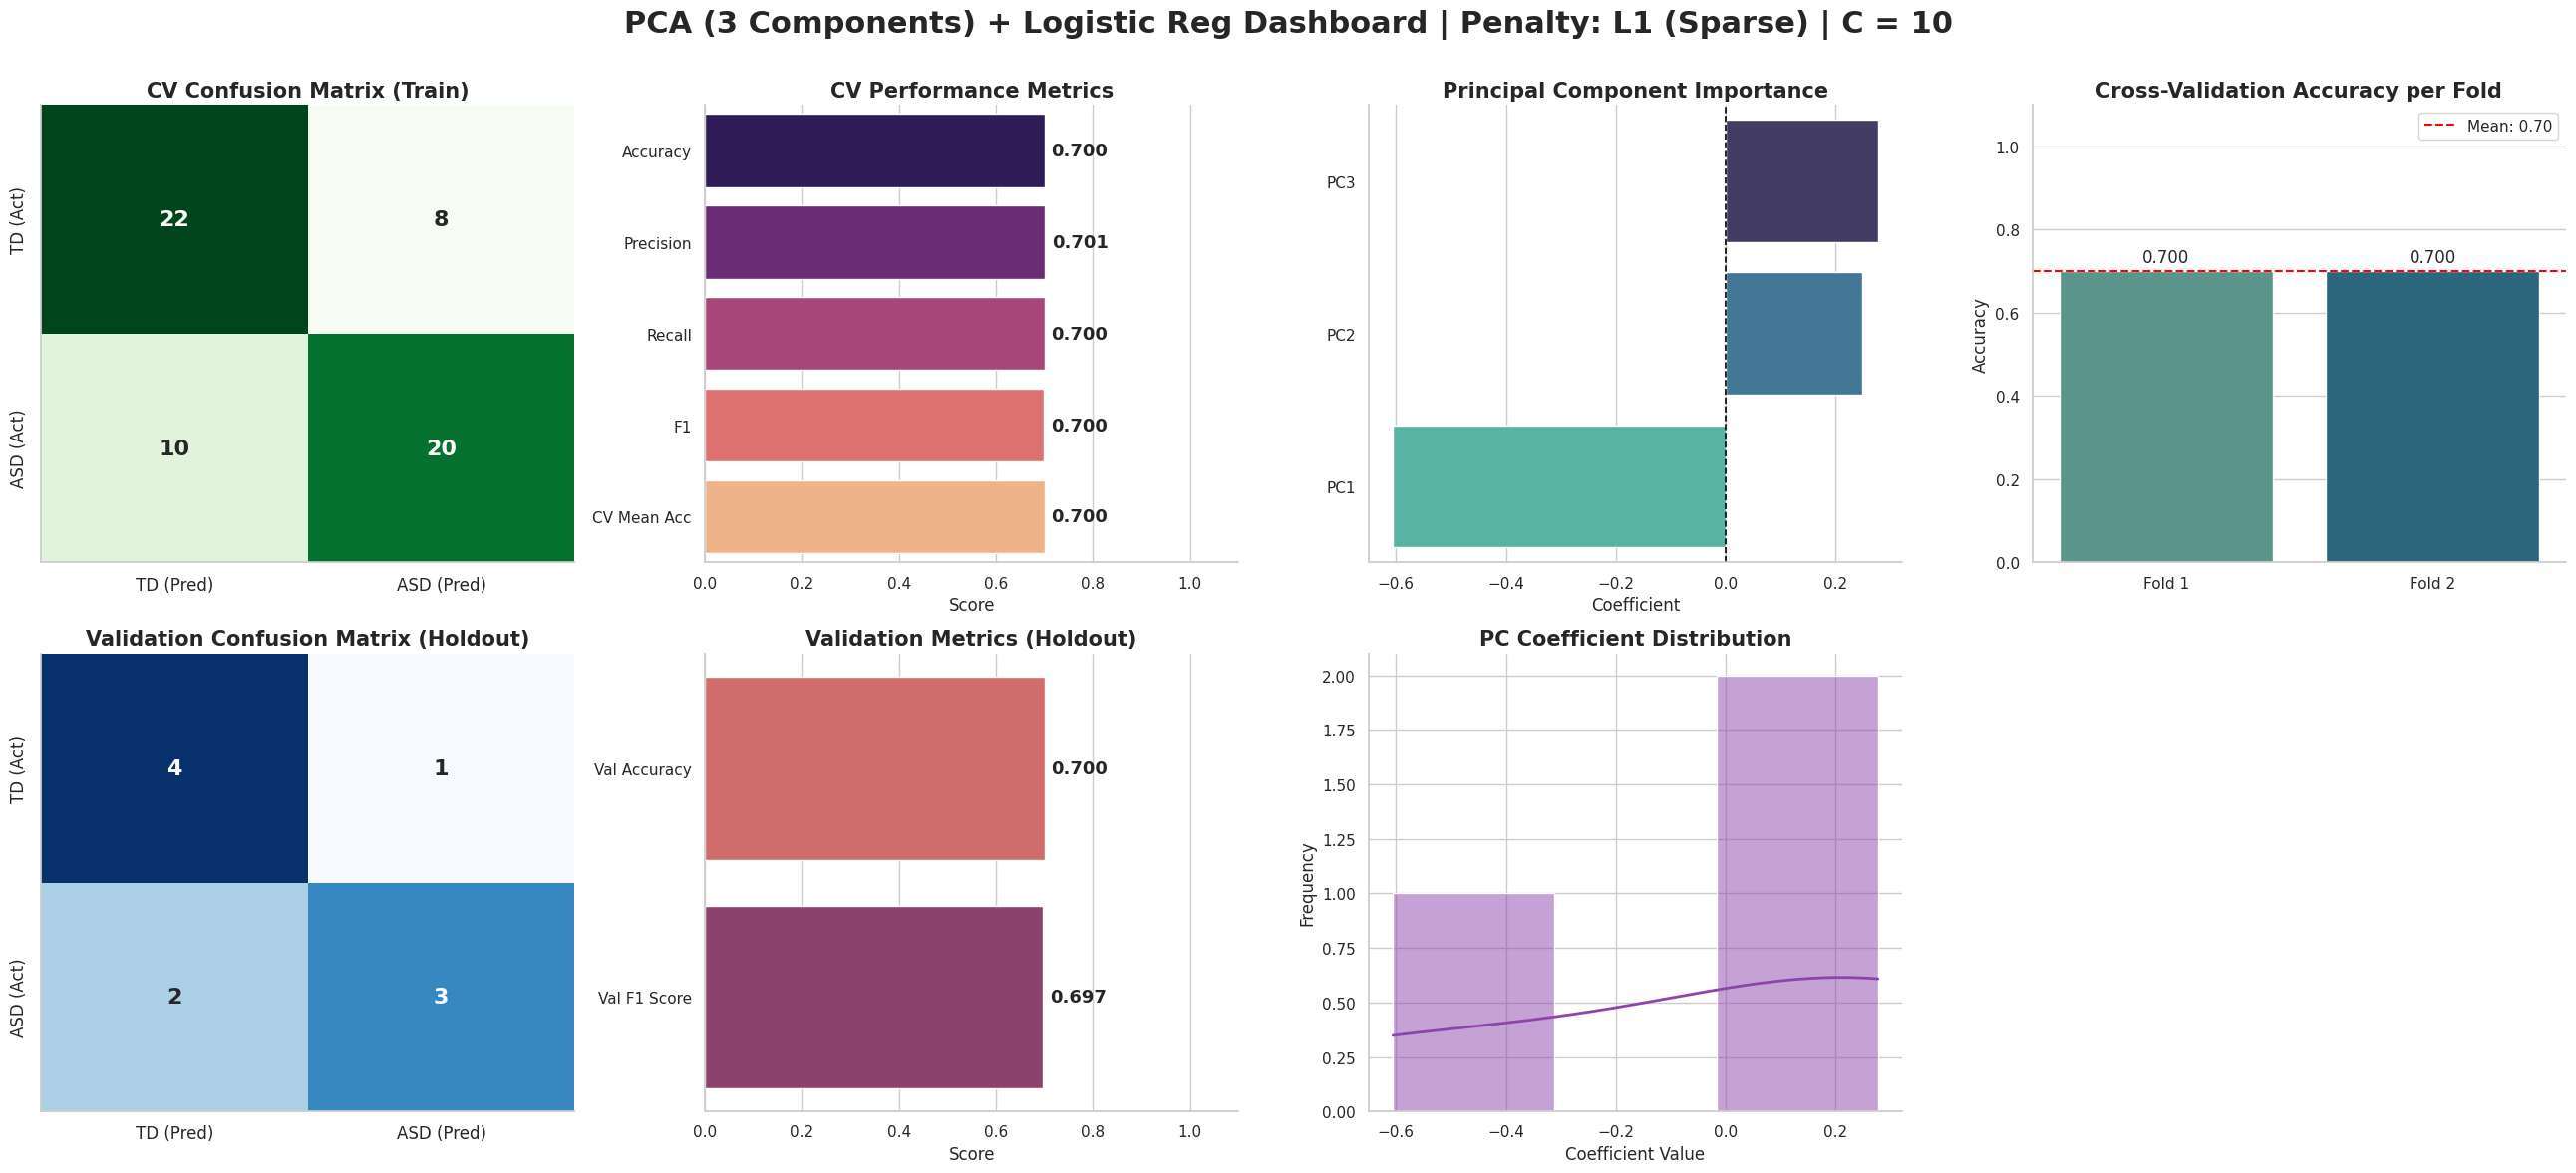

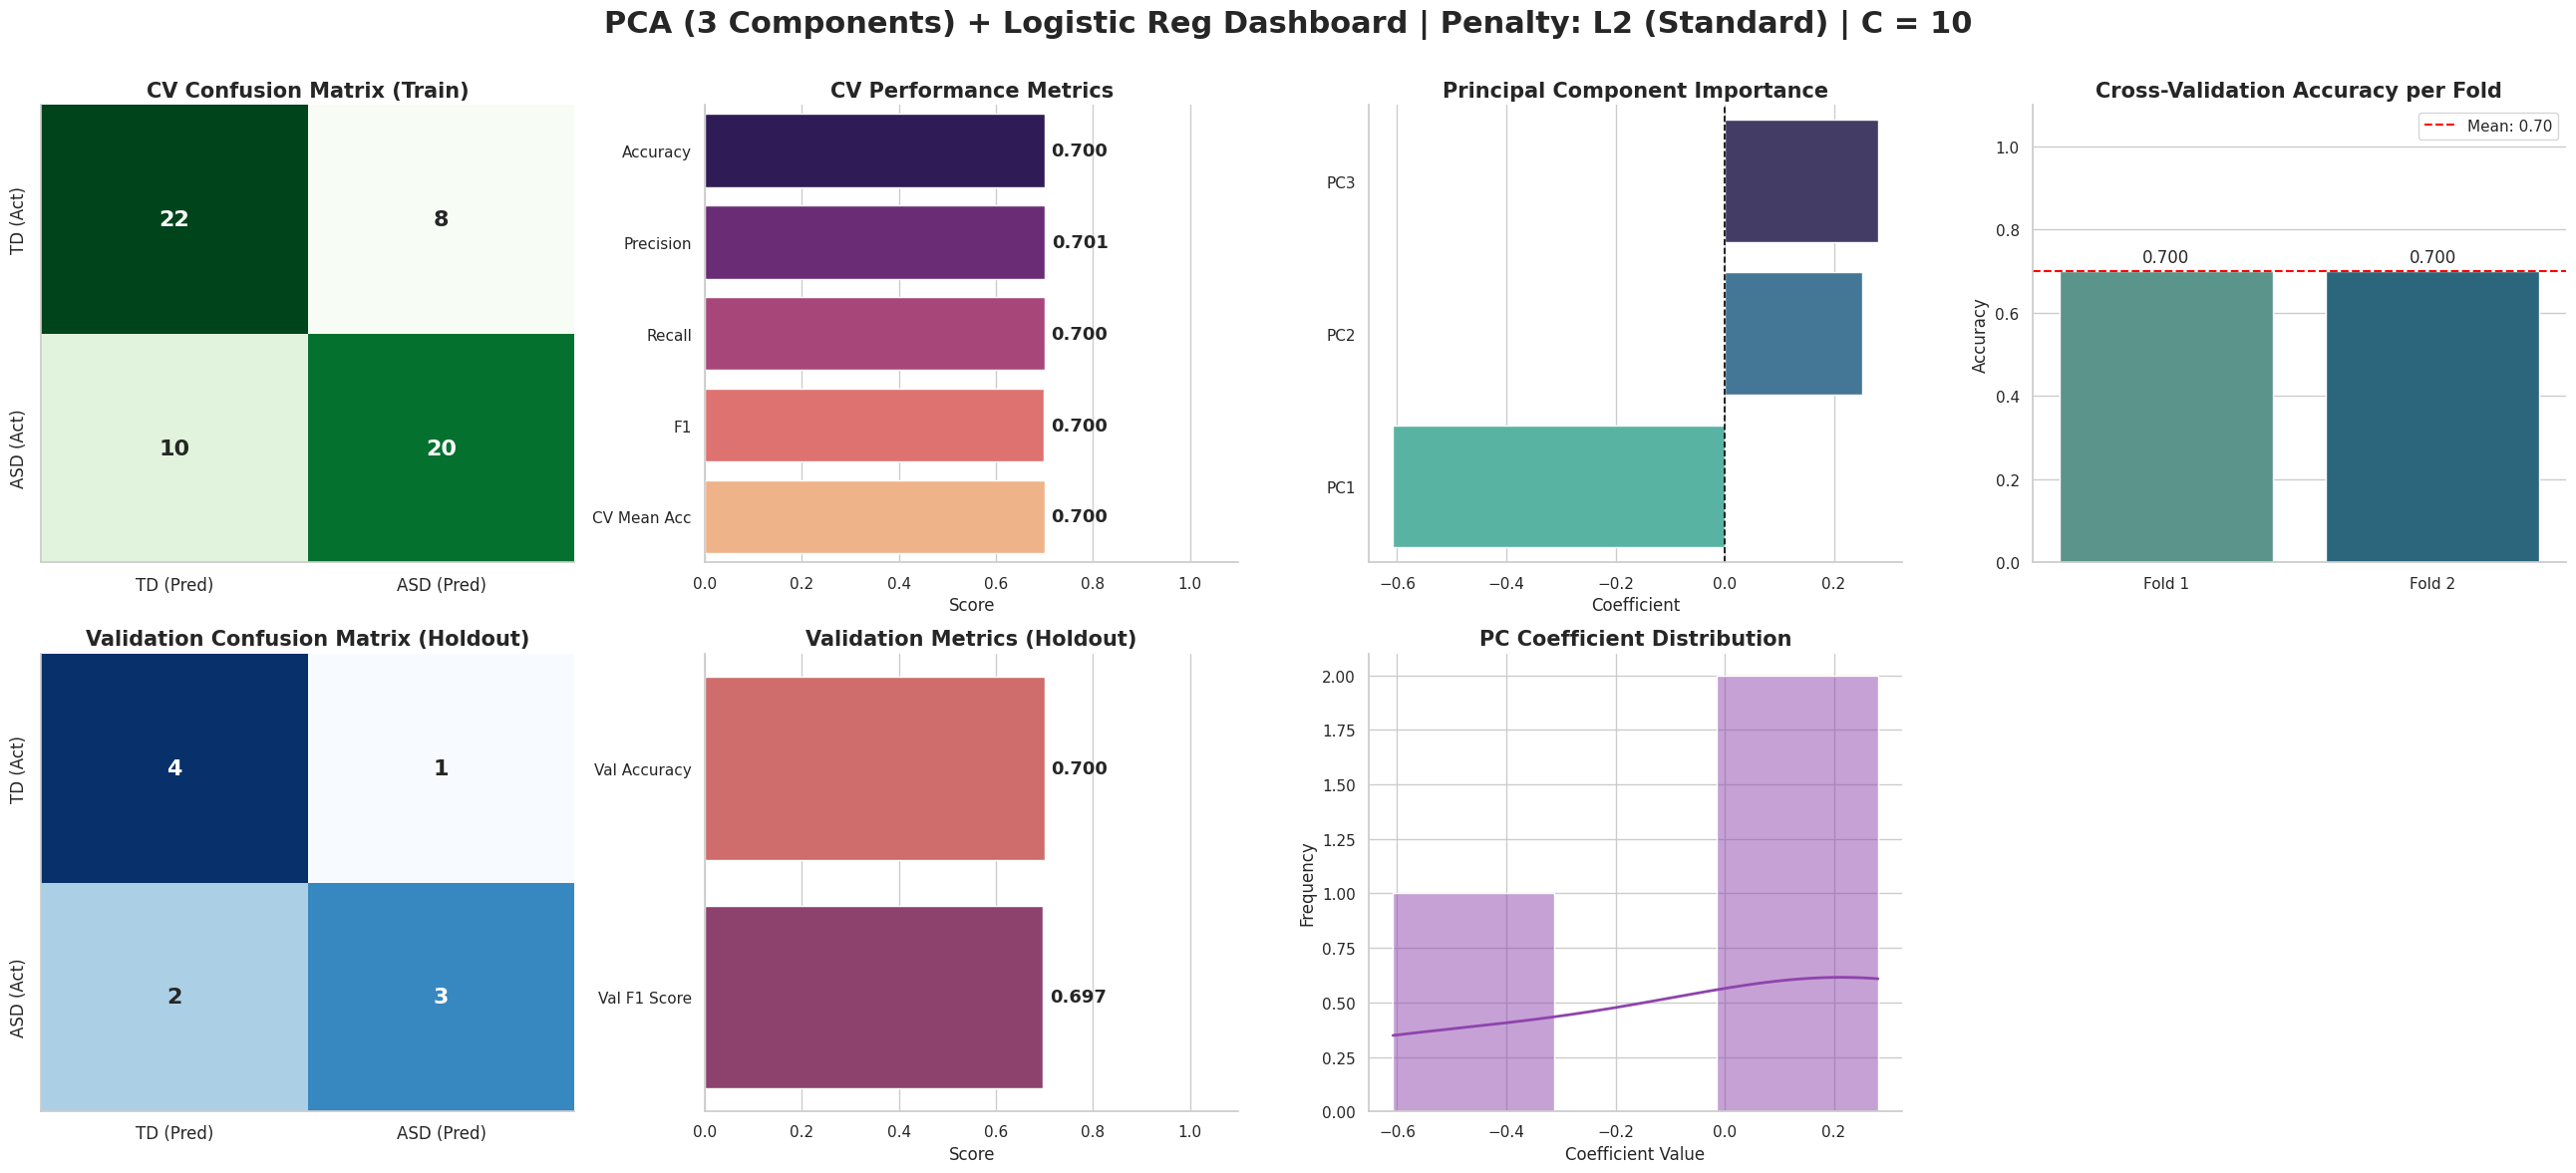

In [88]:
if __name__ == "__main__":
    if not os.path.exists(DATA_PATH):
        print(f"Error: '{DATA_PATH}' not found.")
    else:
        # Load and prepare data ONCE before the loop starts
        df = pd.read_csv(DATA_PATH)
        X_train, X_val, y_train, y_val = prepare_data(df)
        
        c_values = [0, 0.1, 0.5, 0.75, 1, 10]
        
        for c in c_values:


            evaluate_logreg_with_pca_kfold(X_train, X_val, y_train, y_val, K_FOLDS=2, use_l1=True, C_value=c, n_components=3)
            
            if c == 0:
                print("\nSkipping Experiment 2 for C=0 (No Regularization) as it is equivalent to L1.")
                continue
            evaluate_logreg_with_pca_kfold(X_train, X_val, y_train, y_val, K_FOLDS=2, use_l1=False, C_value=c, n_components=3)

In [115]:
def evaluate_feature_pruning_with_visuals(X_train, X_val, y_train, y_val, K_FOLDS=5, use_l1=False, C_value=1.0, max_iter=10000):
    """
    Iteratively prunes the feature with the smallest absolute weight.
    For each iteration, displays a side-by-side 1x2 subplot:
        - Left: Feature Coefficients (Red = Dropped)
        - Right: CV Accuracies per Fold
    Concludes with a final Accuracy vs. Number of Features summary plot.
    """
    # 1. Handle scikit-learn 1.8+ penalty rules
    if C_value == 0 or C_value is None:
        c_setting = np.inf
        l1_ratio_setting = None
        penalty_display = "None (λ=0)"
    else:
        c_setting = C_value
        l1_ratio_setting = 1.0 if use_l1 else 0.0 
        penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
    
    # 2. Trackers for our final summary plot
    history = {
        "Num_Features": [],
        "CV_Accuracy": [],
        "Val_Accuracy": [],
        "Dropped_Feature": []
    }
    
    current_X_train = X_train.copy()
    current_X_val = X_val.copy()
    cv_strategy = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    sns.set_theme(style="whitegrid", palette="muted")
    print(f"Starting Visual Pruning Loop (Penalty: {penalty_display}, C={C_value})...")
    print("-" * 60)
    
    # 3. Begin Pruning Loop
    while current_X_train.shape[1] > 0:
        num_feats = current_X_train.shape[1]
        
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('log_reg', LogisticRegression(
                l1_ratio=l1_ratio_setting,       
                C=c_setting,                
                solver='saga',          
                max_iter=max_iter, 
                random_state=42
            ))
        ])
        
        # Evaluate CV and Validation Accuracy
        cv_scores = cross_val_score(pipeline, current_X_train, y_train, cv=cv_strategy, scoring='accuracy')
        cv_acc = cv_scores.mean()
        
        pipeline.fit(current_X_train, y_train)
        y_val_pred = pipeline.predict(current_X_val)
        val_acc = accuracy_score(y_val, y_val_pred)
        
        # Extract coefficients and find the minimum absolute weight
        coefs = pipeline.named_steps['log_reg'].coef_[0]
        abs_coefs = np.abs(coefs)
        min_idx = np.argmin(abs_coefs)
        feature_to_drop = current_X_train.columns[min_idx]
        
        # =====================================================================
        # --- PER-ITERATION SUBPLOTS (1 Row, 2 Columns) ---
        # =====================================================================
        if num_feats > 1:
            # Dataframe for coefficients
            iter_df = pd.DataFrame({
                'Feature': current_X_train.columns,
                'Coefficient': coefs,
                'Abs_Coef': abs_coefs
            }).sort_values(by='Abs_Coef', ascending=False)
            
            # Dataframe for folds
            fold_df = pd.DataFrame({
                "Fold": [f"Fold {i+1}" for i in range(K_FOLDS)],
                "Accuracy": cv_scores
            })
            
            # Color the dropped feature red, the rest blue
            custom_palette = {feat: '#e74c3c' if feat == feature_to_drop else '#3498db' for feat in iter_df['Feature']}
            
            # Create the 1x2 Subplot Grid dynamically
            plot_height = max(4.5, num_feats * 0.35) 
            fig, axes = plt.subplots(1, 2, figsize=(16, plot_height))
            
            fig.suptitle(f'Iteration: {num_feats} Features Remaining | Dropping Next: [{feature_to_drop}]', 
                         fontsize=16, fontweight='bold', y=1.02)
            
            # --- LEFT SUBPLOT: Feature Coefficients ---
            sns.barplot(
                x='Coefficient', y='Feature', data=iter_df, 
                hue='Feature', palette=custom_palette, legend=False, ax=axes[0]
            )
            axes[0].set_title('Feature Weights (Red = Weakest Link)', fontsize=14)
            axes[0].axvline(x=0, color='black', linewidth=1.2, linestyle='--')
            axes[0].set_xlabel('Coefficient Value', fontsize=12)
            axes[0].set_ylabel('')
            
            # --- RIGHT SUBPLOT: Per-Fold Accuracy ---
            sns.barplot(
                x='Fold', y='Accuracy', data=fold_df, 
                hue='Fold', palette='crest', legend=False, ax=axes[1]
            )
            axes[1].set_title('Cross-Validation Metrics (Per Fold)', fontsize=14)
            axes[1].set_ylim(0, 1.1)
            axes[1].set_xlabel('')
            axes[1].set_ylabel('Accuracy')
            
            # Add mean line and exact values to the fold bars
            axes[1].axhline(cv_acc, color='red', linestyle='--', linewidth=1.5, label=f'Mean CV Acc: {cv_acc:.3f}')
            axes[1].legend(loc='upper right')
            for i in axes[1].containers:
                axes[1].bar_label(i, fmt='%.3f', padding=4, size=11)
            
            sns.despine()
            plt.tight_layout()
            plt.show() 
            
            # Free memory so Jupyter doesn't crash from holding too many plots
            plt.close(fig)
        
        # Log results for this iteration
        history["Num_Features"].append(num_feats)
        history["CV_Accuracy"].append(cv_acc)
        history["Val_Accuracy"].append(val_acc)
        history["Dropped_Feature"].append(feature_to_drop if num_feats > 1 else "Last Feature Remaining")
        
        # Drop the weakest feature to prepare for the next iteration
        current_X_train = current_X_train.drop(columns=[feature_to_drop])
        current_X_val = current_X_val.drop(columns=[feature_to_drop])

    # Convert results to DataFrame
    history_df = pd.DataFrame(history)
    
    # =========================================================================
    # --- FINAL SUMMARY PLOT: Accuracy vs. Number of Features ---
    # =========================================================================
    plt.figure(figsize=(14, 7))
    
    # Plot CV and Validation Trajectories
    sns.lineplot(data=history_df, x='Num_Features', y='CV_Accuracy', marker='o', linewidth=2.5, label='CV Accuracy (Train)', color='#2980b9')
    sns.lineplot(data=history_df, x='Num_Features', y='Val_Accuracy', marker='s', linewidth=2.5, label='Validation Accuracy (Holdout)', color='#c0392b')
    
    # Reverse X-axis to read naturally (Many features -> 1 feature)
    plt.gca().invert_xaxis()
    
    plt.title(f'Feature Pruning Summary: Accuracy vs. Remaining Features (C = {C_value})', fontsize=18, fontweight='bold')
    plt.xlabel('Number of Features Remaining', fontsize=14, fontweight='bold')
    plt.ylabel('Accuracy Score', fontsize=14, fontweight='bold')
    
    plt.axhline(0.50, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='Random Chance (0.50)')
    
    plt.legend(fontsize=12, loc='lower left')
    plt.ylim(0, 1.05)
    
    sns.despine()
    plt.tight_layout()
    plt.show()
    
    return history_df

Preparing data...
Split complete:
  Training set: 60 subjects (30 Class 1, 30 Class 0)
  Validation set: 10 subjects (5 Class 1, 5 Class 0)
Starting Visual Pruning Loop (Penalty: None (λ=0), C=0)...
------------------------------------------------------------


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

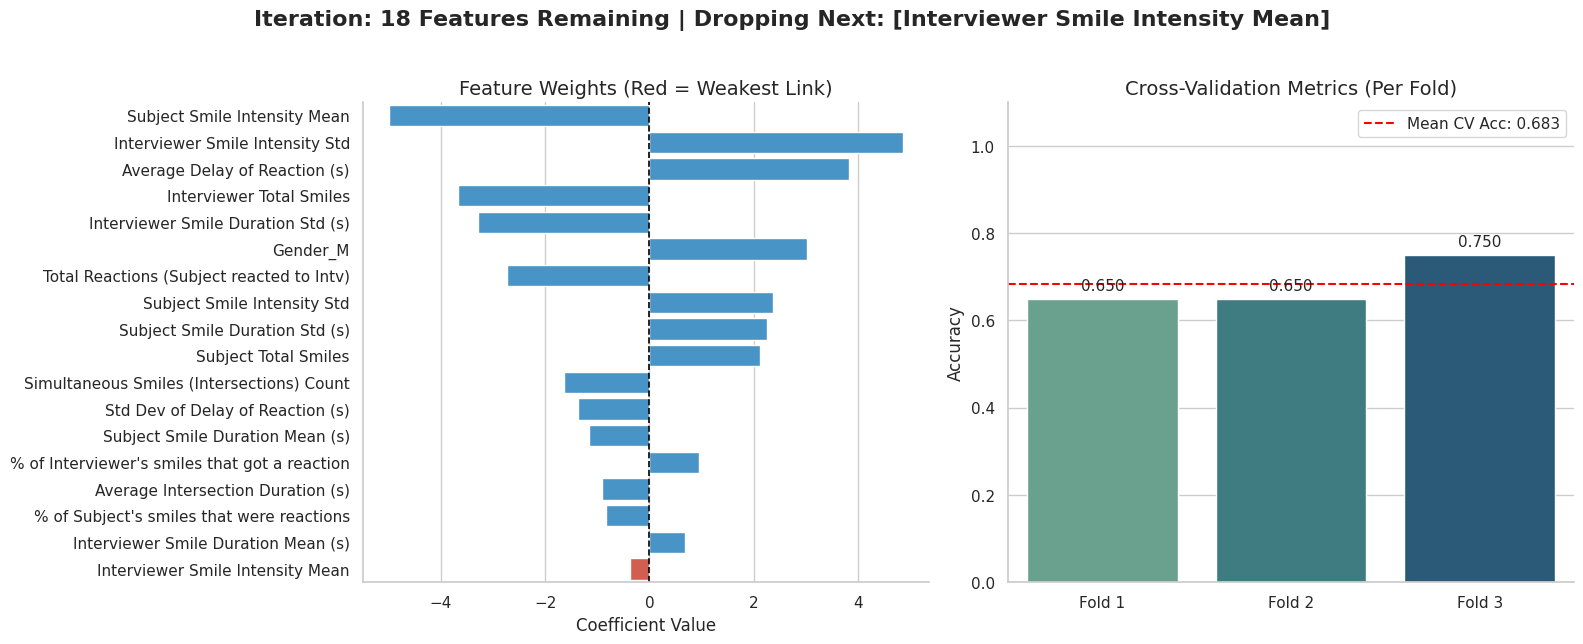

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

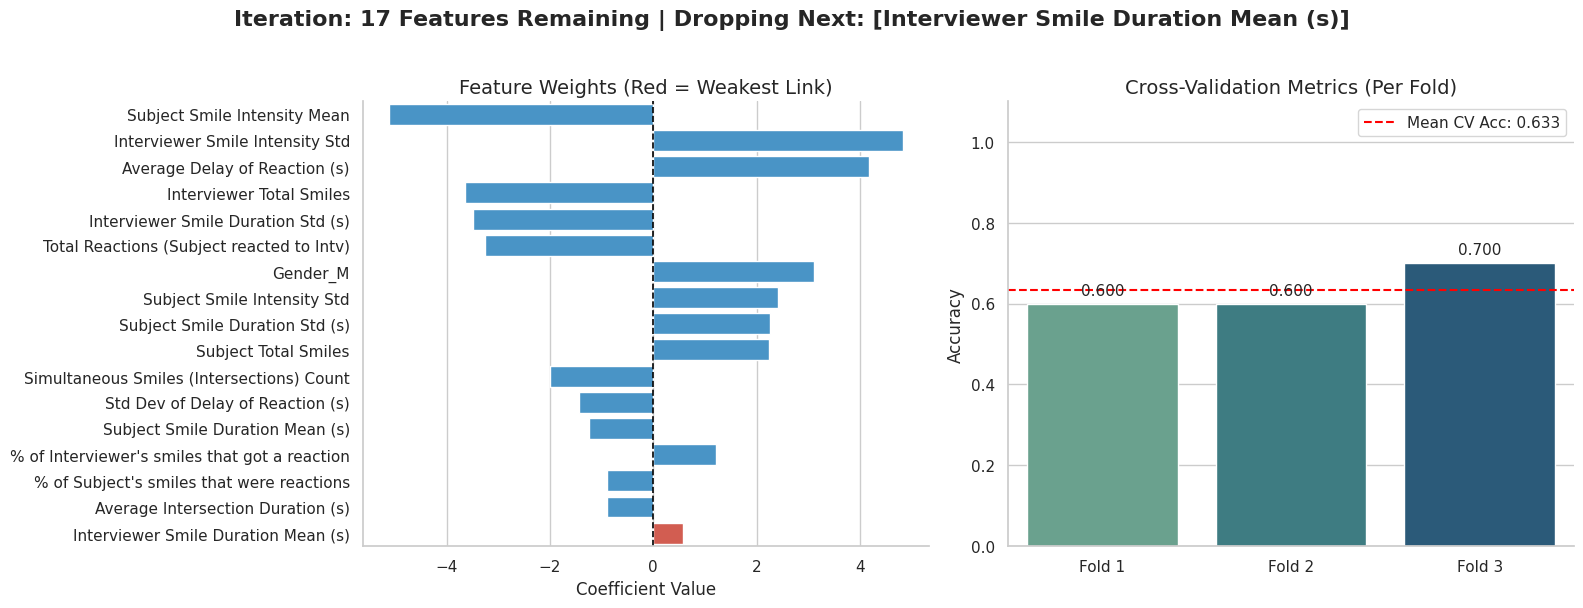

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

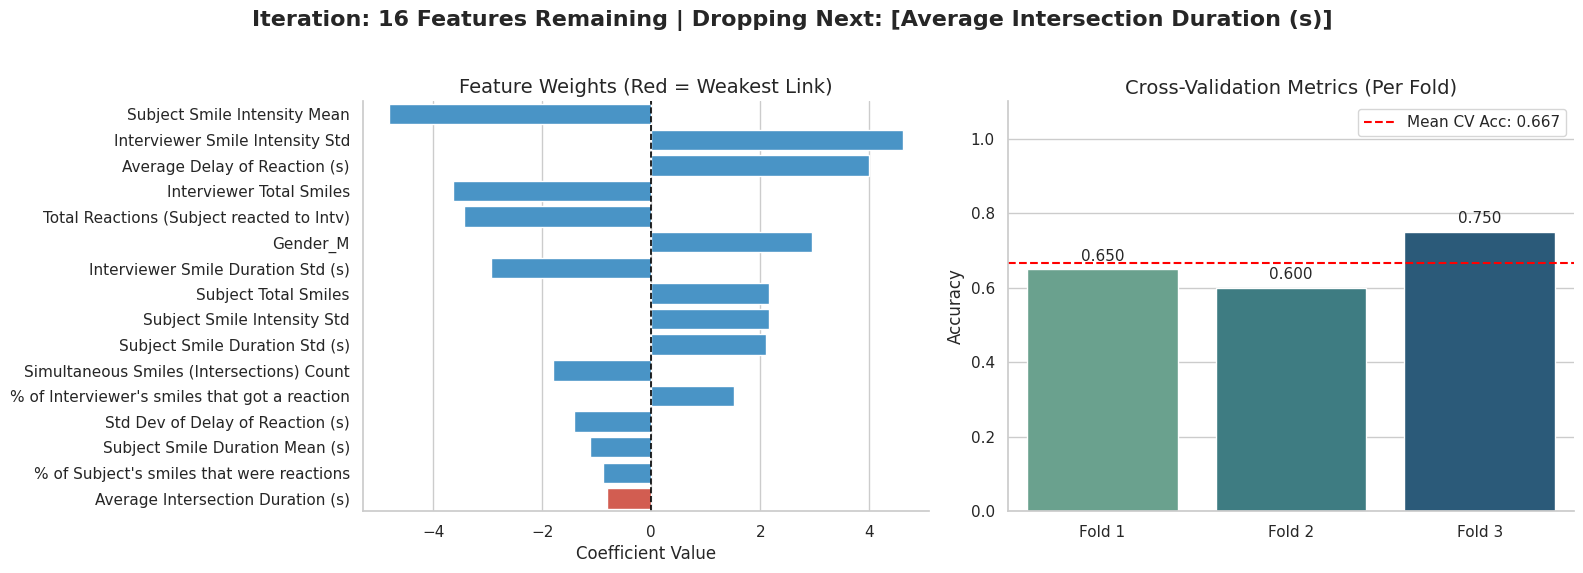

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

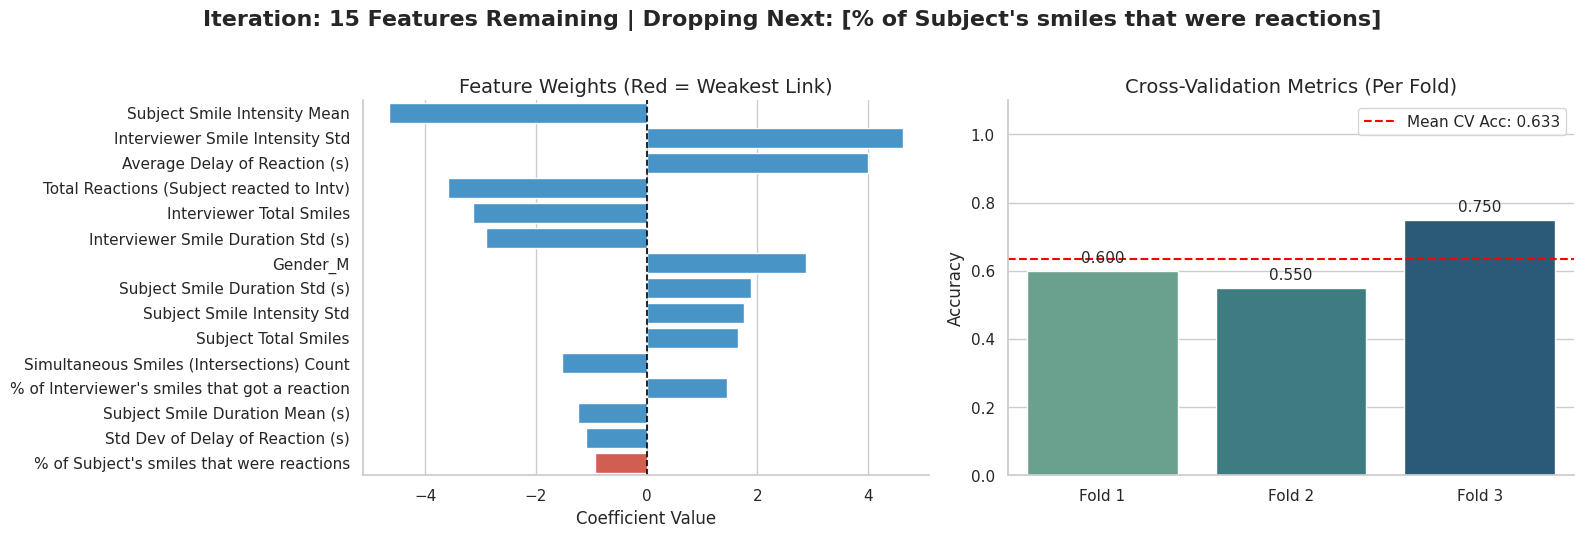

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

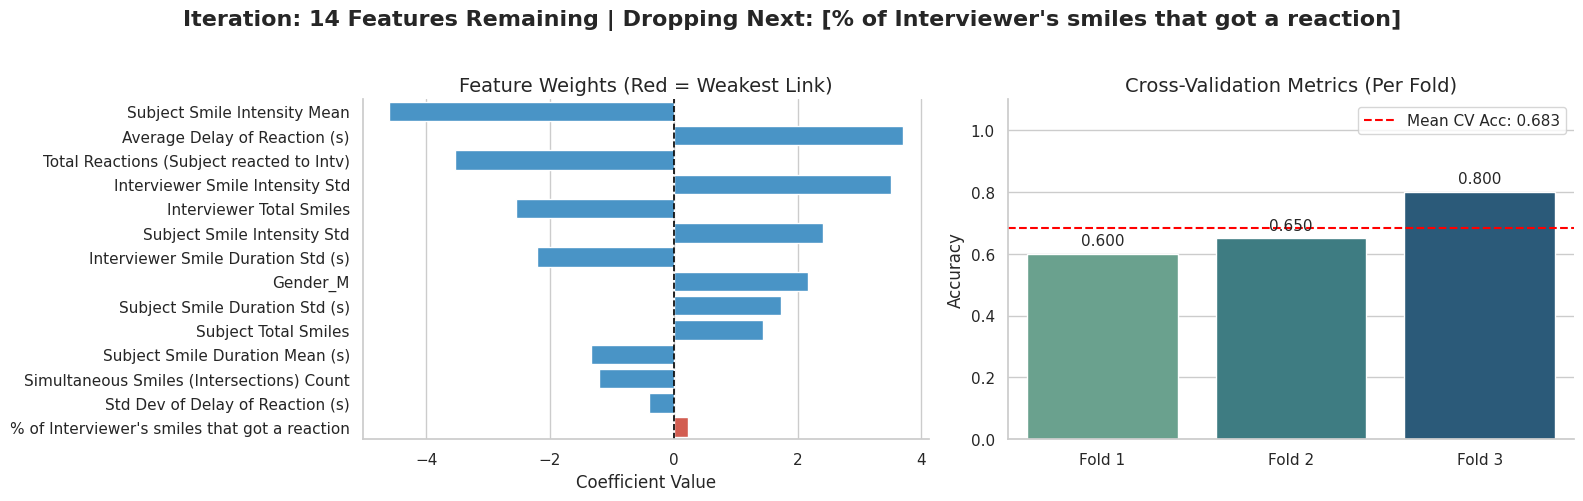

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

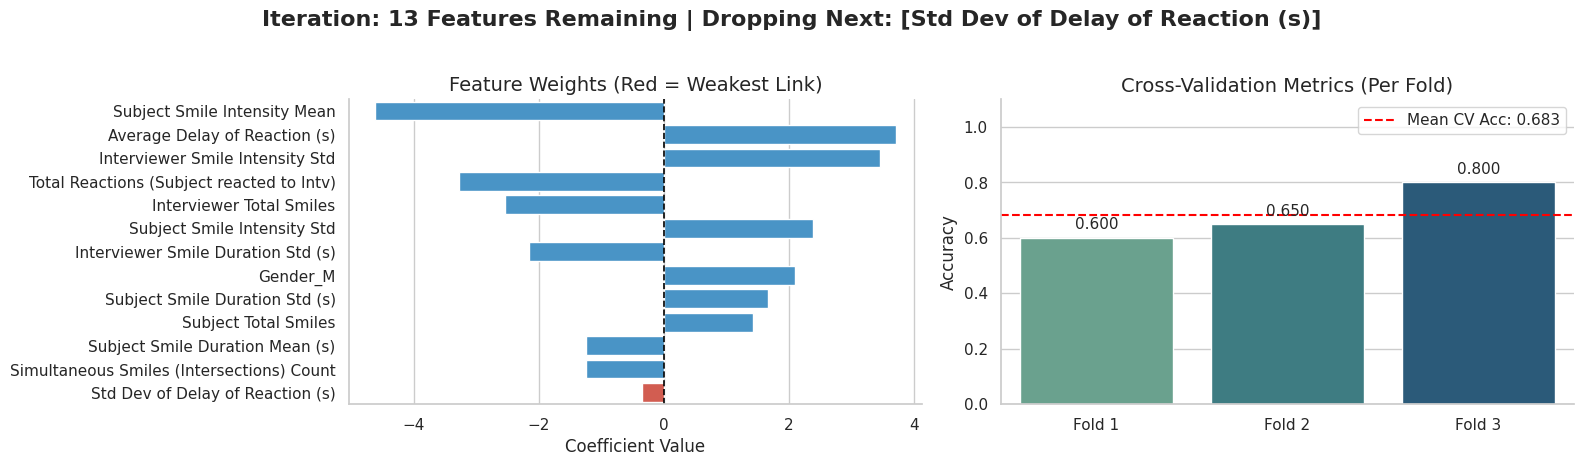

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

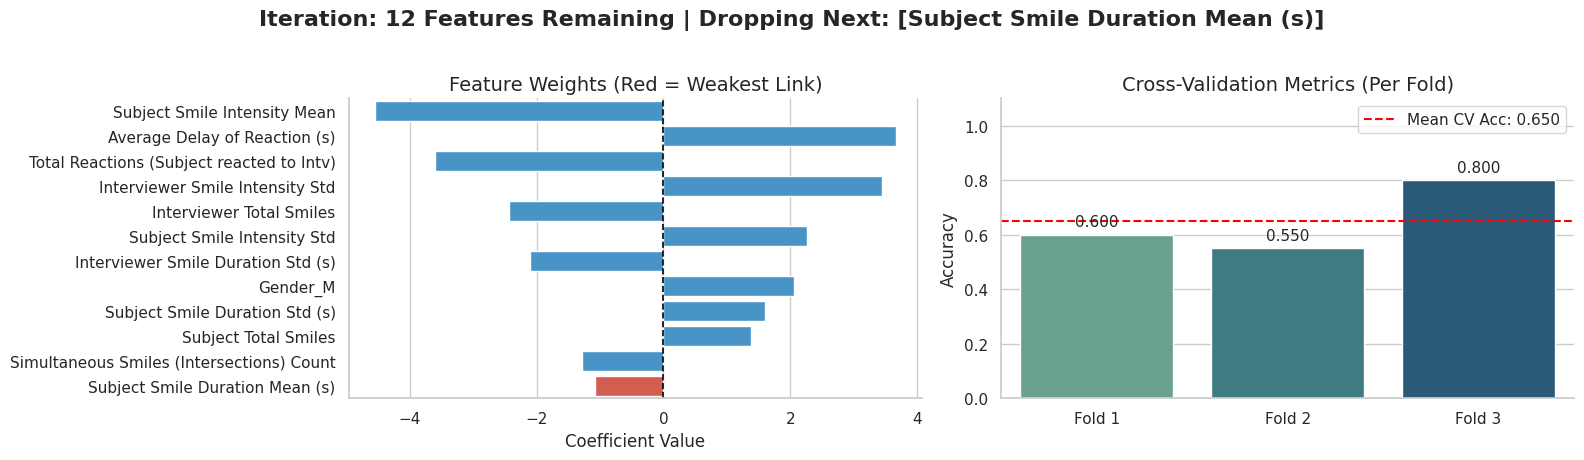

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

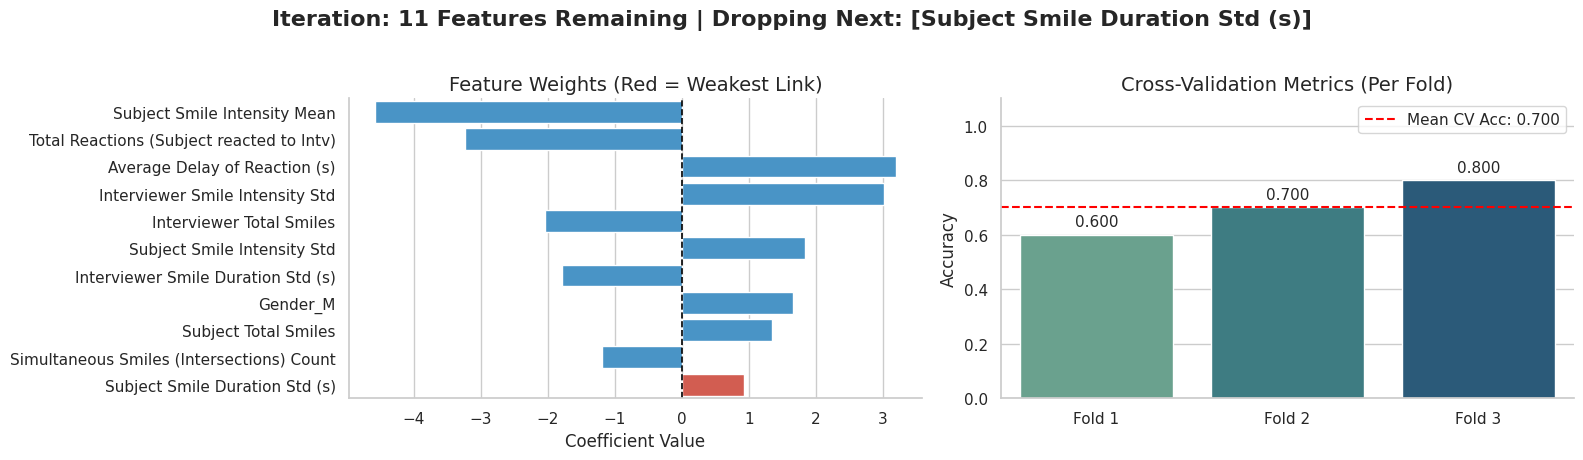

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

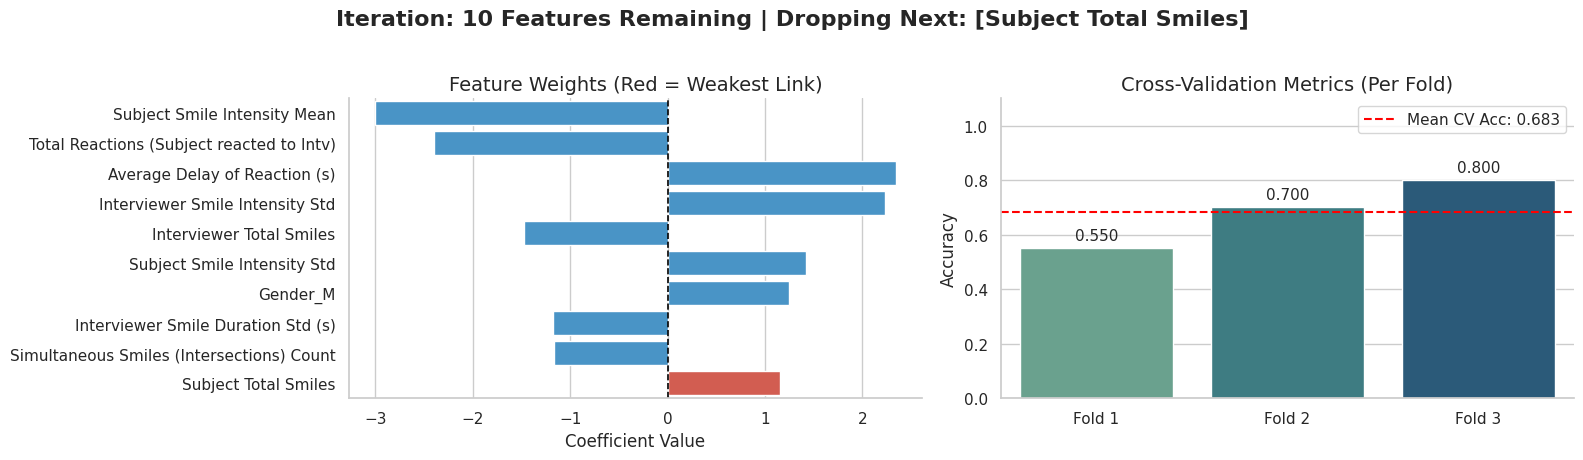

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

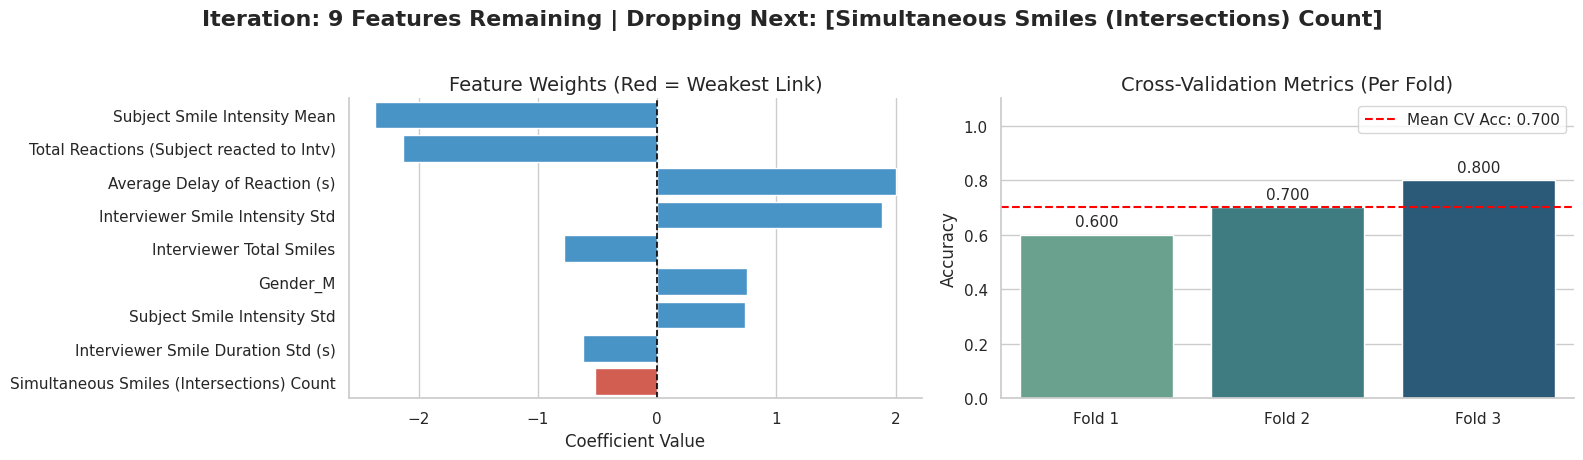

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

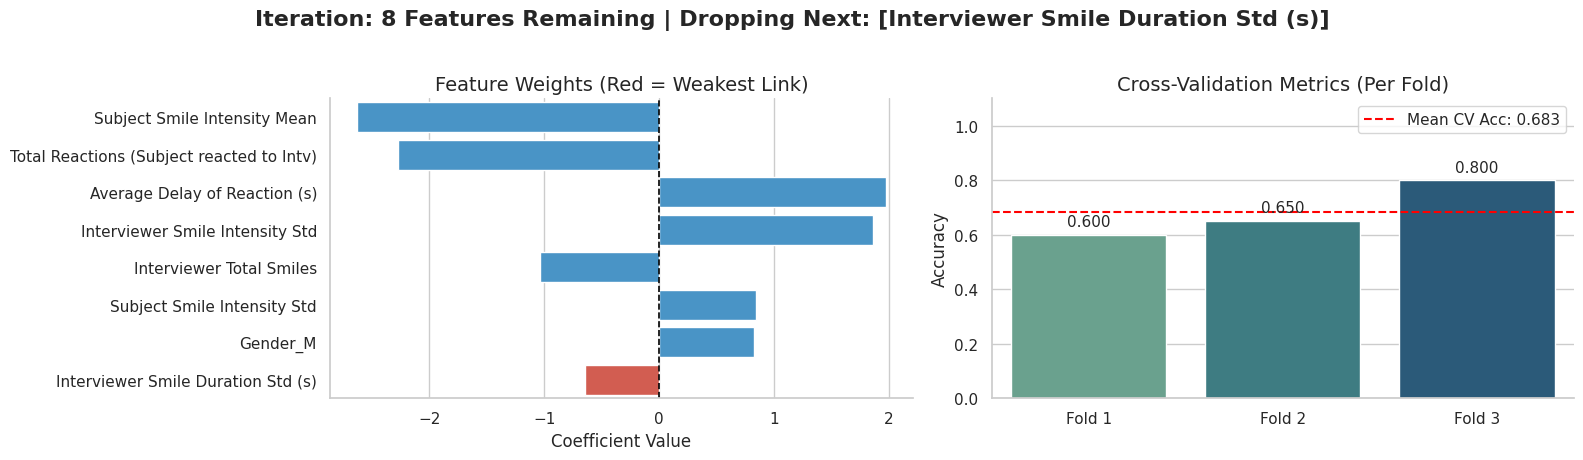

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

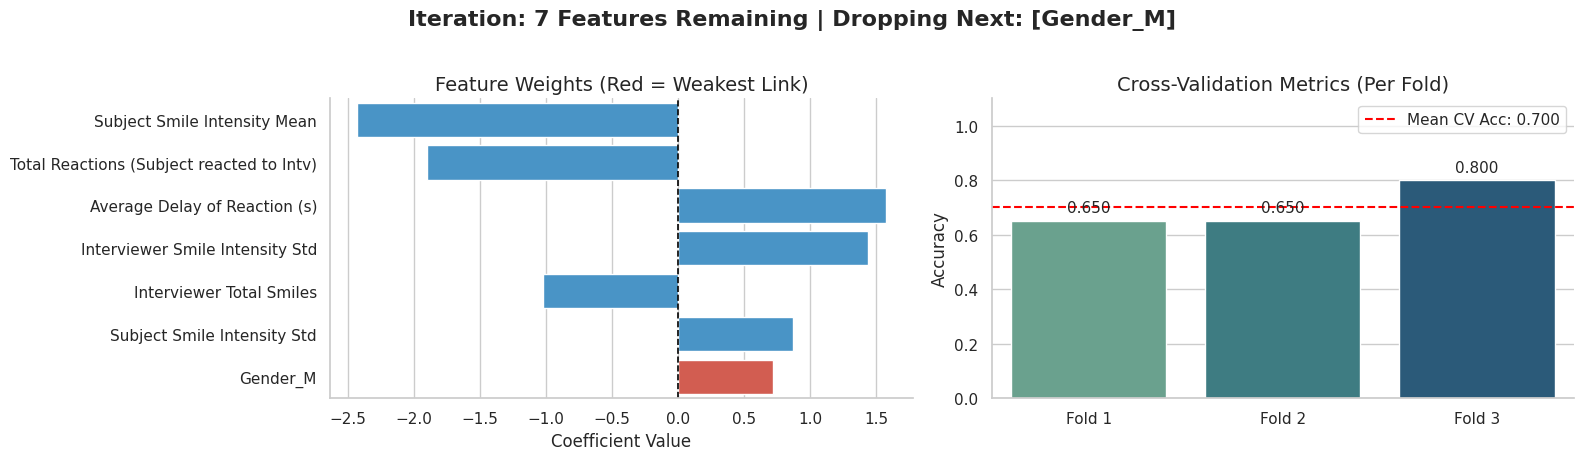

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

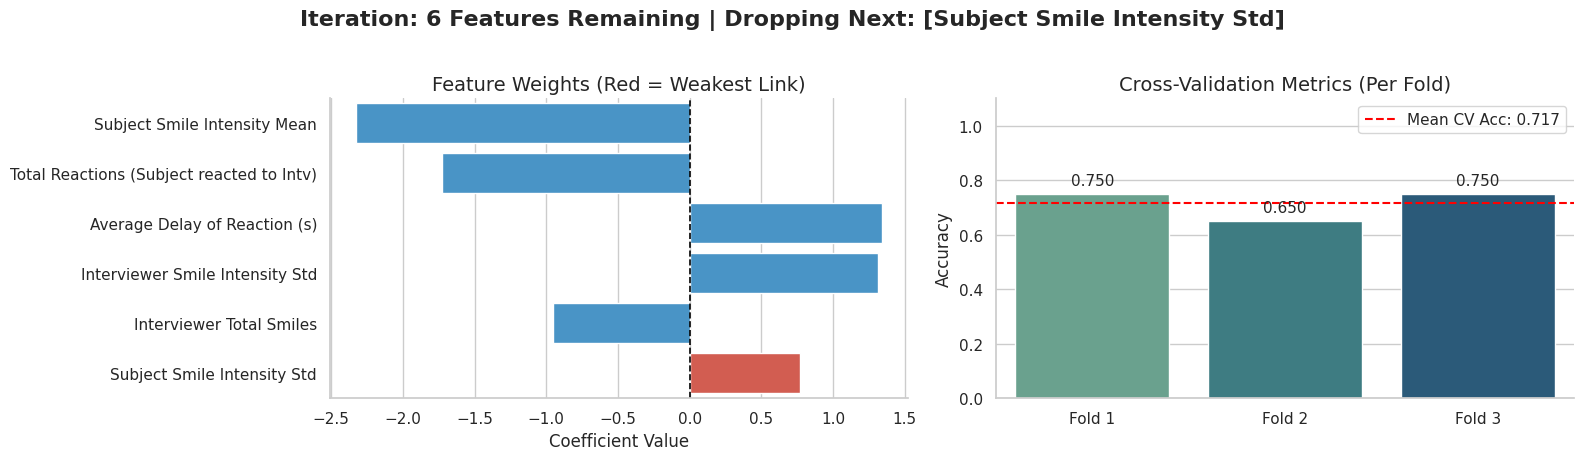

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

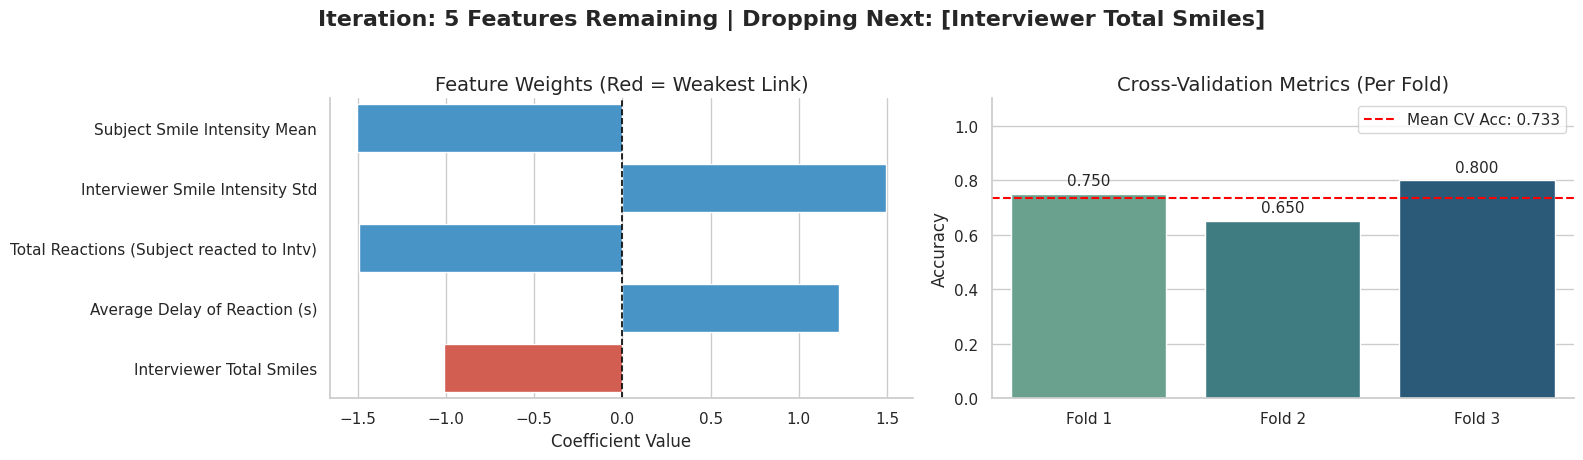

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

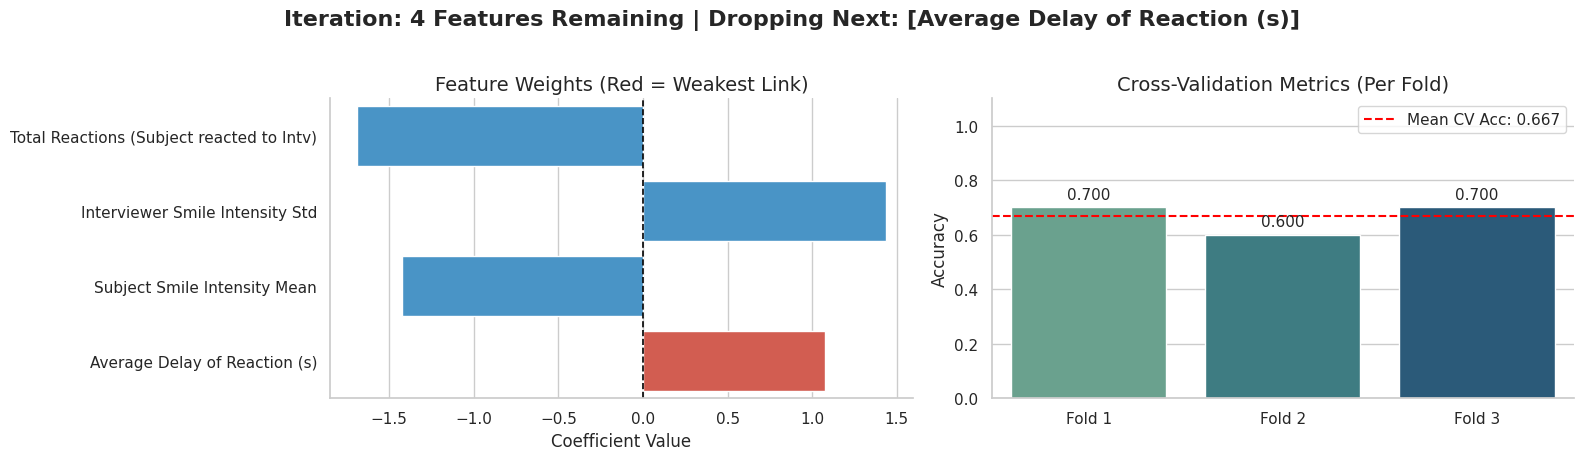

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

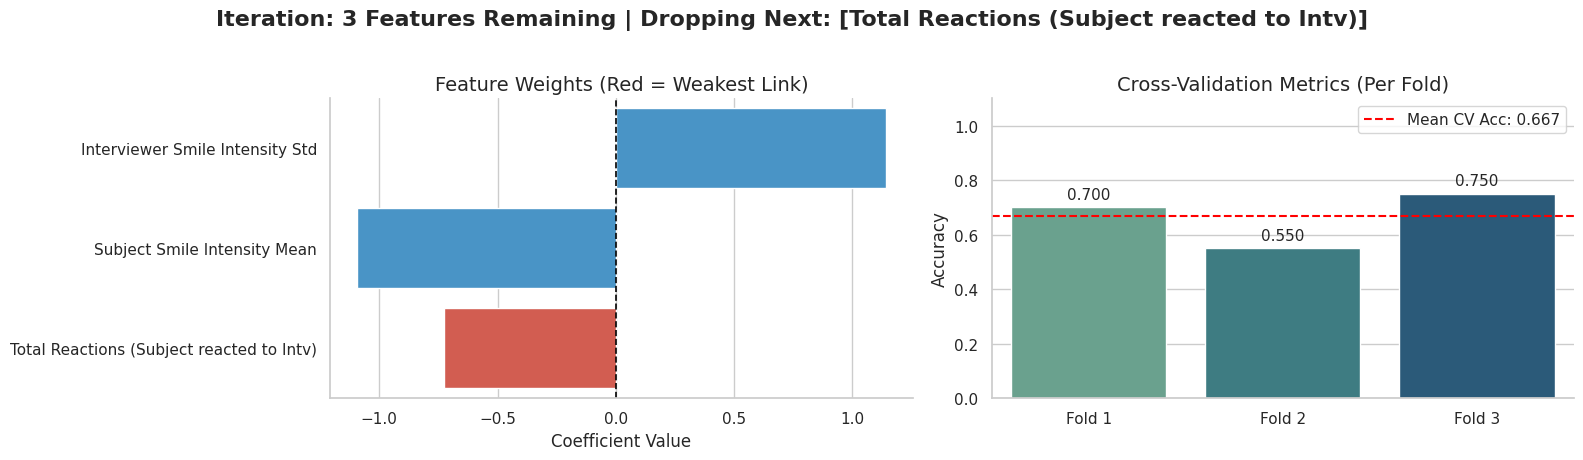

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

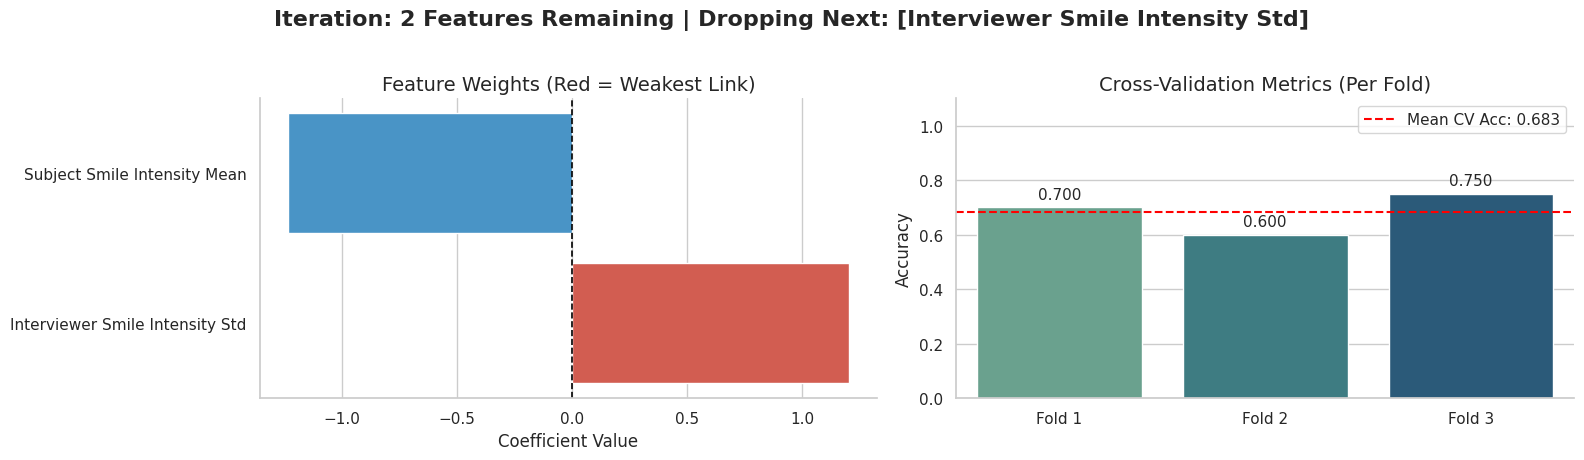

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 1.8 and will trigger an error in 1.10. Use 0<=l1_ratio<=1 instead.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1120: FutureWarning: 'l1_ratio=None' was deprecated in version 

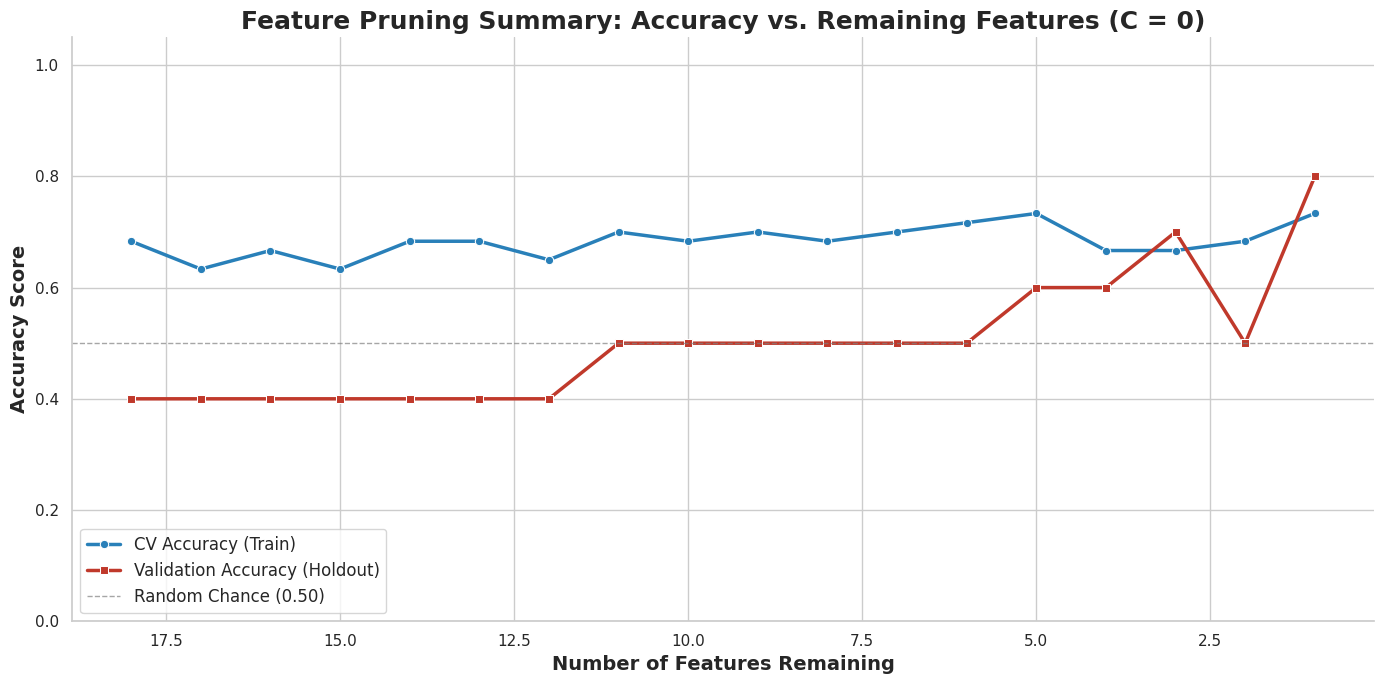

In [116]:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH):
        # Load and prepare data ONCE
        df = pd.read_csv(DATA_PATH)
        X_train, X_val, y_train, y_val = prepare_data(df)
        
        # Run the visual pruning experiment
        pruning_history = evaluate_feature_pruning_with_visuals(X_train, X_val, y_train, y_val, K_FOLDS=3, use_l1=False, C_value=0)